# APRAU 2026/27 - Grupo 08
## Parte 1: Análise Exploratória de Dados (EDA)

**Objetivo geral do trabalho:** aplicar diferentes métodos de *machine learning* a um dataset clínico multidoença, analisar o comportamento dos modelos e interpretar criticamente os resultados.

**Objetivo deste notebook (secção 2 do enunciado):** caracterizar o dataset antes de modelar, identificando propriedades relevantes dos dados e relações entre variáveis. O dataset do grupo tem 2000 registos de pacientes, com duas variáveis-alvo:

- `target_class`: diagnóstico (3 classes: `N`, `HY`, `DI`), usada na classificação;
- `target_regression`: biomarcador laboratorial contínuo, usado na regressão.

**Estrutura (segue os pontos pedidos no enunciado):**

| Secção | Conteúdo | Ponto do enunciado |
|---|---|---|
| 1 | Visão geral do dataset | Dataset assignment |
| 2 | Estatística descritiva | *Descriptive Statistics* |
| 3 | Análise univariada | *Univariate Analysis* |
| 4 | Análise bivariada | *Bivariate Analysis* |
| 5 | Features constantes, redundantes e não informativas | Identificar e justificar |
| 6 | Conclusões | |
| Apêndice | Codificação das variáveis categóricas (preparação para modelação) | |

### Importações e carregamento dos dados

In [47]:
import pandas as pd
from tabulate import tabulate
import math
import re
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler
import time
from pathlib import Path
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    LeaveOneOut,
    cross_val_predict,
    cross_validate,
    cross_val_score,
    KFold
)
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error, 
    r2_score
)

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")


In [48]:
DATA_PATH = Path("Trabalho\\dataset_grupo_08.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Não encontrei dataset_grupo_08.csv. "
        "Coloca o CSV na mesma pasta do notebook ou ajusta DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (2000, 35)

Columns:
['age_level', 'gender', 'bmi_level', 'smoking', 'age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'blood_pressure', 'sugar_consumption', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'education_level', 'employment_status', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative', 'target_regression', 'target_class']


,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,...,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Middle,Male,Obese,Never,44,0.482758,35.70,5.398540,250.000000,5.300000,...,69.000000,122.000000,Primary,Employed,116.000000,9.42,1.015947,160.000000,177.0,HY
1,Mature,Male,Obese,Former,49,0.540230,34.97,6.500000,224.684501,7.060728,...,63.592940,129.354661,Secondary,Unemployed,134.331495,9.42,1.245353,111.000000,80.0,N
2,Young,Male,Underweight,Never,4,0.022989,17.64,6.000000,228.130653,7.080402,...,65.713568,131.542714,Tertiary,Employed,133.010050,9.42,1.156861,130.259429,126.0,N
3,Middle,Male,Underweight,Current,40,0.436781,17.30,5.421429,299.000000,9.500000,...,52.000000,167.000000,Primary,Employed,124.000000,9.42,1.030313,176.000000,190.0,HY
4,Middle,Female,Normal,Current,27,0.287356,24.80,5.374373,277.000000,8.500000,...,31.000000,185.000000,Tertiary,Employed,96.000000,9.42,1.461792,143.000000,175.0,N


---
## 1. Visão geral do dataset

Primeiro contacto com os dados: primeiras e últimas linhas, dimensão, duplicados, valores em falta, tipos de variáveis e cardinalidade. A cardinalidade (nº de valores distintos) ajuda a distinguir variáveis categóricas, discretas e contínuas, e a detetar variáveis constantes ou do tipo identificador.

### 1.1 Primeiras e últimas observações

In [49]:
print(
    f"""
    Head Dataset

    {tabulate(
        df.head(10),
        headers="keys",
        tablefmt="grid",
        showindex=False
    )}
    """
)

print(f"""
Tail Dataset

{tabulate(
    df.tail(10),
    headers="keys",
    tablefmt="grid",
    showindex=False
)}
""")


    Head Dataset

    +-------------+----------+-------------+-----------+-------+------------------+-------+---------------+---------------+---------------+-----------------+---------------------+------------------+----------------+-----------------------+------------------------+------------------+---------------------+-------------+----------------------+---------------+----------------+------------------+---------------+--------------+---------+---------+-------------------+---------------------+------------------+--------------------+----------------+-------------------+---------------------+----------------+
| age_level   | gender   | bmi_level   | smoking   |   age |   age_normalized |   bmi |   HbA1c_level |   cholesterol |   sleep_hours |   triglycerides | physical_activity   | family_history   | stress_level   | low_hdl_cholesterol   | high_ldl_cholesterol   |   blood_pressure | sugar_consumption   |   crp_level |   homocysteine_level |   systolic_bp |   diastolic_bp |   alc

### 1.2 Dimensão, duplicados e valores em falta

In [50]:
# ============================================================
# 1. DATA OVERVIEW
# ============================================================

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print(f"Number of observations: {df.shape[0]}")
print(f"Number of features: {df.shape[1]}")
print("Duplicated rows: " + str(df.duplicated().sum()))
print("\nData types and missing values:")
print(df.info())

DATASET OVERVIEW
Number of observations: 2000
Number of features: 35
Duplicated rows: 0

Data types and missing values:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 35 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age_level             2000 non-null   str    
 1   gender                2000 non-null   str    
 2   bmi_level             2000 non-null   str    
 3   smoking               2000 non-null   str    
 4   age                   2000 non-null   int64  
 5   age_normalized        2000 non-null   float64
 6   bmi                   2000 non-null   float64
 7   HbA1c_level           2000 non-null   float64
 8   cholesterol           2000 non-null   float64
 9   sleep_hours           2000 non-null   float64
 10  triglycerides         2000 non-null   float64
 11  physical_activity     2000 non-null   str    
 12  family_history        2000 non-null   str    
 13  stress_level  

**Leitura:** 2000 observações e 35 colunas (33 features e os 2 alvos), sem linhas duplicadas e sem valores em falta, pelo que não é necessário tratar *missing values* nem remover duplicados.

### 1.3 Tipos de variáveis

In [51]:
# ============================================================
# 2. VARIABLE TYPES
# ============================================================

numeric_cols = df.select_dtypes(include="number").columns
categorical_cols = df.select_dtypes(include="object").columns

print("\n" + "=" * 60)
print("VARIABLE TYPES")
print("=" * 60)

print("\nNumerical variables:")
print(list(numeric_cols))

print("\nCategorical variables:")
print(list(categorical_cols))



VARIABLE TYPES

Numerical variables:
['age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative', 'target_regression']

Categorical variables:
['age_level', 'gender', 'bmi_level', 'smoking', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'sugar_consumption', 'education_level', 'employment_status', 'target_class']


C:\Users\moale\AppData\Local\Temp\ipykernel_58580\2444264265.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns


**Leitura:** 21 features numéricas (mais `target_regression`) e 12 features categóricas (mais `target_class`). As categóricas ordinais (`bmi_level`, `physical_activity`, `stress_level`, `sugar_consumption`, `age_level`, ...) têm uma ordem natural, que é respeitada nos gráficos seguintes.

### 1.4 Cardinalidade

In [52]:
# ============================================================
# 3. CARDINALITY
# ============================================================

print("\n" + "=" * 60)
print("CARDINALITY")
print("=" * 60)

cardinality = pd.DataFrame({
    "Unique Values": df.nunique(),
    "Unique Percentage": df.nunique() / len(df) * 100,
    "type": list(df.dtypes)
})

display(cardinality.sort_values("Unique Values"))


CARDINALITY


,Unique Values,Unique Percentage,type
calcium_baseline,1,0.05,float64
gender,2,0.10,str
high_ldl_cholesterol,2,0.10,str
family_history,2,0.10,str
low_hdl_cholesterol,2,0.10,str
physical_activity,3,0.15,str
stress_level,3,0.15,str
smoking,3,0.15,str
employment_status,3,0.15,str
education_level,3,0.15,str


**Leitura:**
- `calcium_baseline` tem **um único valor** em todo o dataset (constante).
- `plasma_value` tem 100% de valores únicos, mas é uma medição contínua (0,68 a 1,75) e não um identificador.
- `systolic_bp`/`systolic_index` (213 valores), `age`/`age_normalized` e `ldl`/`ldl_alternative` (242 valores) têm cardinalidades iguais ou muito próximas, o que levanta suspeita de redundância (analisada na secção 5).

---
## 2. Estatística descritiva

Medidas de tendência central, dispersão e forma (assimetria e curtose) para as variáveis numéricas, e frequências para as categóricas. Inclui a caracterização das duas variáveis-alvo.

### 2.1 Variáveis numéricas

In [53]:
# ============================================================
# 4. DESCRIPTIVE STATISTICS - NUMERICAL VARIABLES
# ============================================================

print("\n" + "=" * 60)
print("DESCRIPTIVE STATISTICS - NUMERICAL VARIABLES")
print("=" * 60)

numeric_stats = pd.DataFrame({
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Std": df[numeric_cols].std(),
    "Min": df[numeric_cols].min(),
    "Q1": df[numeric_cols].quantile(0.25),
    "Q3": df[numeric_cols].quantile(0.75),
    "Max": df[numeric_cols].max(),
    "IQR": (
        df[numeric_cols].quantile(0.75)
        - df[numeric_cols].quantile(0.25)
    ),
    "Skewness": df[numeric_cols].skew(),
    "Kurtosis": df[numeric_cols].kurtosis()
})

display(numeric_stats.round(3))



DESCRIPTIVE STATISTICS - NUMERICAL VARIABLES


,Mean,Median,Std,Min,Q1,Q3,Max,IQR,Skewness,Kurtosis
age,48.262,48.000,21.902,2.000,31.000,66.000,89.000,35.000,-0.021,-0.950
age_normalized,0.532,0.529,0.252,0.000,0.333,0.736,1.000,0.402,-0.021,-0.950
bmi,27.458,27.320,7.172,12.370,21.900,32.515,87.700,10.615,0.671,2.621
HbA1c_level,5.644,5.420,0.893,3.500,5.349,6.200,9.000,0.851,0.123,1.105
cholesterol,223.165,224.685,33.120,150.000,206.000,232.000,299.000,26.000,0.067,0.037
sleep_hours,6.923,6.966,1.351,4.000,6.485,7.300,10.000,0.815,0.035,0.042
triglycerides,182.474,183.000,66.656,50.000,137.000,243.640,399.000,106.640,-0.186,-0.873
blood_pressure,149.659,149.588,3.427,120.000,148.625,150.605,177.000,1.980,-0.522,24.144
crp_level,7.516,7.414,0.913,0.058,7.295,7.759,14.995,0.464,0.159,26.895
homocysteine_level,12.520,12.509,0.936,5.097,12.305,12.691,19.946,0.386,1.467,26.610


**Leitura:**
- `age_normalized` é a idade em escala 0-1 e `systolic_index` tem exatamente as mesmas estatísticas de `systolic_bp`.
- `ldl` e `ldl_alternative` têm também estatísticas idênticas.
- `blood_pressure`, `crp_level` e `homocysteine_level` têm curtose entre 24 e 27 e um IQR muito pequeno, ou seja, valores muito concentrados em torno da mediana com algumas caudas extremas.
- `calcium_baseline` tem desvio-padrão 0.

### 2.2 Variáveis categóricas

In [54]:
# ============================================================
# 5. DESCRIPTIVE STATISTICS - CATEGORICAL VARIABLES
# ============================================================

print("\n" + "=" * 60)
print("DESCRIPTIVE STATISTICS - CATEGORICAL VARIABLES")
print("=" * 60)

categorical_summary = []

for col in categorical_cols:
    counts = df[col].value_counts()

    categorical_summary.append({
        "Variable": col,
        "Categories": df[col].nunique(),

        "Most Frequent": counts.index[0],
        "Most Frequent Count": counts.iloc[0],
        "Most Frequent %": counts.iloc[0] / len(df) * 100,

        "Least Frequent": counts.index[-1],
        "Least Frequent Count": counts.iloc[-1],
        "Least Frequent %": counts.iloc[-1] / len(df) * 100
    })

categorical_summary = pd.DataFrame(categorical_summary)

display(categorical_summary)


DESCRIPTIVE STATISTICS - CATEGORICAL VARIABLES


,Variable,Categories,Most Frequent,Most Frequent Count,Most Frequent %,Least Frequent,Least Frequent Count,Least Frequent %
0,age_level,4,Middle,608,30.40,Young,319,15.95
1,gender,2,Female,1065,53.25,Male,935,46.75
2,bmi_level,4,Obese,670,33.50,Underweight,226,11.30
3,smoking,3,Never,933,46.65,Current,493,24.65
4,physical_activity,3,High,923,46.15,Low,510,25.50
5,family_history,2,No,1157,57.85,Yes,843,42.15
6,stress_level,3,High,761,38.05,Medium,606,30.30
7,low_hdl_cholesterol,2,No,1584,79.20,Yes,416,20.80
8,high_ldl_cholesterol,2,Yes,1042,52.10,No,958,47.90
9,sugar_consumption,3,Low,947,47.35,High,452,22.60


In [55]:
# ------------------------------------------------------------
# DETAILED FREQUENCY TABLES FOR CATEGORICAL VARIABLES
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("DETAILED FREQUENCY TABLES FOR CATEGORICAL VARIABLES")
print("=" * 60)

for col in categorical_cols:
    freq_df = pd.DataFrame({
        'Count': df[col].value_counts(),
        'Percentage (%)': (df[col].value_counts(normalize=True) * 100).round(2)
    })
    print(f"\n--- Variable: {col} ---")
    display(freq_df)


DETAILED FREQUENCY TABLES FOR CATEGORICAL VARIABLES

--- Variable: age_level ---


,Count,Percentage (%)
age_level,,
Middle,608,30.40
Mature,605,30.25
Senior,468,23.40
Young,319,15.95



--- Variable: gender ---


,Count,Percentage (%)
gender,,
Female,1065,53.25
Male,935,46.75



--- Variable: bmi_level ---


,Count,Percentage (%)
bmi_level,,
Obese,670,33.5
Overweight,580,29.0
Normal,524,26.2
Underweight,226,11.3


... (16 outputs left out)


--- Variable: employment_status ---


,Count,Percentage (%)
employment_status,,
Unemployed,699,34.95
Retired,677,33.85
Employed,624,31.20



--- Variable: target_class ---


,Count,Percentage (%)
target_class,,
N,998,49.90
HY,669,33.45
DI,333,16.65


**Leitura:** as features categóricas estão razoavelmente equilibradas (a categoria mais frequente varia entre cerca de 30% e 58%), com exceção de `low_hdl_cholesterol` (79% `No`). Nenhuma é quase constante.

### 2.3 Variáveis-alvo

**`target_class` (classificação).** O dataset está **desbalanceado**: as classes têm 998 (`N`), 669 (`HY`) e 333 (`DI`) registos. Isto obriga a escolher métricas adequadas (por exemplo F1 macro e recall por classe, e não só *accuracy*) e a usar amostragem estratificada nas partições.

In [56]:
# ============================================================
# 6. TARGET CLASS DISTRIBUTION
# ============================================================

print("\n" + "=" * 60)
print("TARGET CLASS DISTRIBUTION")
print("=" * 60)

class_summary = pd.DataFrame({
    "Count": df["target_class"].value_counts(),
    "Percentage": (
        df["target_class"]
        .value_counts(normalize=True) * 100
    )
})

print(class_summary)

class_ratio = (
    df["target_class"].value_counts().max()
    / df["target_class"].value_counts().min()
)

print(f"\nMajority/Minority ratio: {class_ratio:.2f}")



TARGET CLASS DISTRIBUTION
              Count  Percentage
target_class                   
N               998       49.90
HY              669       33.45
DI              333       16.65

Majority/Minority ratio: 3.00


**`target_regression` (regressão).** Variável contínua entre 70 e 300, com média 133,9, mediana 136 e desvio-padrão 38,7. A assimetria é moderada (0,47).

In [57]:
# ============================================================
# 7. TARGET REGRESSION
# ============================================================

print("\n" + "=" * 60)
print("TARGET REGRESSION")
print("=" * 60)

print(df["target_regression"].describe())

print(
    f"\nSkewness: "
    f"{df['target_regression'].skew():.3f}"
)

print(
    f"Number of unique values: "
    f"{df['target_regression'].nunique()}"
)


TARGET REGRESSION
count    2000.000000
mean      133.933000
std        38.745311
min        70.000000
25%       100.000000
50%       136.000000
75%       159.000000
max       300.000000
Name: target_regression, dtype: float64

Skewness: 0.474
Number of unique values: 136


---
## 3. Análise univariada

Distribuição de cada variável individualmente: histogramas com densidade (KDE) para as numéricas, deteção de *outliers* pelo critério do IQR (valores fora de $[Q_1 - 1.5\,IQR,\; Q_3 + 1.5\,IQR]$) e gráficos de barras para as categóricas.

### 3.1 Distribuição das variáveis numéricas

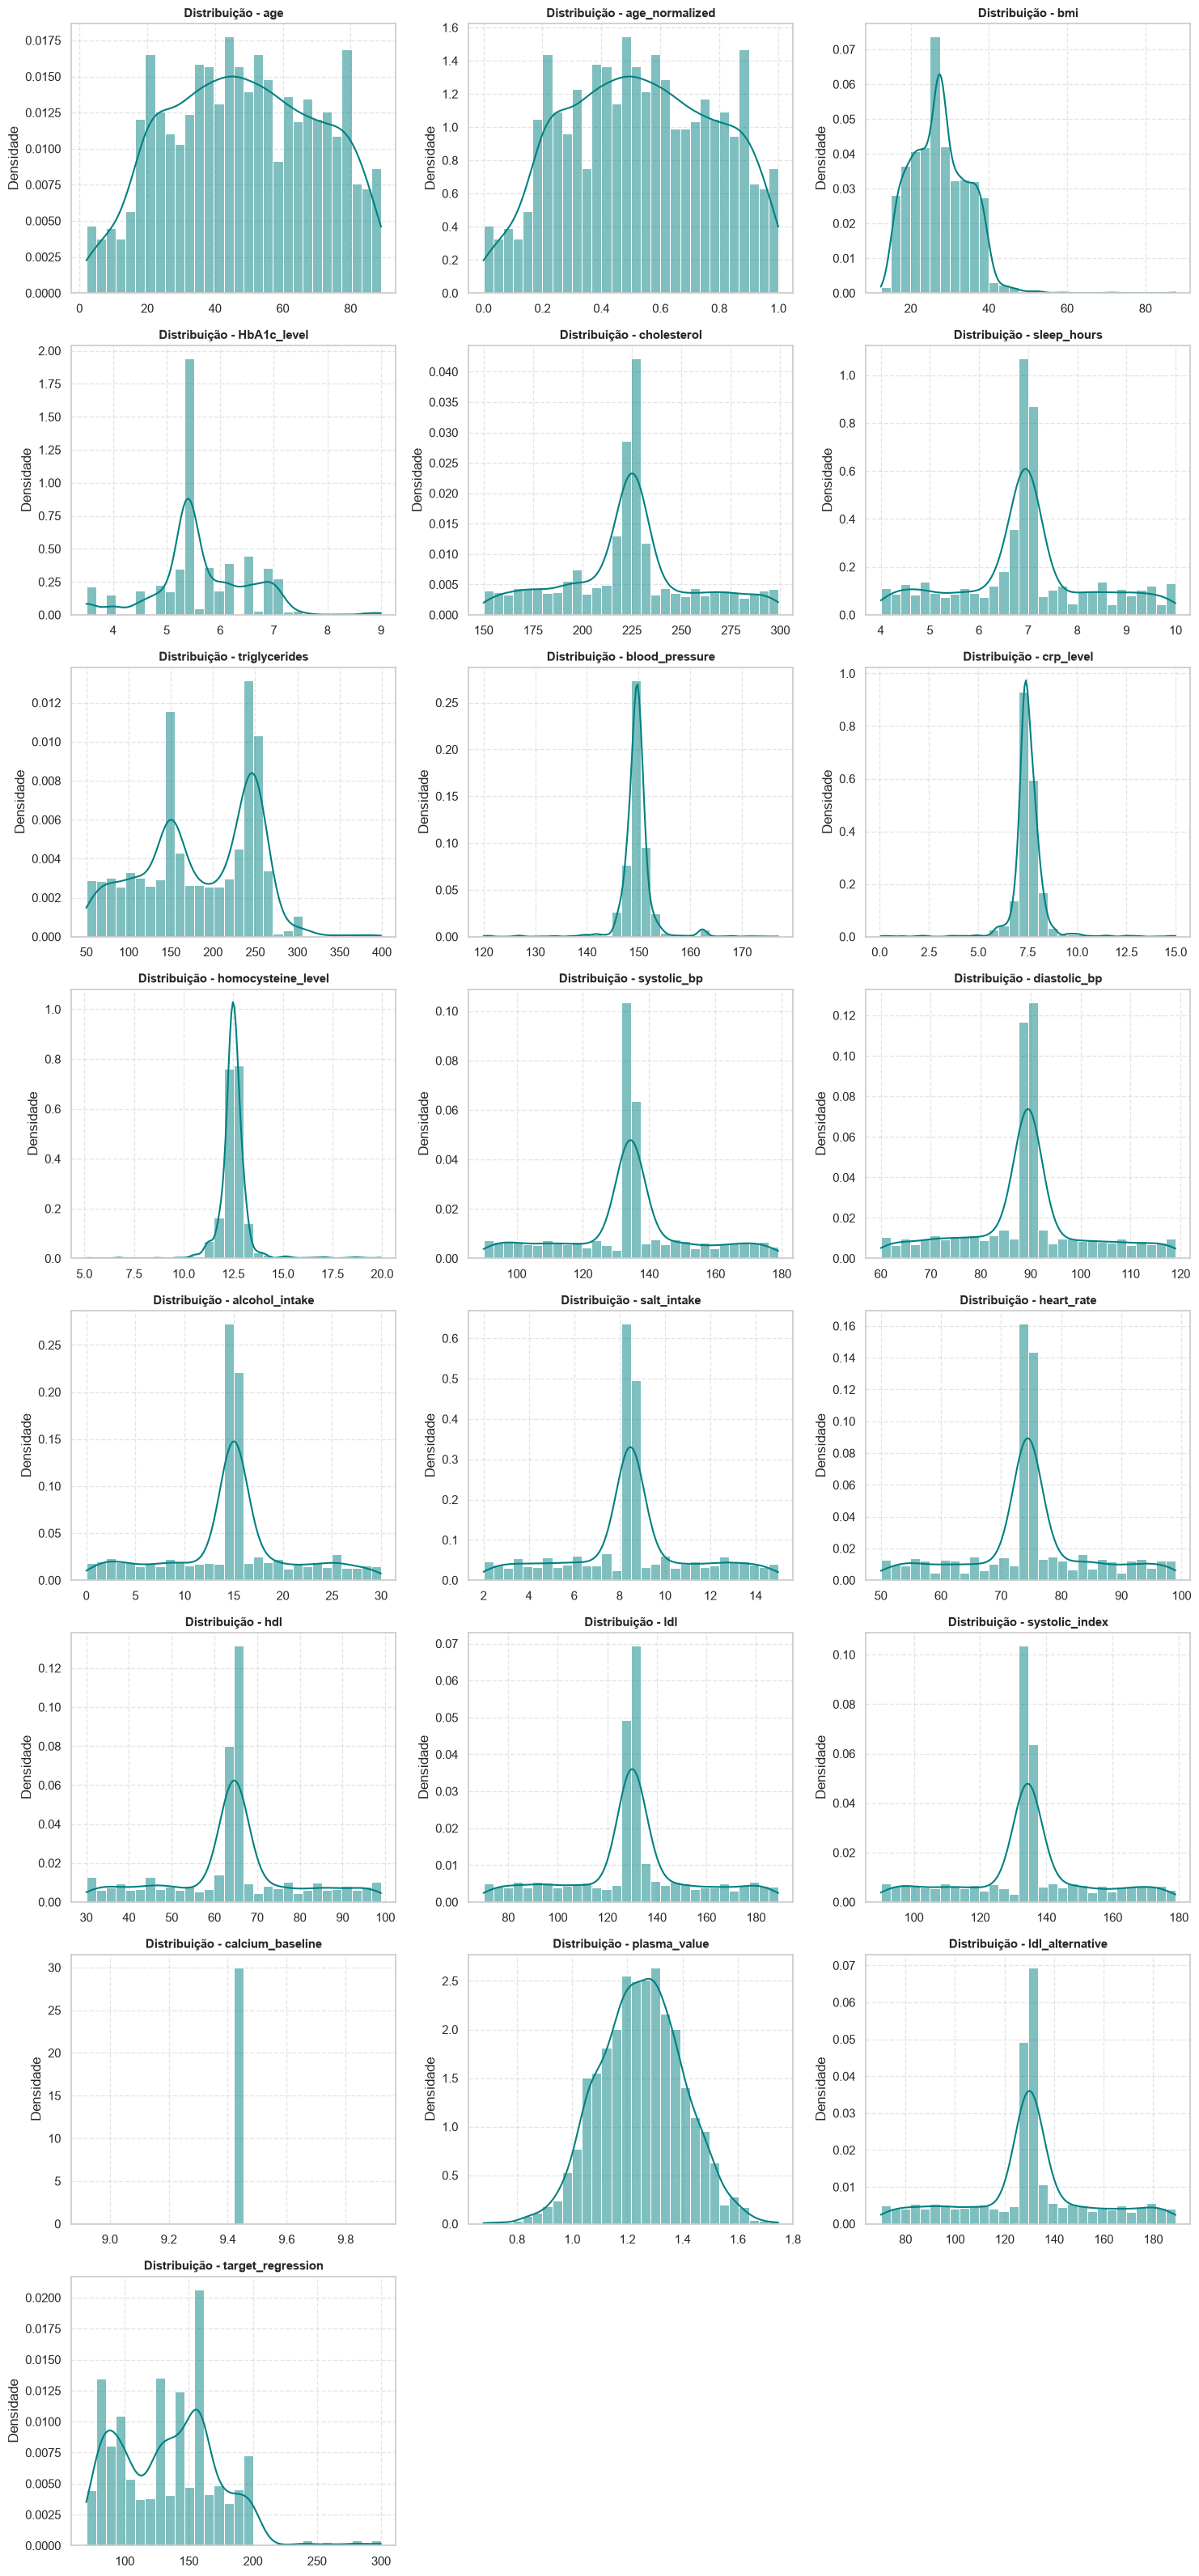

In [58]:
# ============================================================
# 10.2 DISTRIBUTION ANALYSIS - HISTOGRAMS + KDE
# ============================================================

# Configuração da grelha de subplots
n_cols = 3  # Número de colunas
n_vars = len(numeric_cols)
n_rows = math.ceil(n_vars / n_cols)

# Criação da figura
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))

# Ajuste do formato do eixos
if n_vars == 1:
    axes = [axes]
else:
    axes = axes.flatten()

# Plot dos histogramas com curva de densidade (KDE)
for i, col in enumerate(numeric_cols):
    sns.histplot(
        df[col],
        kde=True,
        ax=axes[i],
        color="teal",
        bins=30,
        stat="density",  # Permite comparar a curva KDE ajustada
    )
    axes[i].set_title(
        f"Distribuição - {col}", fontsize=11, fontweight="bold"
    )
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Densidade")
    axes[i].grid(True, linestyle="--", alpha=0.5)

# Ocultar eixos não utilizados
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### 3.2 Outliers (critério do IQR)

In [59]:
# ============================================================
# 10. OUTLIER ANALYSIS - IQR METHOD
# ============================================================

print("\n" + "=" * 60)
print("OUTLIER ANALYSIS")
print("=" * 60)

outlier_summary = []

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    n_outliers = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()

    outlier_summary.append({
        "Variable": col,
        "Outliers": n_outliers,
        "Percentage": n_outliers / len(df) * 100
    })

outlier_summary = (
    pd.DataFrame(outlier_summary)
    .sort_values("Outliers", ascending=False)
)

display(outlier_summary)


OUTLIER ANALYSIS


,Variable,Outliers,Percentage
15,hdl,783,39.15
16,ldl,729,36.45
20,ldl_alternative,729,36.45
12,alcohol_intake,701,35.05
14,heart_rate,691,34.55
10,systolic_bp,683,34.15
17,systolic_index,683,34.15
13,salt_intake,646,32.30
11,diastolic_bp,604,30.20
5,sleep_hours,535,26.75


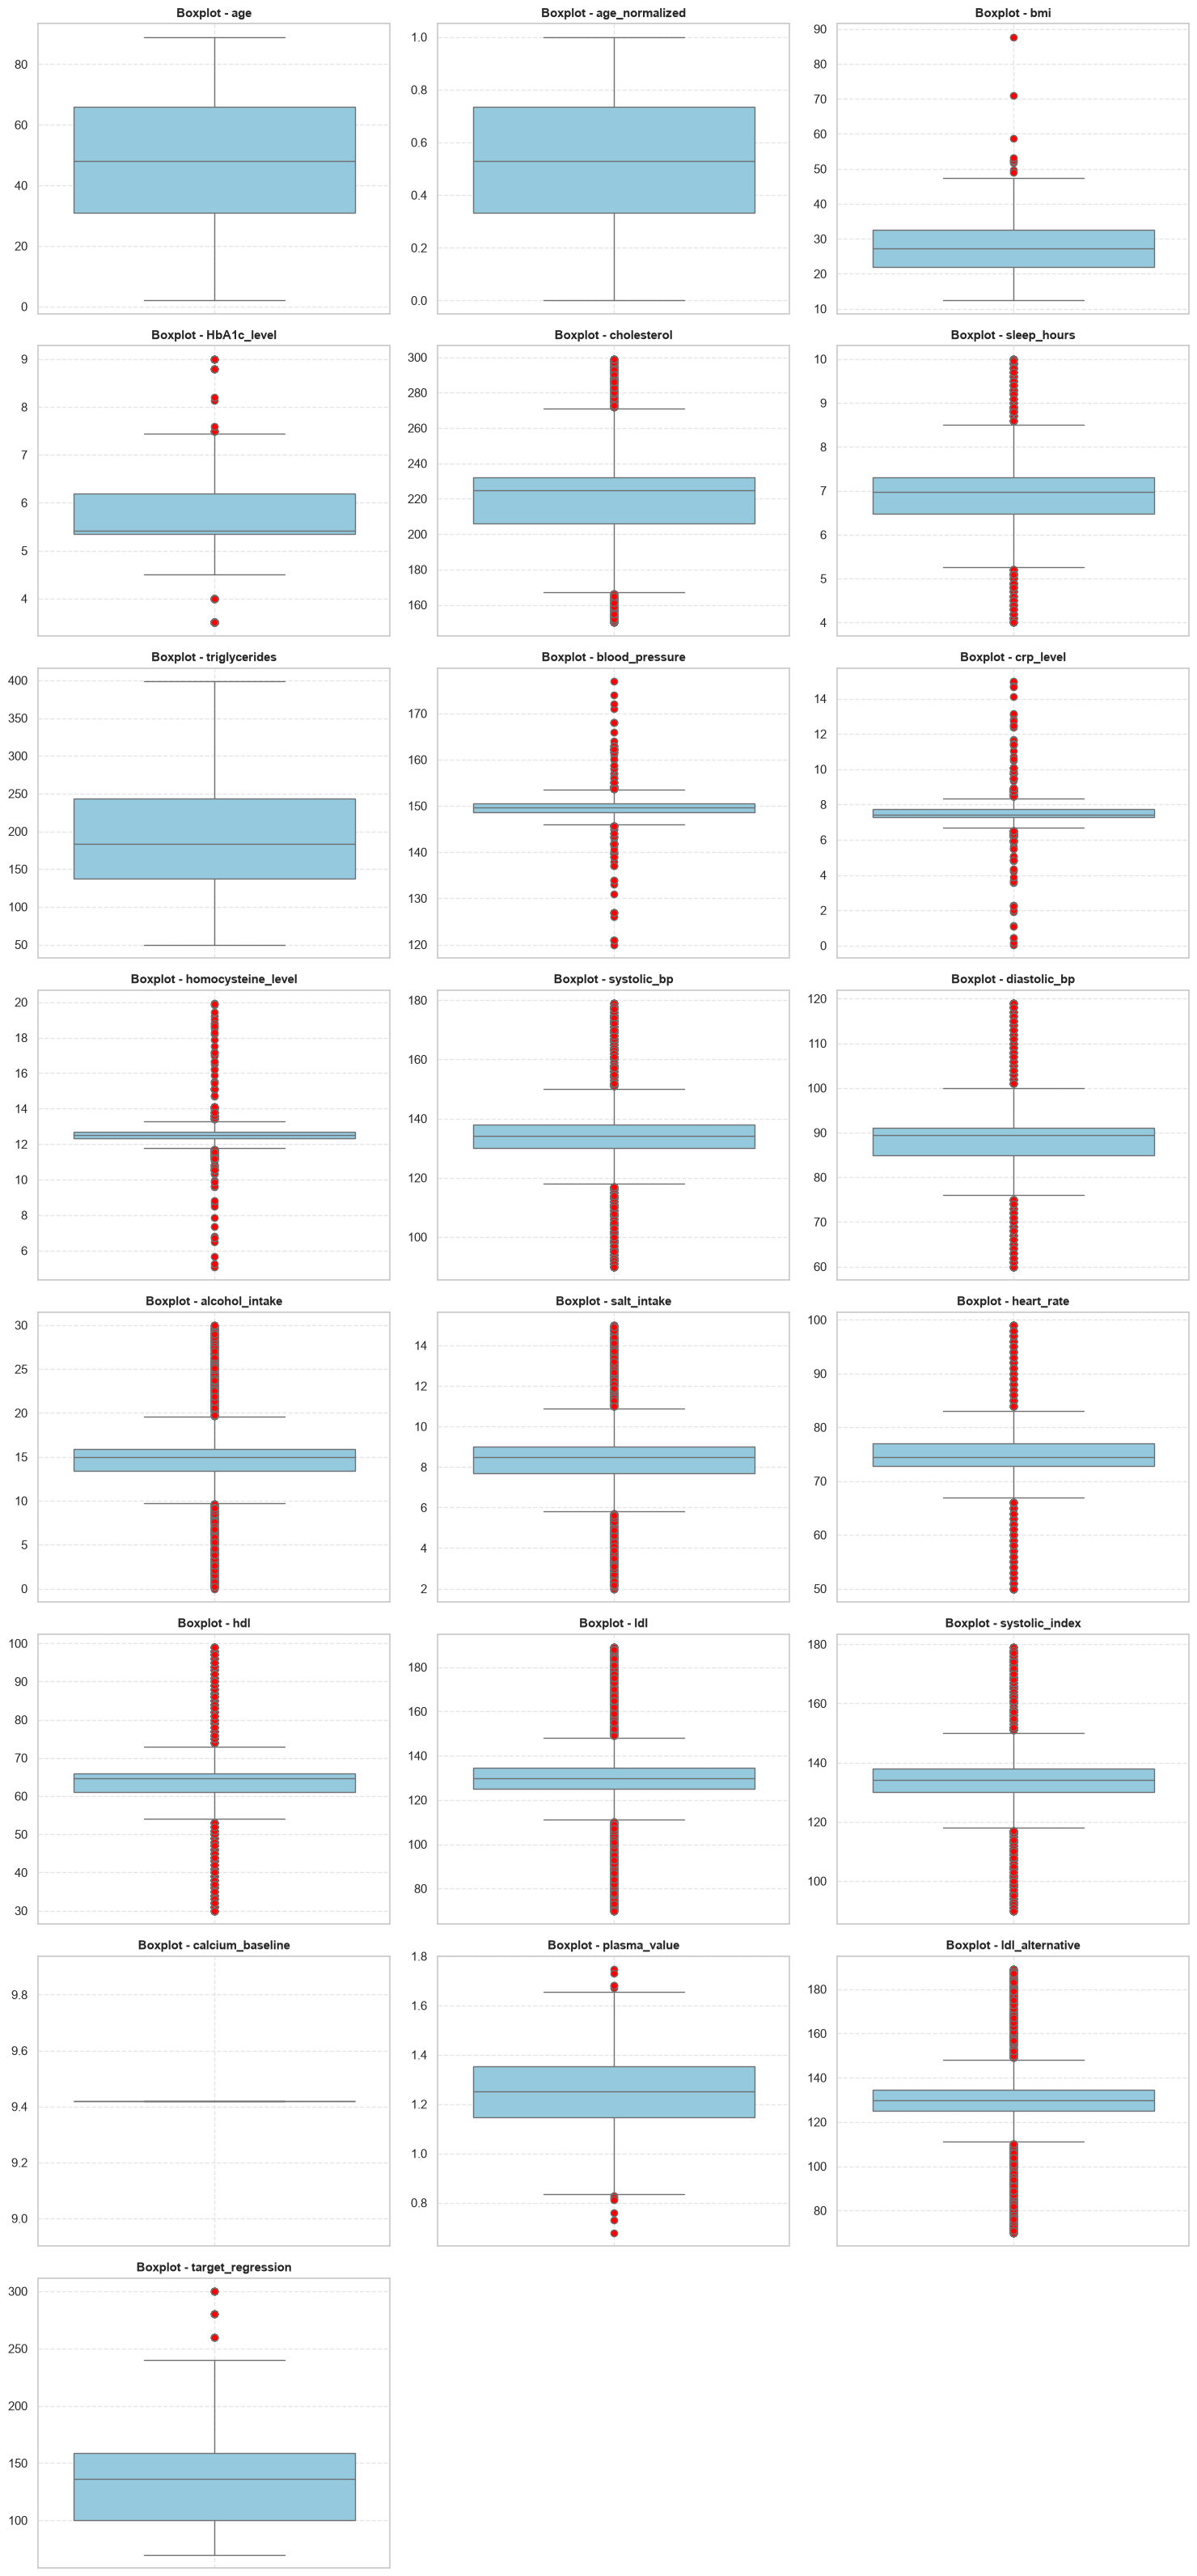

In [60]:
# ============================================================
# 10.1 VISUAL OUTLIER ANALYSIS - BOXPLOTS GRID
# ============================================================

# Configuração da grelha de subplots
n_cols = 3  # Número de colunas no layout
n_vars = len(numeric_cols)
n_rows = math.ceil(n_vars / n_cols)

# Criação da figura
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))

# Garantir que 'axes' seja uma lista/array 1D simples
if n_vars == 1:
    axes = [axes]
else:
    axes = axes.flatten()

# Plot de cada variável numérica
for i, col in enumerate(numeric_cols):
    sns.boxplot(
        y=df[col],
        ax=axes[i],
        color="skyblue",
        flierprops=dict(marker="o", markerfacecolor="red", markersize=6),
    )
    axes[i].set_title(f"Boxplot - {col}", fontsize=11, fontweight="bold")
    axes[i].set_ylabel("")
    axes[i].grid(True, linestyle="--", alpha=0.5)

# Ocultar eixos vazios/não utilizados no final da grelha
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**Leitura:**
- `hdl`, `ldl`, `ldl_alternative`, `alcohol_intake`, `heart_rate`, `systolic_bp`, `systolic_index`, `salt_intake` e `diastolic_bp` têm entre 30% e 39% de valores sinalizados. Nestas variáveis o IQR é muito pequeno face ao desvio-padrão (a maior parte dos valores está colada à mediana), pelo que o critério do IQR sinaliza muitos pontos. Isto indica uma distribuição com pico central e caudas longas e **não** que esses valores sejam erros; por isso não foram removidos. Os diagramas de dispersão da secção 4.2 mostram esse pico como uma faixa vertical no valor mediano, o que sugere (hipótese por confirmar) que valores em falta foram preenchidos com a mediana.
- `target_regression` tem apenas 16 *outliers* (0,8%), todos acima do limite superior (máximo 300).
- `age`, `age_normalized` e `triglycerides` não têm *outliers*.

### 3.3 Distribuição das variáveis categóricas

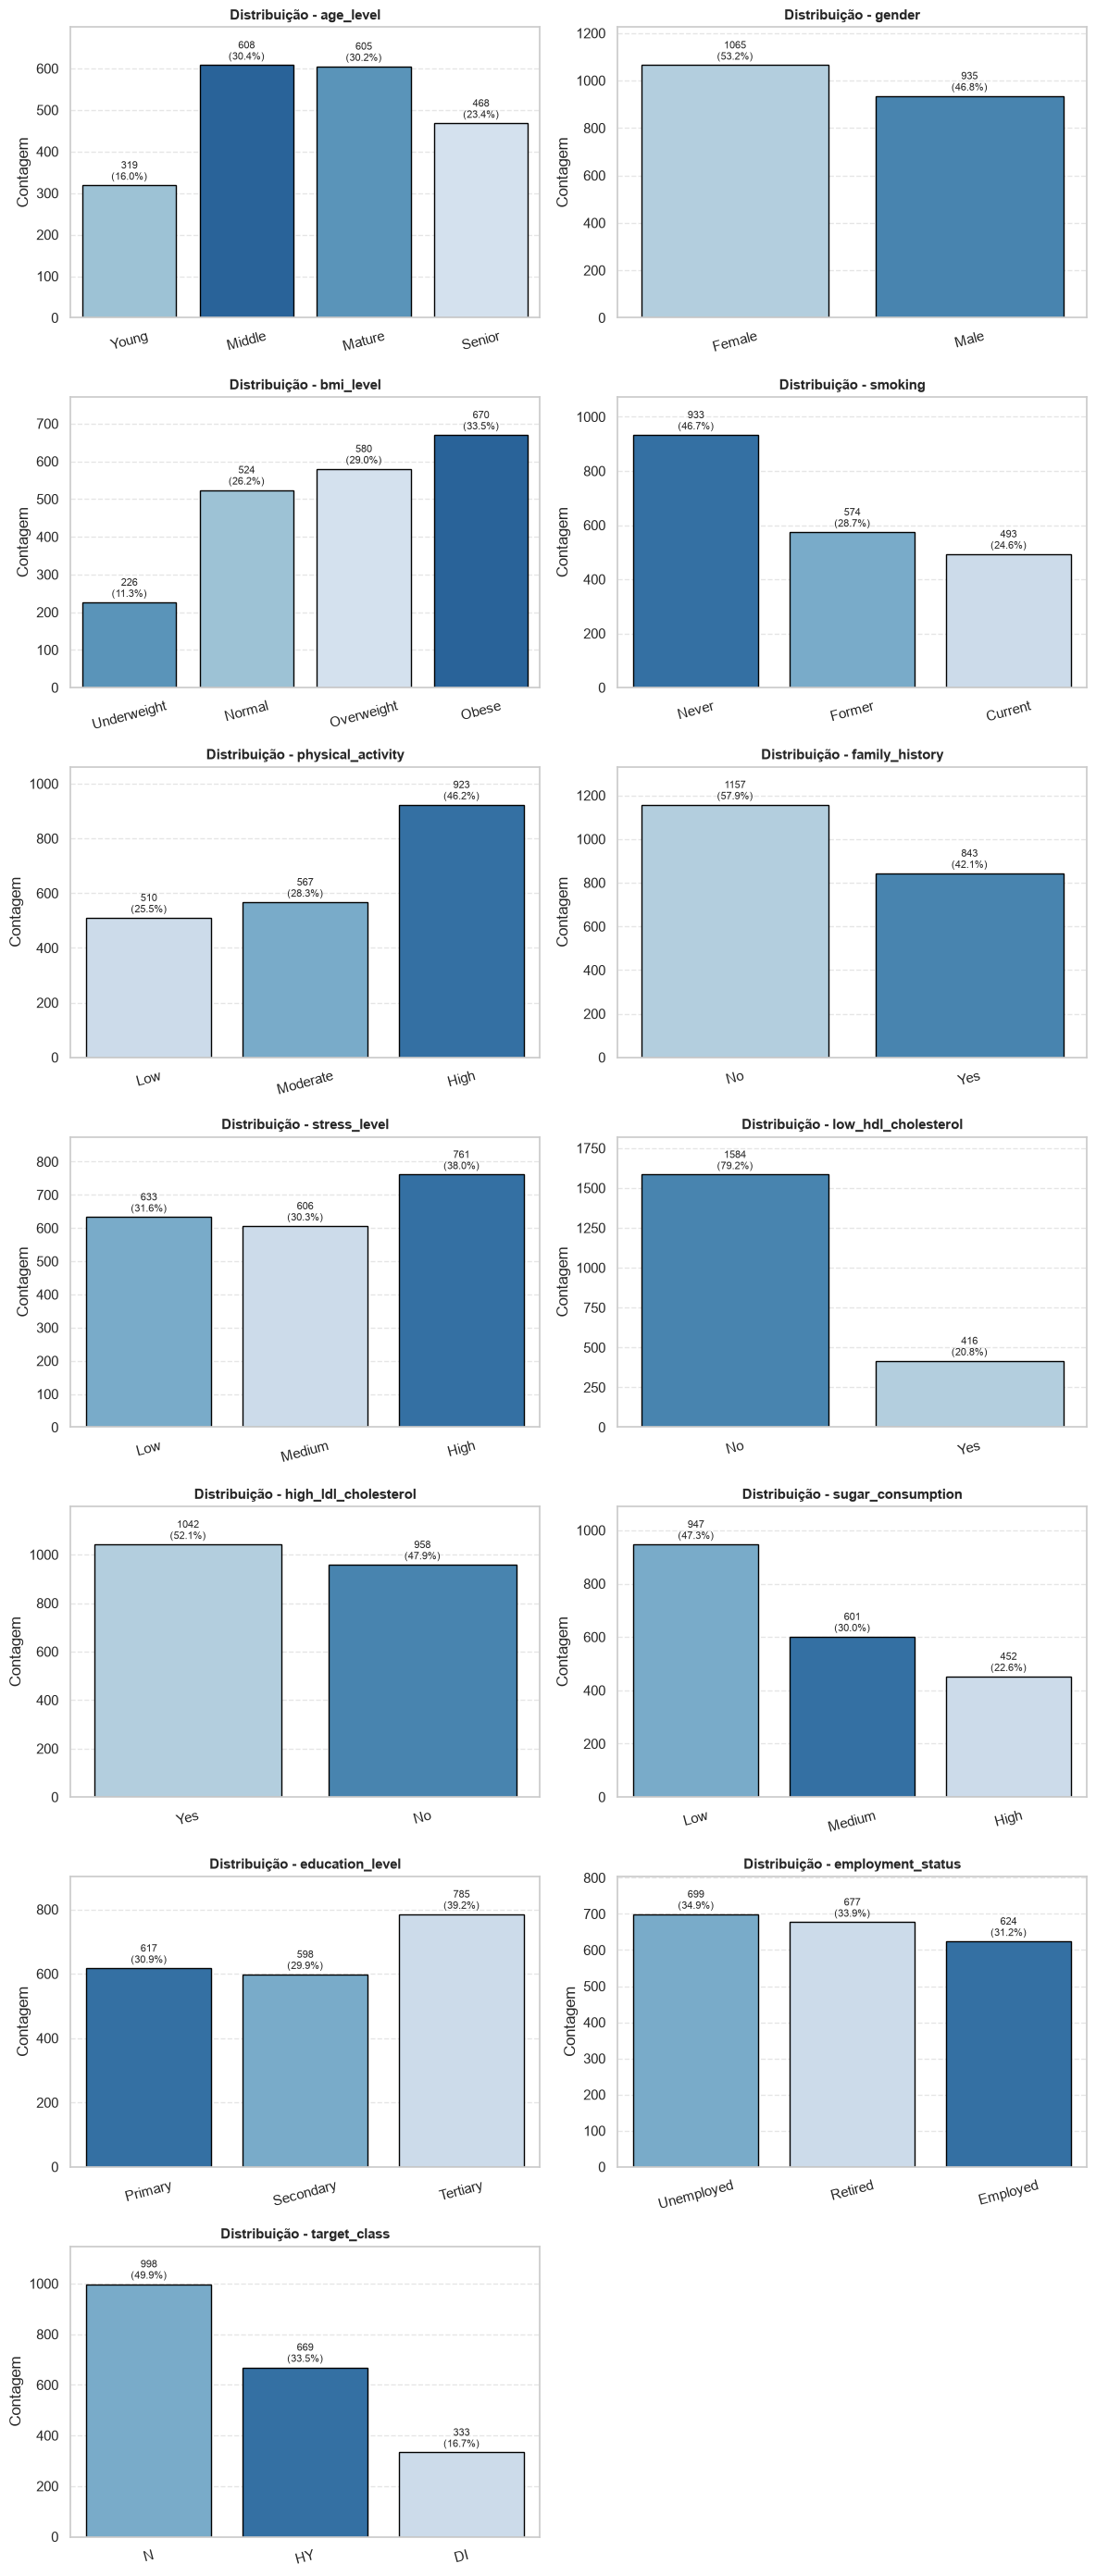

In [61]:
# ============================================================
# 10.3 UNIVARIATE ANALYSIS - CATEGORICAL VARIABLES (BAR CHARTS)
# ============================================================

n_cols = 2
n_vars = len(categorical_cols)
n_rows = math.ceil(n_vars / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 6, n_rows * 4))

if n_vars == 1:
    axes = [axes]
else:
    axes = axes.flatten()

ordinal_orders = {
    "age_level": ["Young", "Middle", "Mature", "Senior"],
    "bmi_level": ["Underweight", "Normal", "Overweight", "Obese"],
    "smoking": ["Never", "Former", "Current"],
    "physical_activity": ["Low", "Moderate", "High"],
    "stress_level": ["Low", "Medium", "High"],
    "sugar_consumption": ["Low", "Medium", "High"],
    "education_level": ["Primary", "Secondary", "Tertiary"],
}

total_obs = len(df)

for i, col in enumerate(categorical_cols):
    if col in ordinal_orders:
        order = [cat for cat in ordinal_orders[col] if cat in df[col].unique()]
    else:
        order = df[col].value_counts().index

    ax = sns.countplot(
        data=df,
        x=col,
        hue=col,
        legend=False,
        order=order,
        ax=axes[i],
        palette="Blues_r",
        edgecolor="black",
    )

    axes[i].set_title(
        f"Distribuição - {col}", fontsize=11, fontweight="bold"
    )
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Contagem")
    axes[i].grid(axis="y", linestyle="--", alpha=0.5)
    axes[i].tick_params(axis="x", rotation=15)
    
    y_max = df[col].value_counts().max()
    axes[i].set_ylim(0, y_max * 1.15)

    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            percentage = (height / total_obs) * 100
            ax.annotate(
                f"{int(height)}\n({percentage:.1f}%)",
                (p.get_x() + p.get_width() / 2.0, height),
                ha="center",
                va="bottom",
                fontsize=8,
                xytext=(0, 2),
                textcoords="offset points",
            )

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

---
## 4. Análise bivariada

Relação entre as features e cada uma das variáveis-alvo, e entre as próprias features:

1. correlação entre features (colinearidade);
2. features vs `target_regression`;
3. `target_regression` vs `target_class`.

### 4.1 Correlação entre features (Pearson)

Mede a relação linear entre pares de preditores. Correlações muito altas entre preditores indicam redundância e causam colinearidade nos modelos lineares.


CORRELATION MATRIX
                         age  age_normalized       bmi  HbA1c_level  \
age                 1.000000        1.000000  0.096402     0.104491   
age_normalized      1.000000        1.000000  0.096402     0.104491   
bmi                 0.096402        0.096402  1.000000     0.041813   
HbA1c_level         0.104491        0.104491  0.041813     1.000000   
cholesterol         0.001560        0.001560  0.002352    -0.006744   
sleep_hours         0.028452        0.028452  0.036743    -0.012072   
triglycerides      -0.236845       -0.236845 -0.003540    -0.061578   
blood_pressure     -0.143100       -0.143101 -0.093575     0.073729   
crp_level           0.037514        0.037514 -0.096554    -0.014108   
homocysteine_level  0.050482        0.050482  0.105355    -0.001573   
systolic_bp         0.016034        0.016034 -0.017043    -0.014468   
diastolic_bp        0.010665        0.010665 -0.014707     0.002383   
alcohol_intake     -0.014907       -0.014907  0.002603   

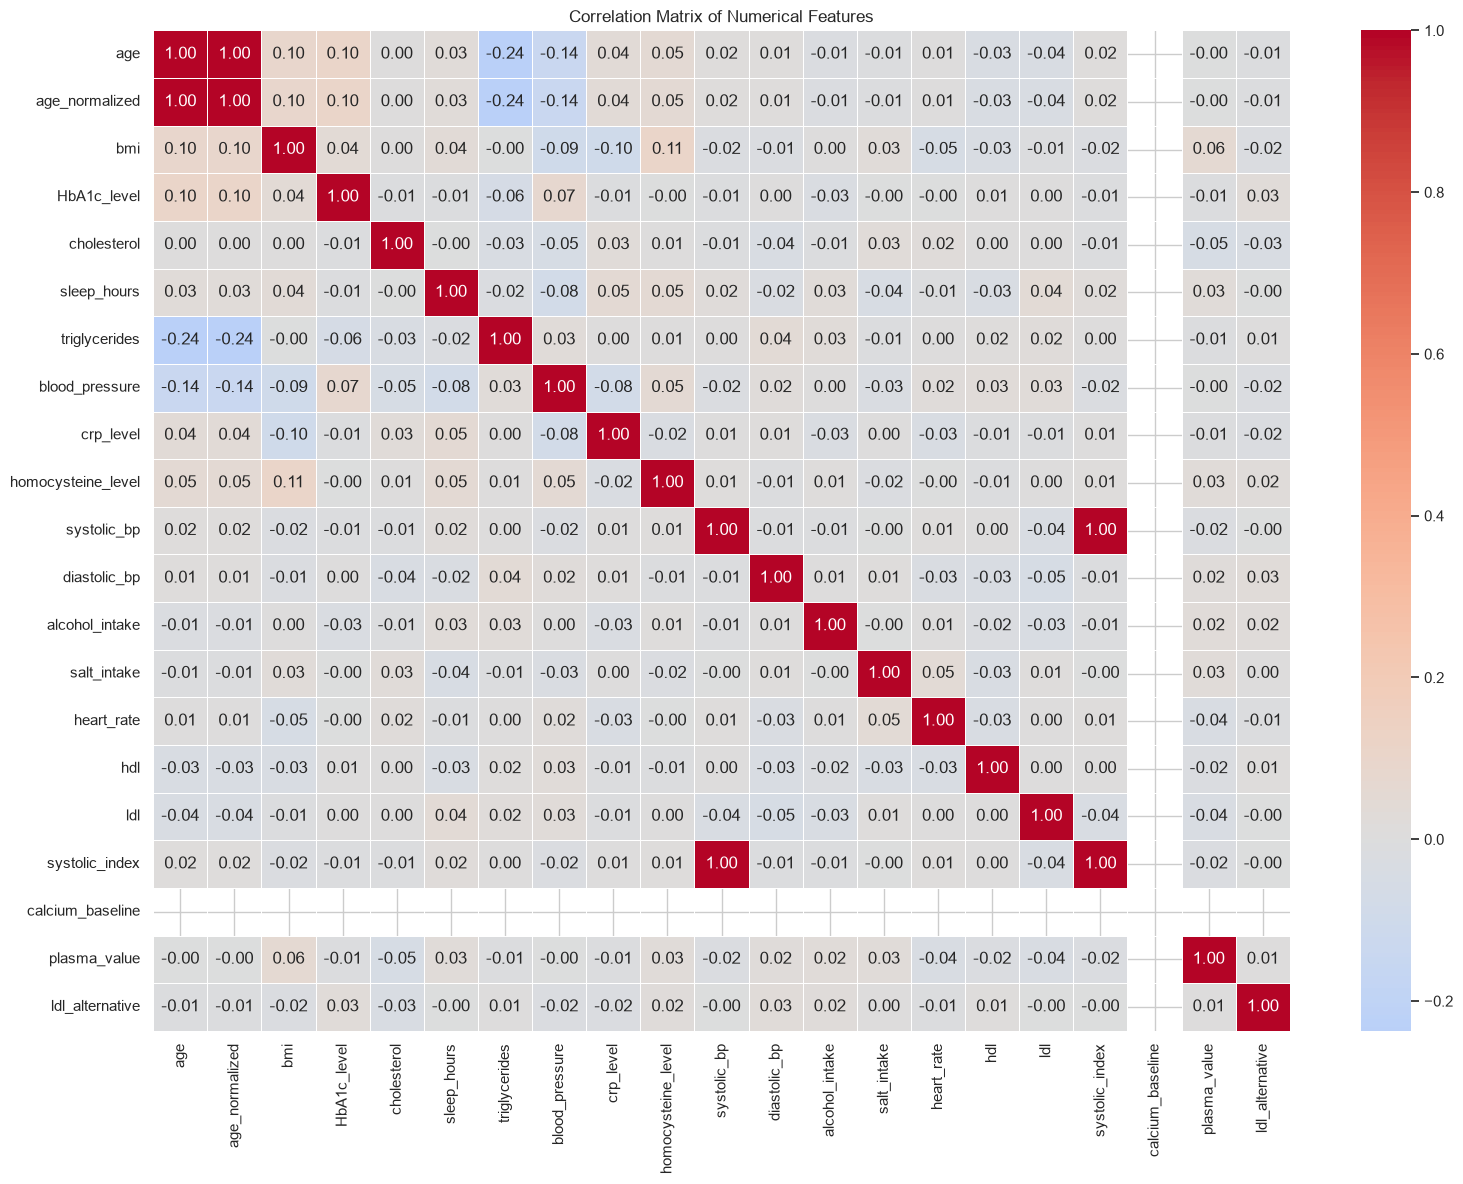

In [62]:
# ============================================================
# 11. CORRELATION MATRIX
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

print("\n" + "=" * 60)
print("CORRELATION MATRIX")
print("=" * 60)

# Remove target_regression
correlation = df[numeric_cols].drop(columns="target_regression").corr()

print(correlation)

# Heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

**Leitura:** fora dos pares `age`/`age_normalized` e `systolic_bp`/`systolic_index` (r = 1), as correlações entre preditores são fracas. A maior em valor absoluto é entre `age` e `triglycerides` (-0,24). A coluna/linha de `calcium_baseline` está vazia (NaN) porque a variável é constante.

### 4.2 Features vs `target_regression`

Correlação de Spearman (monotónica, menos sensível a *outliers* que a de Pearson), diagramas de dispersão para as numéricas e *boxplots* por categoria para as categóricas.

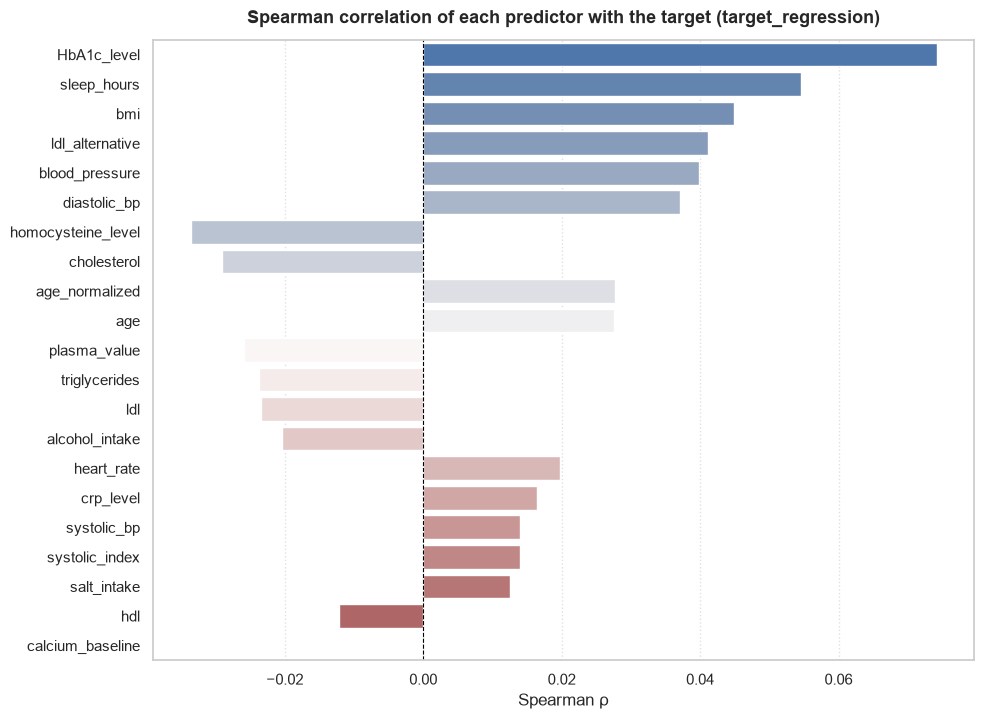

Correlation with the target, sorted by |ρ|:


,Spearman_rho,|rho|
HbA1c_level,0.0742,0.0742
sleep_hours,0.0545,0.0545
bmi,0.0449,0.0449
ldl_alternative,0.0411,0.0411
blood_pressure,0.0398,0.0398
diastolic_bp,0.0371,0.0371
homocysteine_level,-0.0336,0.0336
cholesterol,-0.0291,0.0291
age_normalized,0.0277,0.0277
age,0.0276,0.0276


In [63]:
# Spearman correlation of each candidate predictor with the target (descriptive, full data)
sample_corr = df.sample(min(len(df), 100_000), random_state=42)
numeric_df = sample_corr.select_dtypes(include=["number"])

target_corr = (
    numeric_df.corr(method="spearman")[["target_regression"]]
    .drop("target_regression")
    .rename(columns={"target_regression": "Spearman_rho"})
)
target_corr["|rho|"] = target_corr["Spearman_rho"].abs()
target_corr = target_corr.sort_values(by="|rho|", ascending=False)

plt.figure(figsize=(10, max(6, len(target_corr) * 0.35)))
sns.barplot(x=target_corr["Spearman_rho"], y=target_corr.index, hue=target_corr.index,
            palette="vlag", legend=False)
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.title("Spearman correlation of each predictor with the target (target_regression)",
          fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Spearman ρ")
plt.ylabel("")
plt.grid(axis="x", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

print("Correlation with the target, sorted by |ρ|:")
display(target_corr.round(4))

C:\Users\moale\AppData\Roaming\Python\Python313\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\moale\AppData\Roaming\Python\Python313\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


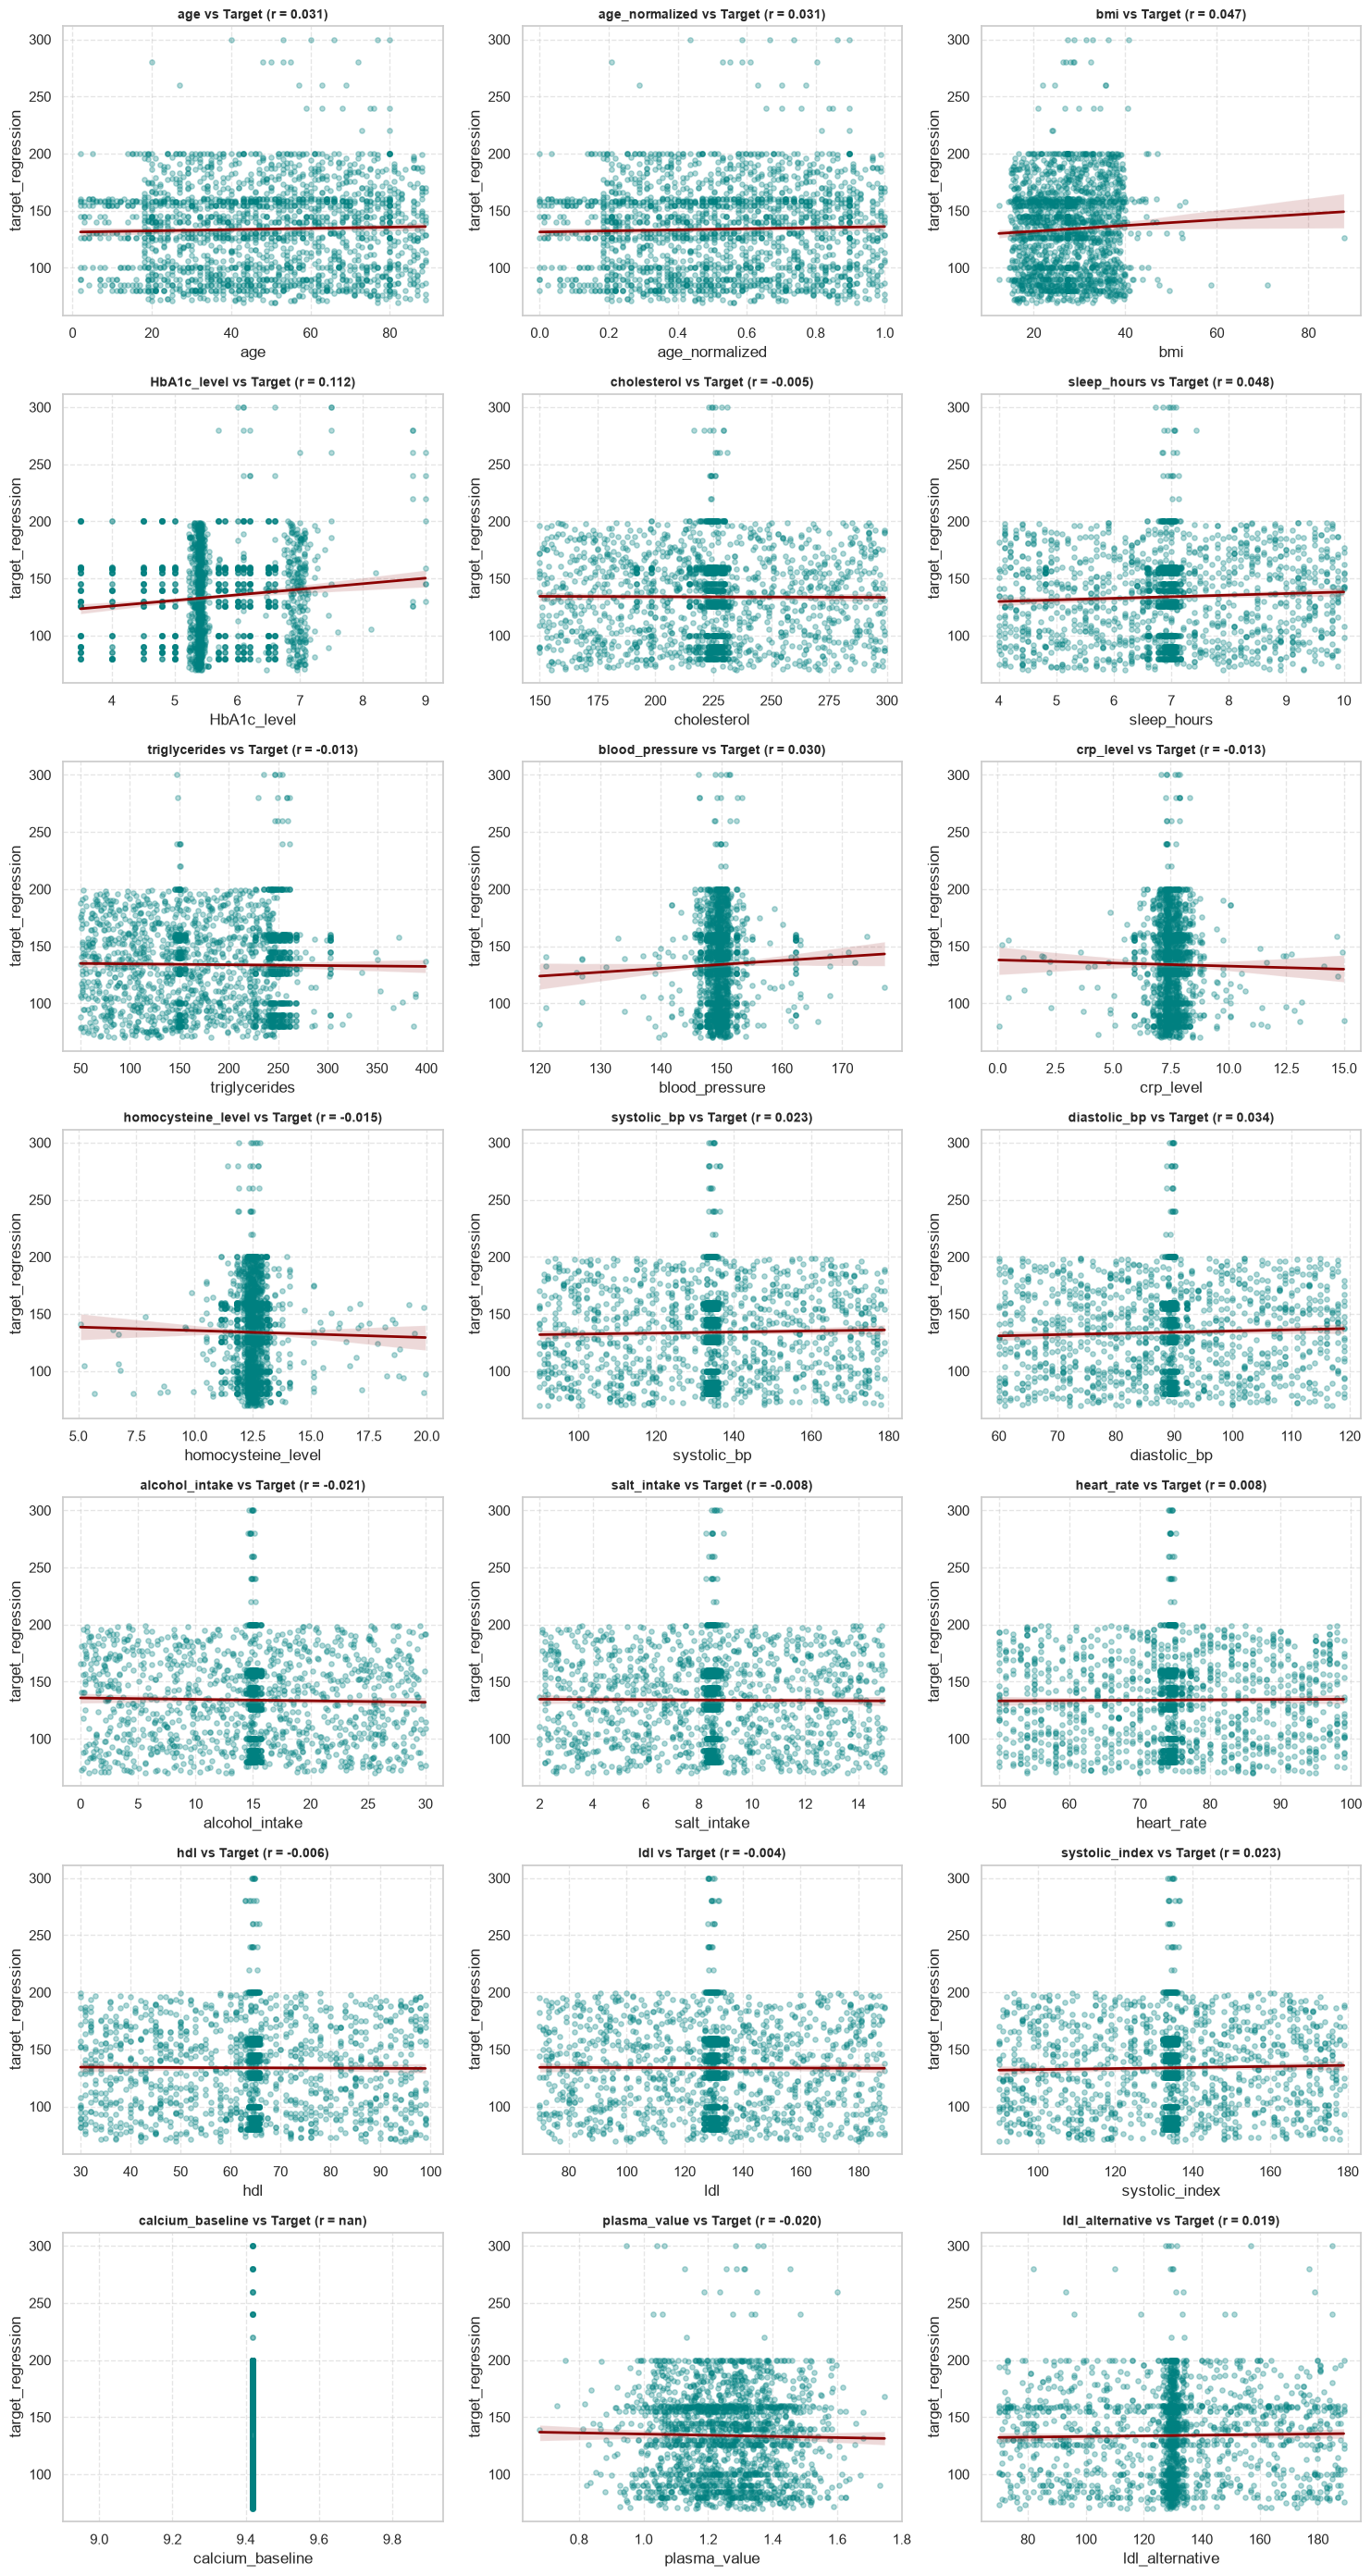

In [64]:
# ============================================================
# SCATTER PLOTS - ALL NUMERICAL FEATURES VS TARGET_REGRESSION
# ============================================================

predictors = [col for col in numeric_cols if col != "target_regression"]

n_cols = 3
n_vars = len(predictors)
n_rows = math.ceil(n_vars / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))

if n_vars == 1:
    axes = [axes]
else:
    axes = axes.flatten()

for i, col in enumerate(predictors):
    # Calcular correlação de Pearson para exibir no título
    corr_val = df[col].corr(df["target_regression"])

    sns.regplot(
        data=df,
        x=col,
        y="target_regression",
        ax=axes[i],
        scatter_kws={"alpha": 0.3, "color": "teal", "s": 15},
        line_kws={"color": "darkred", "linewidth": 2},
    )

    axes[i].set_title(
        f"{col} vs Target (r = {corr_val:.3f})",
        fontsize=10,
        fontweight="bold",
    )
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("target_regression")
    axes[i].grid(True, linestyle="--", alpha=0.5)

# Ocultar eixos não utilizados
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

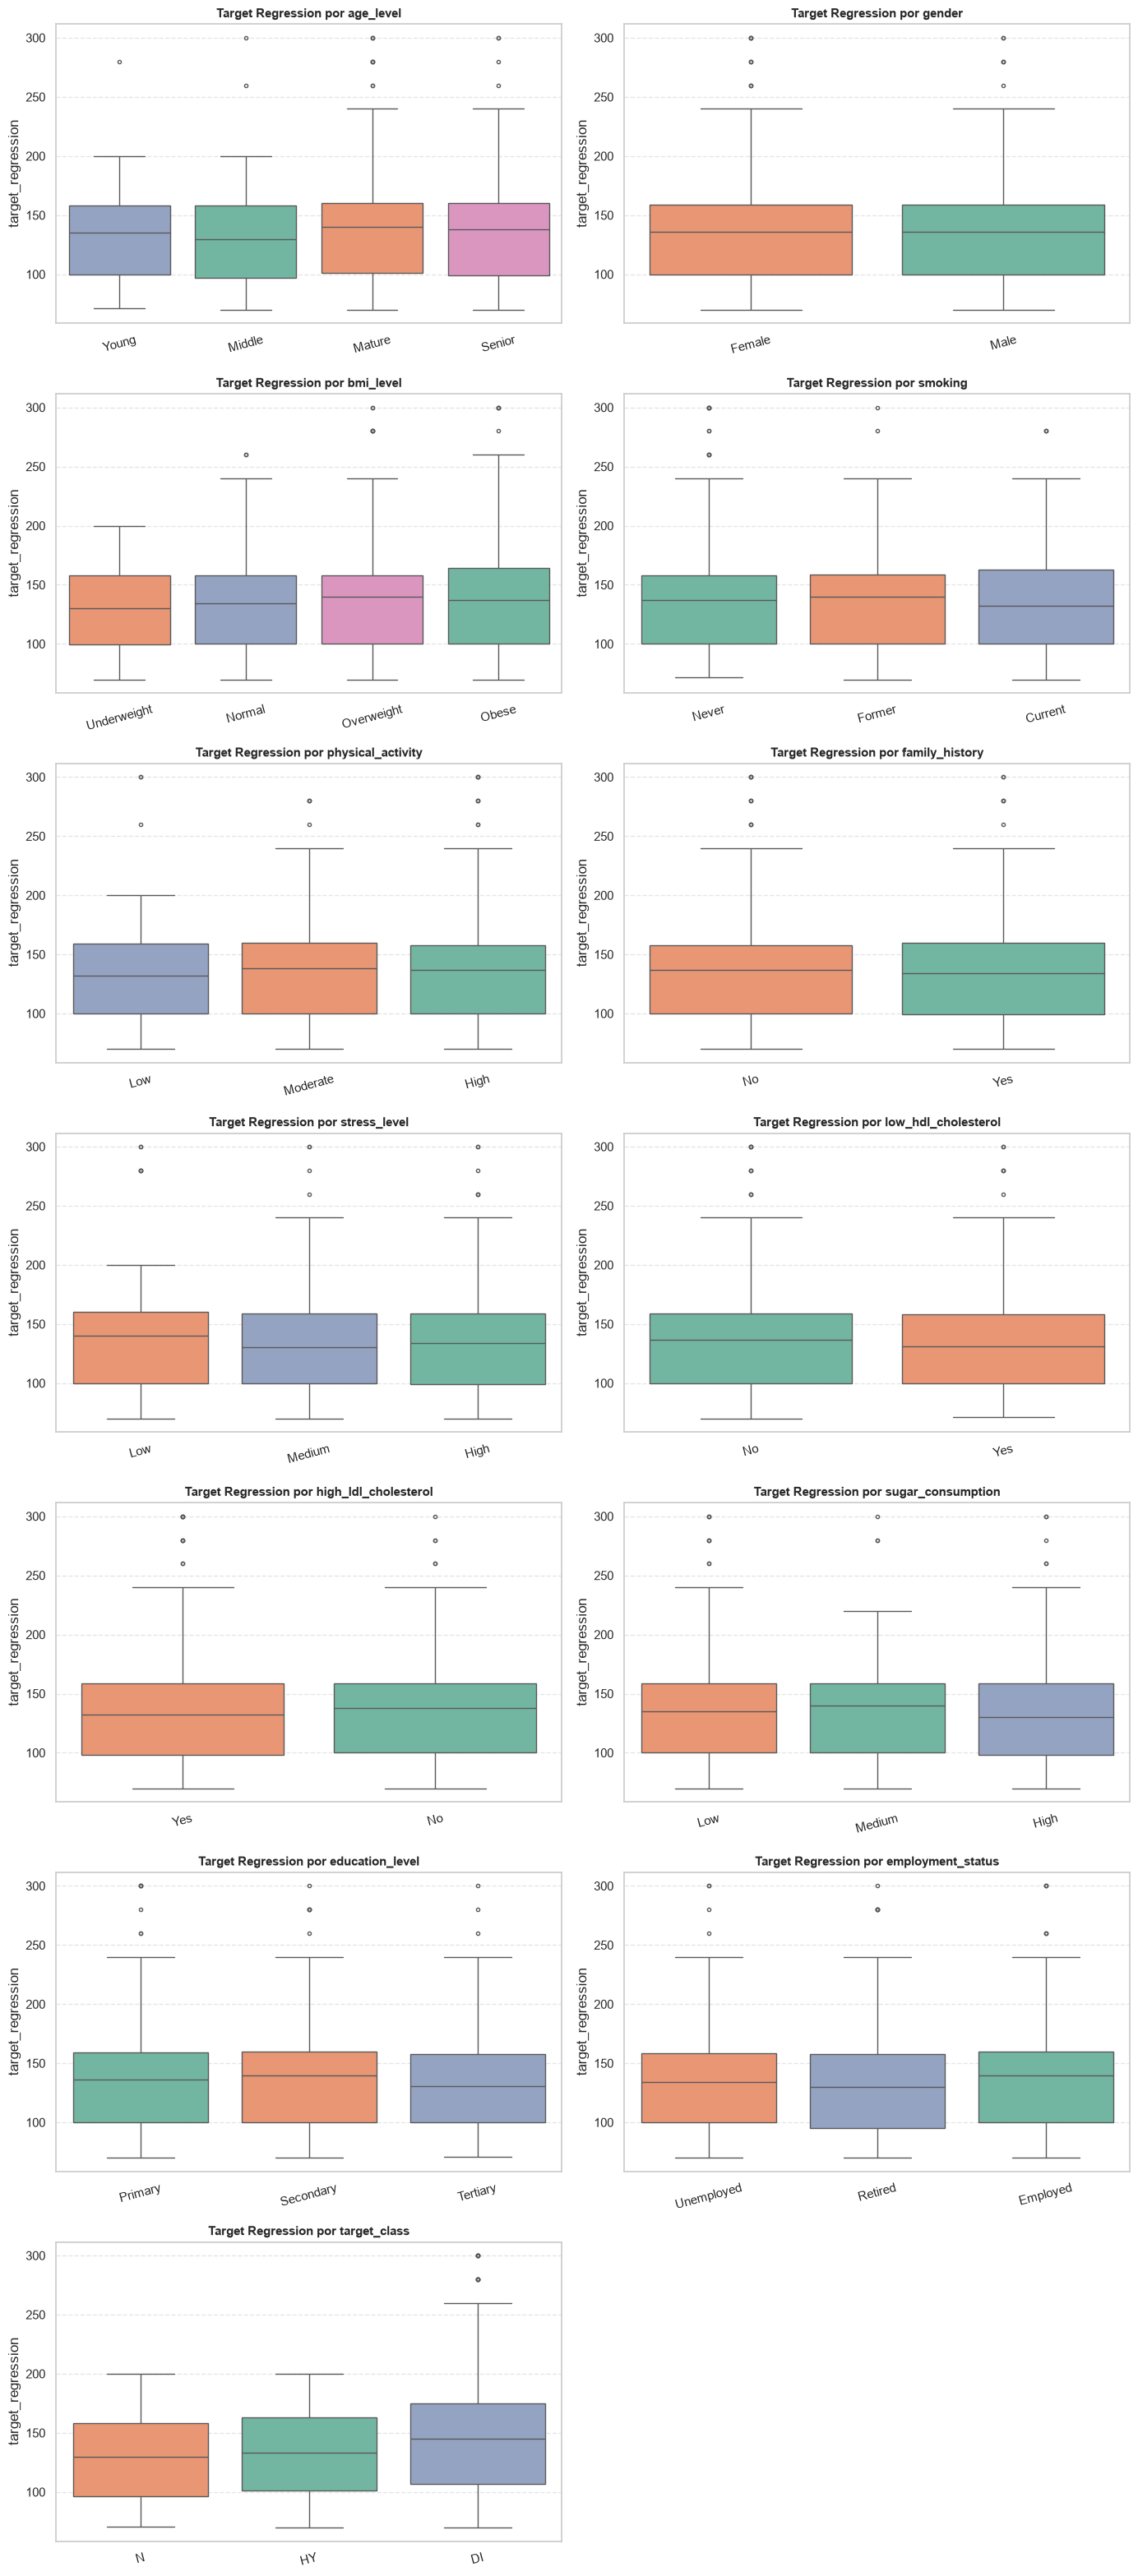

In [65]:
# ============================================================
# CATEGORICAL FEATURES VS TARGET_REGRESSION (BOXPLOTS)
# ============================================================
import math

n_cols = 2
n_vars = len(categorical_cols)
n_rows = math.ceil(n_vars / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 7, n_rows * 4.5))
axes = axes.flatten() if n_vars > 1 else [axes]

# Ordem para ordinais
ordinal_orders = {
    "age_level": ["Young", "Middle", "Mature", "Senior"],
    "bmi_level": ["Underweight", "Normal", "Overweight", "Obese"],
    "smoking": ["Never", "Former", "Current"],
    "physical_activity": ["Low", "Moderate", "High"],
    "stress_level": ["Low", "Medium", "High"],
    "sugar_consumption": ["Low", "Medium", "High"],
    "education_level": ["Primary", "Secondary", "Tertiary"],
}

for i, col in enumerate(categorical_cols):
    order = ordinal_orders.get(col, df[col].value_counts().index.tolist())
    
    sns.boxplot(
        data=df,
        x=col,
        y="target_regression",
        hue=col,
        order=order,
        ax=axes[i],
        palette="Set2",
        fliersize=3
    )
    axes[i].set_title(f"Target Regression por {col}", fontweight="bold", fontsize=11)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("target_regression")
    axes[i].tick_params(axis="x", rotation=15)
    axes[i].grid(axis="y", linestyle="--", alpha=0.5)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**Leitura:** todas as correlações de Spearman com `target_regression` são muito fracas (|ρ| < 0,08; a maior é `HbA1c_level`, 0,074). Os diagramas de dispersão não mostram padrões claros (a correlação de Pearson mais alta é 0,11, também com `HbA1c_level`) e as distribuições do alvo são semelhantes entre as categorias. Nota-se ainda que em quase todas as features contínuas existe uma faixa vertical de pontos no valor central (mediana), consistente com a forte concentração referida na secção 3.2. Não se espera, portanto, que a regressão linear explique grande parte da variabilidade do alvo (verificado na parte de regressão).

### 4.3 `target_regression` vs `target_class`

Compara-se a distribuição do alvo de regressão em cada uma das classes.

In [66]:
# ============================================================
# 13. TARGET_REGRESSION BY TARGET_CLASS
# ============================================================

print("\n" + "=" * 60)
print("TARGET_REGRESSION BY TARGET_CLASS")
print("=" * 60)

target_comparison = (
    df.groupby("target_class")["target_regression"]
    .describe()
)

print(target_comparison)


TARGET_REGRESSION BY TARGET_CLASS
              count        mean        std   min     25%    50%    75%    max
target_class                                                                 
DI            333.0  146.603604  49.499412  70.0  107.00  145.0  175.0  300.0
HY            669.0  133.136024  36.781696  70.0  101.00  133.0  163.0  200.0
N             998.0  130.239479  34.926485  71.0   96.25  130.0  158.0  200.0


**Leitura:** a classe `DI` tem média mais alta (146,6) e maior dispersão (desvio-padrão 49,5; máximo 300) do que `HY` (133,1) e `N` (130,2), mas as distribuições sobrepõem-se bastante.

---
## 5. Features constantes, redundantes e não informativas

O enunciado pede para identificar features potencialmente não informativas, constantes ou redundantes e justificar com os resultados. Verificam-se por ordem: constantes, quase constantes e pares fortemente correlacionados (|r| ≥ 0,80).

### 5.1 Variáveis constantes e quase constantes

In [67]:
# ============================================================
# 8. CONSTANT VARIABLES
# ============================================================

print("\n" + "=" * 60)
print("CONSTANT VARIABLES")
print("=" * 60)

constant_cols = [
    col for col in df.columns
    if df[col].nunique() <= 1
]

if constant_cols:
    print(constant_cols)
else:
    print("No constant variables found.")


CONSTANT VARIABLES
['calcium_baseline']


In [68]:
# ============================================================
# 9. NEAR-CONSTANT VARIABLES
# ============================================================

print("\n" + "=" * 60)
print("NEAR-CONSTANT VARIABLES (>95% SAME VALUE)")
print("=" * 60)

near_constant = []

for col in df.columns:
    distribution = df[col].value_counts(normalize=True)

    if distribution.iloc[0] > 0.95:
        near_constant.append({
            "Variable": col,
            "Most Frequent Value": distribution.index[0],
            "Percentage": distribution.iloc[0] * 100
        })

near_constant = pd.DataFrame(near_constant)

if len(near_constant) > 0:
    display(near_constant)
else:
    print("No near-constant variables found.")



NEAR-CONSTANT VARIABLES (>95% SAME VALUE)


,Variable,Most Frequent Value,Percentage
0,calcium_baseline,9.42,100.0


### 5.2 Features fortemente correlacionadas

In [69]:
# ============================================================
# 12. HIGHLY CORRELATED FEATURES
# ============================================================

print("\n" + "=" * 60)
print("HIGHLY CORRELATED FEATURES (|r| >= 0.80)")
print("=" * 60)

corr_pairs = (
    correlation
    .where(
        ~np.eye(
            correlation.shape[0],
            dtype=bool
        )
    )
    .stack()
    .reset_index()
)

corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

corr_pairs["Abs Correlation"] = (
    abs(corr_pairs["Correlation"])
)

# Remove duplicate pairs
corr_pairs["Pair"] = corr_pairs.apply(
    lambda row: tuple(
        sorted(
            [row["Feature 1"], row["Feature 2"]]
        )
    ),
    axis=1
)

high_corr = (
    corr_pairs[
        corr_pairs["Abs Correlation"] >= 0.80
    ]
    .drop_duplicates("Pair")
    .sort_values(
        "Abs Correlation",
        ascending=False
    )
    .drop(columns="Pair")
)

print(high_corr)


HIGHLY CORRELATED FEATURES (|r| >= 0.80)
       Feature 1       Feature 2  Correlation  Abs Correlation
227  systolic_bp  systolic_index          1.0              1.0
1            age  age_normalized          1.0              1.0


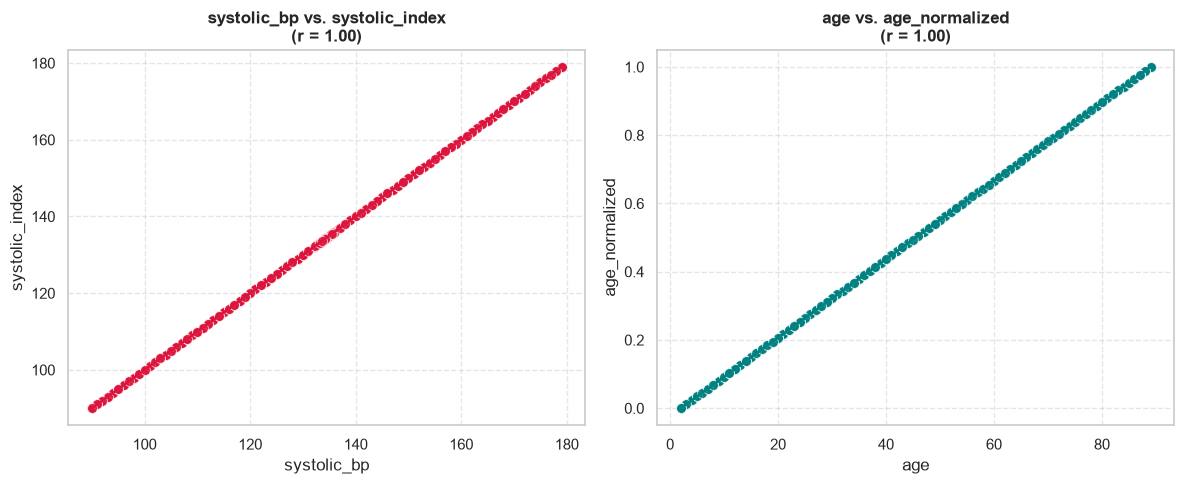

In [70]:
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# VISUALIZAÇÃO DE CORRELAÇÃO PERFEITA (r = 1.0)
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Gráfico: systolic_bp vs systolic_index
sns.scatterplot(
    data=df,
    x="systolic_bp",
    y="systolic_index",
    ax=axes[0],
    color="crimson",
    s=50,
    alpha=0.8,
)
sns.regplot(
    data=df,
    x="systolic_bp",
    y="systolic_index",
    ax=axes[0],
    color="crimson",
    scatter=False,
    line_kws={"linewidth": 2},
)
axes[0].set_title(
    "systolic_bp vs. systolic_index\n(r = 1.00)", fontsize=12, fontweight="bold"
)
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Gráfico: age vs age_normalized
sns.scatterplot(
    data=df,
    x="age",
    y="age_normalized",
    ax=axes[1],
    color="teal",
    s=50,
    alpha=0.8,
)
sns.regplot(
    data=df,
    x="age",
    y="age_normalized",
    ax=axes[1],
    color="teal",
    scatter=False,
    line_kws={"linewidth": 2},
)
axes[1].set_title(
    "age vs. age_normalized\n(r = 1.00)", fontsize=12, fontweight="bold"
)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

**Leitura:**
- `systolic_index` tem exatamente as mesmas estatísticas e r = 1 com `systolic_bp`, ou seja, é um duplicado.
- `age_normalized` tem r = 1 com `age` e varia entre 0 e 1, ou seja, é a idade em escala normalizada.
- `ldl_alternative` tem as mesmas estatísticas descritivas e o mesmo número de valores distintos (242) que `ldl`, mas não aparece entre os pares com |r| ≥ 0,80, pelo que não está linearmente relacionada com `ldl`. Fica sinalizada como suspeita (hipótese por confirmar: cópia de `ldl` com os valores baralhados).
- `age_level` e `bmi_level` são, pela construção e pelos nomes, categorizações de `age` e `bmi`.

### 5.3 Resumo

| Feature(s) | Problema | Evidência | Decisão proposta |
|---|---|---|---|
| `calcium_baseline` | Constante (um único valor, 9,42) | Desvio-padrão 0; 1 valor distinto | Remover (não discrimina nada) |
| `systolic_index` | Duplicado de `systolic_bp` | Valores iguais em 100% das linhas; r = 1 | Remover uma das duas |
| `age_normalized` | Transformação linear de `age` | r = 1; é min-max de `age` | Remover uma das duas |
| `ldl_alternative` | Suspeita de cópia de `ldl` sem relação linear com ela | Mesmas estatísticas e cardinalidade que `ldl`; ausente dos pares com \|r\| ≥ 0,80 | A confirmar; candidata a remover |
| `age_level`, `bmi_level` | Categorizações de `age` e `bmi` | Construção das variáveis | Manter só a versão contínua ou só a categórica |
| `plasma_value`, `heart_rate`, `salt_intake`, `sleep_hours`, `crp_level`, `hdl`, `cholesterol`, ... | Sem relação aparente com os alvos | Correlação de Spearman com `target_regression` inferior a 0,08 em módulo | Candidatas a eliminar na seleção de features (Ridge/Lasso) |

As decisões são **propostas** com base na EDA. Nas fases de modelação a seleção final é feita e avaliada com Ridge e Lasso.

---
## 6. Conclusões

**Qualidade dos dados.** Dataset limpo (sem duplicados nem valores em falta), com 2000 registos e 33 features.

**Alvos.**
- `target_class` está desbalanceado (50% / 33% / 17%, rácio 3:1), pelo que as métricas e as partições devem ter isto em conta.
- `target_regression` é contínua (70 a 300), com assimetria moderada e poucos *outliers*.

**Features a tratar.** Uma variável constante (`calcium_baseline`), duas duplicações exatas ou lineares (`systolic_index`, `age_normalized`), uma variável suspeita de ser cópia de `ldl` (`ldl_alternative`) e duas categorizações de variáveis contínuas (`age_level`, `bmi_level`).

**Relação com `target_class`.** O alvo de regressão tem média mais alta na classe `DI` (146,6) do que em `HY` e `N`, mas com bastante sobreposição.

**Relação com `target_regression`.** Todas as correlações com o alvo são muito fracas (|ρ| < 0,08), por isso o ajuste de modelos lineares a este alvo deverá ter capacidade explicativa limitada.

**Outliers.** Muitas variáveis têm uma percentagem elevada de pontos fora do critério do IQR, devido à forte concentração em torno da mediana. Não foram removidos.

---
## Apêndice. Codificação das variáveis categóricas

Preparação do dataset para os modelos das partes seguintes (cópia em `df_encoded`, o `df` original não é alterado):

- **ordinal** (mantém a ordem natural): `bmi_level`, `physical_activity`, `stress_level`, `sugar_consumption`;
- **binária** (0/1): `gender`, `family_history`, `low_hdl_cholesterol`, `high_ldl_cholesterol`;
- ***one-hot***: `age_level`, `smoking`, `education_level`, `employment_status` (sem ordem natural, ou já representadas por `age`).

Verifica-se no final que a codificação não introduziu valores nulos.

In [71]:
# Create a copy to preserve the original dataframe
df_encoded = df.copy()

# Identificar as colunas alvo
target_columns = ["target_class", "target_regression"]

# 1. Ordinal encoding
ordinal_mappings = {
    "bmi_level": {
        "Underweight": 1,
        "Normal": 2,
        "Overweight": 3,
        "Obese": 4
    },
    "physical_activity": {
        "Low": 1,
        "Moderate": 2,
        "High": 3
    },
    "stress_level": {
        "Low": 1,
        "Medium": 2,
        "High": 3
    },
    "sugar_consumption": {
        "Low": 1,
        "Medium": 2,
        "High": 3
    }
}

for column, mapping in ordinal_mappings.items():
    df_encoded[column] = df_encoded[column].map(mapping)


# 2. Binary encoding
binary_mappings = {
    "gender": {
        "Male": 0,
        "Female": 1
    },
    "family_history": {
        "No": 0,
        "Yes": 1
    },
    "low_hdl_cholesterol": {
        "No": 0,
        "Yes": 1
    },
    "high_ldl_cholesterol": {
        "No": 0,
        "Yes": 1
    }
}

for column, mapping in binary_mappings.items():
    df_encoded[column] = df_encoded[column].map(mapping)


# 3. One-hot encoding
one_hot_categories = {
    "age_level": ["Young", "Middle", "Mature", "Senior"],
    "smoking": ["Never", "Former", "Current"],
    "education_level": ["Primary", "Secondary", "Tertiary"],
    "employment_status": ["Unemployed", "Employed", "Retired"]
}

for column, categories in one_hot_categories.items():
    df_encoded[column] = pd.Categorical(
        df_encoded[column],
        categories=categories
    )

df_encoded = pd.get_dummies(
    df_encoded,
    columns=list(one_hot_categories.keys()),
    dtype=int
)

# Check the result
display(df_encoded.head(10))
print("Encoded dataset shape:", df_encoded.shape)
display(df_encoded.dtypes.to_frame("Data type"))

# 6. Verificar o resultado
print("Original shape:", df.shape)
print("Encoded shape:", df_encoded.shape)

print("\nColunas finais:")
print(df_encoded.columns.tolist())

# Identificar as colunas que foram codificadas
encoded_columns = (
    list(ordinal_mappings.keys())
    + list(binary_mappings.keys())
    + [
        col
        for col in df_encoded.columns
        if any(
            col.startswith(f"{category}_")
            for category in one_hot_categories
        )
    ]
)

# Manter apenas colunas que existem no DataFrame
encoded_columns = [
    col for col in encoded_columns
    if col in df_encoded.columns
]


print("\nValores nulos nas colunas codificadas:")
print(df_encoded[encoded_columns].isna().sum())

,gender,bmi_level,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,physical_activity,...,age_level_Senior,smoking_Never,smoking_Former,smoking_Current,education_level_Primary,education_level_Secondary,education_level_Tertiary,employment_status_Unemployed,employment_status_Employed,employment_status_Retired
0,0,4,44,0.482758,35.70,5.398540,250.000000,5.300000,235.000000,3,...,0,1,0,0,1,0,0,0,1,0
1,0,4,49,0.540230,34.97,6.500000,224.684501,7.060728,149.460563,2,...,0,0,1,0,0,1,0,1,0,0
2,0,1,4,0.022989,17.64,6.000000,228.130653,7.080402,156.115578,2,...,0,1,0,0,0,0,1,0,1,0
3,0,1,40,0.436781,17.30,5.421429,299.000000,9.500000,150.000000,1,...,0,0,0,1,1,0,0,0,1,0
4,1,2,27,0.287356,24.80,5.374373,277.000000,8.500000,187.000000,3,...,0,0,0,1,0,0,1,0,1,0
5,0,2,44,0.482758,20.60,5.332298,280.000000,5.000000,57.000000,3,...,0,0,0,1,0,1,0,0,0,1
6,1,4,85,0.954022,38.80,5.311429,247.000000,7.200000,212.000000,3,...,1,0,0,1,1,0,0,1,0,0
7,1,4,49,0.540229,33.70,6.950128,264.000000,7.300000,158.000000,1,...,0,0,1,0,0,0,1,1,0,0
8,1,1,29,0.310344,18.40,5.472727,184.000000,9.800000,115.000000,2,...,0,1,0,0,1,0,0,1,0,0
9,0,4,65,0.724137,38.10,5.436598,262.000000,10.000000,223.000000,1,...,0,0,0,1,0,1,0,1,0,0


Encoded dataset shape: (2000, 44)


,Data type
gender,int64
bmi_level,int64
age,int64
age_normalized,float64
bmi,float64
HbA1c_level,float64
cholesterol,float64
sleep_hours,float64
triglycerides,float64
physical_activity,int64


Original shape: (2000, 35)
Encoded shape: (2000, 44)

Colunas finais:
['gender', 'bmi_level', 'age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'blood_pressure', 'sugar_consumption', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative', 'target_regression', 'target_class', 'age_level_Young', 'age_level_Middle', 'age_level_Mature', 'age_level_Senior', 'smoking_Never', 'smoking_Former', 'smoking_Current', 'education_level_Primary', 'education_level_Secondary', 'education_level_Tertiary', 'employment_status_Unemployed', 'employment_status_Employed', 'employment_status_Retired']

Valores nulos nas colunas codificadas:
bmi_level                       0
physical_activity               0
stress_level      

## Regressão Linear Simples (`target_regression`)

Ajustar um modelo utilizando uma única variável. Testar diferentes variáveis, avaliar o desempenho delas e selecionar a mais adequada.

Este módulo implementa os conceitos fundamentais abordados nas aulas teóricas e práticas:
* **Modelo Linear Simples**: $Y = \beta_0 + \beta_1 X + \varepsilon$, onde $\beta_0$ é o intercepto e $\beta_1$ o declive (slope).
* **Métrica de Ajuste e Erro**: Avaliação do desempenho preditivo através do Coeficiente de Determinação ($R^2$), da Raiz do Erro Quadrático Médio (RMSE) e do Erro Absoluto Médio (MAE).
* **Seleção de Atributos**: Identificação da *feature* isolada que maximiza o $R^2$ para explicar a variabilidade da resposta.

### 1. Definição de Preditores e Exclusão de Alvos

Para evitar a sobreposição de informação e o vazamento de dados (*data leakage*):
* Exclui-se a variável resposta principal (`target_regression`).
* Exclui-se a variável categórica de classifição (`target_class`)
* Exclui-se também a variável constante `calcium_baseline`.

In [72]:
# ============================================================
# 2. DEFINIR PREDITORES (EXCLUIR AMBAS AS TARGETS)
# ============================================================
target_col = "target_regression"

ignore_cols = [target_col, "calcium_baseline"]
if "target_class" in df_encoded.columns:
    ignore_cols.append("target_class")
else:
    ignore_cols.extend([col for col in df_encoded.columns if col.startswith("target_class")])

predictors = [col for col in df_encoded.columns if col not in ignore_cols]

print(f"Número total de preditores a testar: {len(predictors)}")
print(f"Lista de preditores: {predictors}")

Número total de preditores a testar: 41
Lista de preditores: ['gender', 'bmi_level', 'age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'blood_pressure', 'sugar_consumption', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'plasma_value', 'ldl_alternative', 'age_level_Young', 'age_level_Middle', 'age_level_Mature', 'age_level_Senior', 'smoking_Never', 'smoking_Former', 'smoking_Current', 'education_level_Primary', 'education_level_Secondary', 'education_level_Tertiary', 'employment_status_Unemployed', 'employment_status_Employed', 'employment_status_Retired']


### 2. Avaliação de Preditores Individuais

Nesta secção, percorremos cada um dos preditores numéricos e codificados disponíveis para treinar um modelo de Regressão Linear Simples isolado.

Para cada preditor $X_i$, calculamos:
1. **Intercepto ($\beta_0$)** e **Declive ($\beta_1$)**.
2. **$R^2$ Score**: Proporção da variância da variável resposta explicada pelo preditor.
3. **RMSE e MAE**: Métricas de erro quantitativo no espaço original da escala de `target_regression`.

In [73]:
# ============================================================
# 2. SELEÇÃO DA MELHOR FEATURE
# ============================================================
y = df_encoded["target_regression"]
results = []

for col in predictors:
    X = df_encoded[[col]]
    
    model = LinearRegression()
    model.fit(X, y)
    
    y_pred = model.predict(X)
    
    r2 = model.score(X, y)  # r2_score
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    mae = mean_absolute_error(y, y_pred)
    
    results.append({
        "Feature": col,
        "Intercept_beta0": model.intercept_,
        "Slope_beta1": model.coef_[0],
        "R2_Score": r2,
        "RMSE": rmse,
        "MAE": mae
    })

results_df = pd.DataFrame(results).sort_values(by="R2_Score", ascending=False).reset_index(drop=True)

print("=" * 70)
print("RANKING DOS MODELOS DE REGRESSÃO LINEAR SIMPLES")
print("=" * 70)
display(results_df.round(4))

RANKING DOS MODELOS DE REGRESSÃO LINEAR SIMPLES


,Feature,Intercept_beta0,Slope_beta1,R2_Score,RMSE,MAE
0,HbA1c_level,106.4278,4.8733,0.0126,38.4908,31.9266
1,age_level_Mature,132.4996,4.7384,0.0032,38.6744,31.9455
2,bmi_level,127.8224,2.1463,0.0031,38.6746,31.9660
3,employment_status_Employed,132.6555,4.0945,0.0024,38.6891,31.9392
4,sleep_hours,124.3117,1.3898,0.0023,38.6901,31.9342
5,employment_status_Retired,135.2426,-3.8689,0.0022,38.6923,31.9612
6,bmi,127.0013,0.2524,0.0022,38.6933,31.9827
7,age_level_Middle,135.0194,-3.5737,0.0018,38.7007,31.9462
8,stress_level,137.7241,-1.8368,0.0016,38.7054,31.9528
9,education_level_Tertiary,135.1514,-3.1043,0.0015,38.7060,31.9533


### 5. Visualização Gráfica: Valores Reais vs. Previstos

O gráfico de dispersão compara os valores reais de `target_regression` com as previsões geradas pelo modelo univariado:
* A linha tracejada vermelha representa a **Previsão Perfeita ($y = x$)**.
* Um bom alinhamento dos pontos em torno desta diagonal indicaria um forte poder preditivo do modelo linear simples.

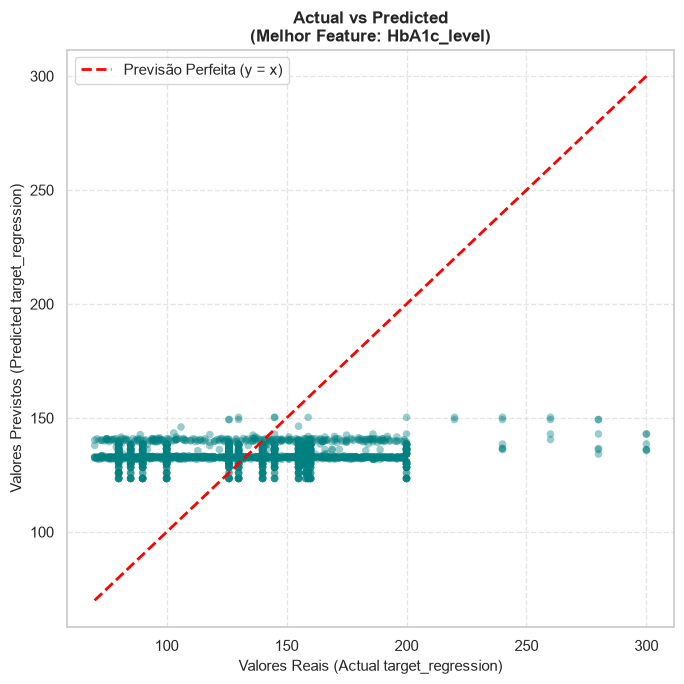

In [74]:
# Garantir que usas a melhor feature
best_feature = results_df.loc[0, "Feature"]

X_best = df_encoded[[best_feature]]
y_true = df_encoded[target_col]

# Treinar o modelo com a melhor feature
reg_model = LinearRegression()
reg_model.fit(X_best, y_true)
y_pred = reg_model.predict(X_best)

# Criar o gráfico Actual vs Predicted
plt.figure(figsize=(7, 7))
plt.scatter(y_true, y_pred, alpha=0.4, color="teal", edgecolor="none", s=30)

# Desenhar a linha diagonal perfeita (y = x)
min_val = min(y_true.min(), y_pred.min())
max_val = max(y_true.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=2, label="Previsão Perfeita (y = x)")

plt.title(f"Actual vs Predicted\n(Melhor Feature: {best_feature})", fontsize=12, fontweight="bold")
plt.xlabel("Valores Reais (Actual target_regression)", fontsize=11)
plt.ylabel("Valores Previstos (Predicted target_regression)", fontsize=11)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Análise Crítica dos Resultados (Regressão Linear Simples)

1. **Poder Preditivo Praticamente Nulo ($R^2$ muito baixo):**
   * O coeficiente de determinação obtido é de **$R^2 = 0.0126$** (cerca de 1.26%). 
   * Isto significa que a melhor *feature* isolada (`HbA1c_level`) consegue explicar apenas cerca de **1.2% da variabilidade** da variável resposta `target_regression`. O modelo apresenta, portanto, um desempenho linear univariado extremamente fraco.

2. **Evidência Gráfica (Comportamento Horizontal):**
   * Visualmente, a dispersão dos pontos contrasta fortemente com a linha vermelha tracejada de **Previsão Perfeita ($y = x$)**. 
   * Em vez de acompanharem a diagonal, os pontos formam bandas horizontais concentradas numa faixa estreita de valores previstos (entre aproximadamente 120 e 150), independentemente de os valores reais variarem amplamente (desde abaixo de 100 até 300).
   * Isto demonstra que o modelo é incapaz de capturar as variações reais da variável dependente, prevendo quase sempre um valor médio constante ditado pelo declive reduzido ($\beta_1 = 4.8733$).

3. **Conclusão e Próximos Passos:**
   * Este resultado evidencia que uma abordagem de **Regressão Linear Simples** baseada num único preditor isolado é insuficiente para modelar este problema de forma eficaz. 
   * Esta limitação justifica plenamente a transição para a **Regressão Linear Múltipla**, onde a combinação de múltiplos preditores poderá capturar melhor a complexidade subjacente aos dados.

---
## Regressão Linear Múltipla (`target_regression`)

Ponto 3 do enunciado: ajustar um modelo de regressão linear múltipla com várias *features*, experimentar combinações de variáveis, escolher o grupo com melhor desempenho e avaliá-lo com $R^2$, MAE e RMSE.

O notebook segue os slides de *Linear Regression* e responde às quatro perguntas que os slides colocam a um modelo de regressão:

| Pergunta dos slides | Secção |
|---|---|
| 1. Que preditores são úteis? | 5 |
| 2. São todos úteis, ou só um subconjunto? | 6 |
| 3. Quão bem se ajusta o modelo? | 7 |
| 4. Dados novos valores dos preditores, que resposta prever? | 8 |
| Comparação com a regressão simples (enunciado) | 10 |

Ferramentas (as dos slides): `smf.ols` (*statsmodels*) para coeficientes e p-values, `LinearRegression` (*scikit-learn*) para ajustar e prever, `r2_score` e `mean_squared_error` para avaliar, e `corr()` para ver correlações.

In [75]:
import statsmodels.formula.api as smf
import sklearn.linear_model as skl_lm

### 1. Dados e codificação

`target_regression` é a resposta $Y$. A regressão linear só aceita preditores numéricos, por isso as variáveis categóricas são codificadas (a mesma lógica do `task1`):

| Tipo | Variáveis | Codificação |
|---|---|---|
| ordinal | `physical_activity`, `stress_level`, `sugar_consumption` | 1, 2, 3 pela ordem natural |
| binária | `gender`, `family_history`, `low_hdl_cholesterol`, `high_ldl_cholesterol` | 0/1 (`Female` e `Yes` = 1) |
| nominal | `smoking`, `education_level`, `employment_status` | *dummies* 0/1; a primeira categoria fica como **referência** (`Never`, `Primary`, `Unemployed`) |

Ficam fora `target_class` (é o alvo da classificação), `bmi_level` e `age_level` (são `bmi` e `age` em categorias).

In [76]:
target = "target_regression"
data = df.drop(columns=["target_class", "bmi_level", "age_level"])

# ordinais: ordem natural
for col in ["physical_activity", "stress_level", "sugar_consumption"]:
    data[col] = data[col].map({"Low": 1, "Moderate": 2, "Medium": 2, "High": 3})

# binárias: 0/1
data["gender"] = (data["gender"] == "Female").astype(int)
for col in ["family_history", "low_hdl_cholesterol", "high_ldl_cholesterol"]:
    data[col] = (data[col] == "Yes").astype(int)

# nominais: dummies; a primeira categoria de cada lista é a referência
nominal = {
    "smoking": ["Never", "Former", "Current"],
    "education_level": ["Primary", "Secondary", "Tertiary"],
    "employment_status": ["Unemployed", "Employed", "Retired"],
}
for col, categories in nominal.items():
    data[col] = pd.Categorical(data[col], categories=categories)
data = pd.get_dummies(data, columns=list(nominal), drop_first=True, dtype=int)

predictors = [col for col in data.columns if col != target]
print(f"{len(predictors)} preditores candidatos | valores em falta: {data.isna().sum().sum()}")

34 preditores candidatos | valores em falta: 0


### 2. Partição *hold-out* (80% treino, 20% teste)

A partição faz-se uma só vez. Todas as escolhas (que preditores usar, que grupo escolher) usam **só o treino**; o teste serve apenas para avaliar no fim.

In [77]:
train, test = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE)
y_train, y_test = train[target], test[target]

print(f"Treino: {len(train)} | Teste: {len(test)}")
display(y_train.describe().round(2).to_frame(target))

Treino: 1600 | Teste: 400


,target_regression
count,1600.00
mean,133.29
std,38.64
min,70.00
25%,100.00
50%,133.50
75%,159.00
max,300.00


**Leitura:** o alvo tem média ≈ 133 e desvio-padrão ≈ 39 no treino. O desvio-padrão é a referência para julgar os erros: prever sempre a média dá um RMSE da ordem de 39.


### 3. Correlação entre preditores e matriz $X^TX$

Nos slides, o modelo múltiplo tem solução única, $\hat\beta = (X^TX)^{-1}X^Ty$, **se $X^TX$ for não singular**, isto é, se nenhuma coluna for combinação linear das outras. Como no `advertising.corr()` dos slides, procuram-se colunas constantes e pares de preditores muito correlacionados ($|r| \geq 0{,}8$).

In [78]:
corr = train[predictors].corr()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs = pairs[pairs.abs() >= 0.8].rename("r").to_frame()

print("Colunas constantes:", [col for col in predictors if train[col].nunique() == 1])
print("Pares com |r| >= 0.8:")
display(pairs.round(4))

Colunas constantes: ['calcium_baseline']
Pares com |r| >= 0.8:


,,r
age,age_normalized,1.0
systolic_bp,systolic_index,1.0


**Leitura:** `calcium_baseline` é constante (igual à coluna de 1s do termo constante), `age_normalized` é `age` em escala 0-1 e `systolic_index` é `systolic_bp` reescalada ($r = 1$). São redundantes e tornam $X^TX$ singular, por isso retiram-se. Ficam 31 preditores (`clean`).

In [79]:
drop = ["calcium_baseline", "age_normalized", "systolic_index"]
clean = [col for col in predictors if col not in drop]

for name, cols in {"candidatos": predictors, "clean": clean}.items():
    X = np.column_stack([np.ones(len(train)), train[cols]])
    print(f"{name}: {X.shape[1]} colunas em X (com a coluna de 1s) | característica (rank) = {np.linalg.matrix_rank(X)}")

candidatos: 35 colunas em X (com a coluna de 1s) | característica (rank) = 33
clean: 32 colunas em X (com a coluna de 1s) | característica (rank) = 32


**Leitura:** com os candidatos, a característica é inferior ao número de colunas (há colunas dependentes e $X^TX$ é singular). Com `clean` é igual ao número de colunas, por isso há solução única.

### Escala dos preditores

Os preditores têm unidades muito diferentes. Verifica-se se isso afeta o modelo, comparando as previsões com e sem normalização (média 0, desvio-padrão 1, calculados no treino).

In [80]:
std = train[clean].std()
print(f"Desvio-padrão dos preditores: de {std.min():.2f} ({std.idxmin()}) a {std.max():.2f} ({std.idxmax()})")

scaler = StandardScaler().fit(train[clean])
raw_model = skl_lm.LinearRegression().fit(train[clean], y_train)
scaled_model = skl_lm.LinearRegression().fit(scaler.transform(train[clean]), y_train)
same = np.allclose(raw_model.predict(test[clean]), scaled_model.predict(scaler.transform(test[clean])))
print("Previsões no teste iguais com e sem normalização:", same)

Desvio-padrão dos preditores: de 0.15 (plasma_value) a 66.54 (triglycerides)
Previsões no teste iguais com e sem normalização: True


**Leitura:** os preditores **não** estão normalizados, mas para mínimos quadrados isso não muda as previsões (reescalar uma coluna só reescala o seu coeficiente), logo $R^2$, MAE e RMSE são os mesmos. Por isso usam-se as variáveis originais. A escala só importaria para comparar o tamanho dos coeficientes entre preditores e em métodos com penalização (Ridge e Lasso).

### 4. Modelo com todos os preditores

Ajusta-se `target_regression` com os 31 preditores `clean` por mínimos quadrados, como no slide `smf.ols('sales ~ TV + radio + newspaper', ...)`.

In [81]:
est = smf.ols(f"{target} ~ " + " + ".join(clean), train).fit()

print(f"R2 = {est.rsquared:.4f} | R2 ajustado = {est.rsquared_adj:.4f} | F = {est.fvalue:.2f} (p = {est.f_pvalue:.4f})")
display(est.summary().tables[1])

R2 = 0.0306 | R2 ajustado = 0.0114 | F = 1.60 (p = 0.0201)


,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,22.1233,49.851,0.444,0.657,-75.658,119.904
gender,1.9828,1.993,0.995,0.320,-1.927,5.893
age,0.0395,0.048,0.826,0.409,-0.054,0.133
bmi,0.2746,0.139,1.976,0.048,0.002,0.547
HbA1c_level,3.9346,1.129,3.486,0.001,1.720,6.149
cholesterol,-0.0035,0.029,-0.119,0.906,-0.061,0.054
sleep_hours,1.5160,0.724,2.093,0.037,0.095,2.937
triglycerides,0.0084,0.017,0.499,0.618,-0.025,0.041
physical_activity,-0.0780,1.230,-0.063,0.949,-2.490,2.334
family_history,-0.9401,2.015,-0.467,0.641,-4.892,3.012


**Como ler a tabela:** cada linha é um preditor (o `Intercept` é o valor previsto quando todos valem 0).

| Coluna | Significado |
|---|---|
| `coef` | quanto muda o alvo por +1 unidade do preditor, com os outros fixos |
| `std err` | incerteza da estimativa |
| `t` | `coef / std err` (acima de ≈ 2 em valor absoluto destaca-se do ruído) |
| `P>\|t\|` | p-value do teste $H_0: \beta_j = 0$ (preditor sem relação com $Y$) |
| `[0.025 0.975]` | intervalo de confiança a 95%; se inclui 0, o efeito não se distingue de nenhum efeito |

### 5. Pergunta 1: que preditores são úteis?

Um p-value pequeno (< 0,05) leva a rejeitar $H_0: \beta_j = 0$. O teste F verifica se pelo menos um coeficiente é diferente de zero.

In [82]:
pvalues = est.pvalues.drop("Intercept").sort_values()
significant = pvalues[pvalues < 0.05].index.tolist()

display(pd.DataFrame({"coef": est.params[significant], "p-value": pvalues[significant]}).round(4))
print(f"Preditores com p-value < 0.05: {len(significant)} em {len(clean)}")
print(f"Esperados por acaso a 5%: cerca de {0.05 * len(clean):.1f}")

,coef,p-value
HbA1c_level,3.9346,0.0005
sleep_hours,1.5160,0.0365
high_ldl_cholesterol,-5.4251,0.0372
bmi,0.2746,0.0484


Preditores com p-value < 0.05: 4 em 31
Esperados por acaso a 5%: cerca de 1.6


### 6. Pergunta 2: todos os preditores ou só um subconjunto?

Comparam-se grupos de preditores, cada um ajustado no treino com `LinearRegression`:

- **Todos**: os 31 preditores `clean`;
- **Significativos**: os da pergunta 1 (p < 0,05);
- **Top-k**: os $k$ preditores com maior $|r|$ com o alvo no treino ($k$ = 1, 3, 5, 10);
- **Baseline**: prever sempre a média do treino.

**Como escolher sem usar o teste?** Com validação cruzada de 5 partes dentro do treino: escolhe-se o grupo com menor RMSE médio nas 5 partes. O teste só serve para avaliar o grupo escolhido, com $R^2$, MAE e RMSE.

In [83]:
def rmse(y_true, y_pred):
    return mean_squared_error(y_true, y_pred) ** 0.5

ranked = train[clean].corrwith(y_train).abs().sort_values(ascending=False).index.tolist()
groups = {
    "Todos": clean,
    "Significativos": significant,
    "Top-1": ranked[:1],
    "Top-3": ranked[:3],
    "Top-5": ranked[:5],
    "Top-10": ranked[:10],
}
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluate(model, cols):
    model.fit(train[cols], y_train)
    pred_test = model.predict(test[cols])
    cv_rmse = -cross_val_score(model, train[cols], y_train, cv=cv, scoring="neg_root_mean_squared_error").mean()
    return {
        "nº preditores": len(cols),
        "RMSE validação cruzada": cv_rmse,
        "R2 treino": r2_score(y_train, model.predict(train[cols])),
        "R2 teste": r2_score(y_test, pred_test),
        "MAE teste": mean_absolute_error(y_test, pred_test),
        "RMSE teste": rmse(y_test, pred_test),
    }

results = pd.DataFrame({name: evaluate(skl_lm.LinearRegression(), cols) for name, cols in groups.items()}).T
results.loc["Baseline (média do treino)"] = evaluate(DummyRegressor(strategy="mean"), ["age"])
results["nº preditores"] = results["nº preditores"].astype(int)
results.loc["Baseline (média do treino)", "nº preditores"] = 0
display(results.round(4))

candidates = results.drop("Baseline (média do treino)")
best_name = candidates["RMSE validação cruzada"].idxmin()
best_cols = groups[best_name]
print(f"Grupo escolhido (menor RMSE na validação cruzada): {best_name} -> {best_cols}")

,nº preditores,RMSE validação cruzada,R2 treino,R2 teste,MAE teste,RMSE teste
Todos,31,38.8030,0.0306,0.0063,32.3367,38.9421
Significativos,4,38.4397,0.0150,0.0202,32.0733,38.6687
Top-1,1,38.4810,0.0083,0.0209,31.8686,38.6552
Top-3,3,38.4196,0.0147,0.0180,32.0442,38.7135
Top-5,5,38.4298,0.0177,0.0185,32.0193,38.7024
Top-10,10,38.4333,0.0231,0.0210,32.1045,38.6540
Baseline (média do treino),0,38.6261,0.0000,-0.0068,32.2355,39.1987


Grupo escolhido (menor RMSE na validação cruzada): Top-3 -> ['HbA1c_level', 'employment_status_Retired', 'sleep_hours']


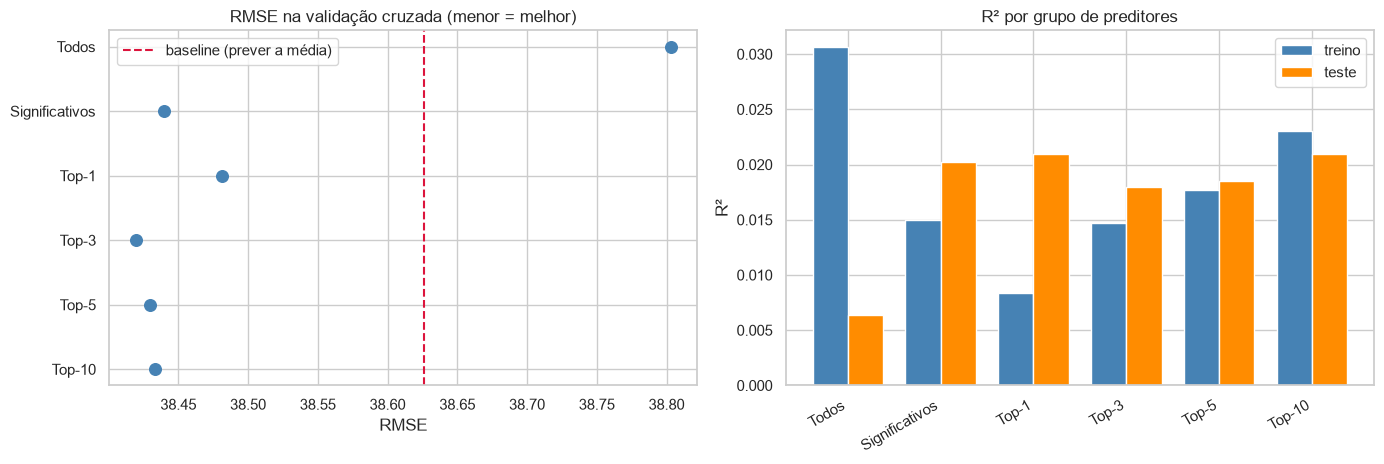

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
plot = results.drop("Baseline (média do treino)")

axes[0].scatter(plot["RMSE validação cruzada"], plot.index, s=70, color="steelblue", zorder=2)
axes[0].axvline(results.loc["Baseline (média do treino)", "RMSE validação cruzada"], color="crimson", ls="--",
                label="baseline (prever a média)")
axes[0].invert_yaxis()
axes[0].set(title="RMSE na validação cruzada (menor = melhor)", xlabel="RMSE")
axes[0].legend()

x = np.arange(len(plot))
axes[1].bar(x - 0.19, plot["R2 treino"], 0.38, label="treino", color="steelblue")
axes[1].bar(x + 0.19, plot["R2 teste"], 0.38, label="teste", color="darkorange")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(plot.index, rotation=30, ha="right")
axes[1].set(title="R² por grupo de preditores", ylabel="R²")
axes[1].legend()

plt.tight_layout()
plt.show()

**Leitura:**
- **Todos os preditores é o pior grupo:** tem o $R^2$ de treino mais alto (0,031) mas o de teste mais baixo (0,006) e o pior RMSE na validação cruzada (38,80, pior do que os 38,63 da baseline). Os preditores a mais ajustam ruído (sobreajuste).
- **Os grupos pequenos são equivalentes:** o RMSE na validação cruzada fica entre 38,42 e 38,48, e todos batem a baseline. O menor é o do `Top-3`, e é esse o grupo escolhido, por a regra não usar o teste. No teste, os grupos pequenos ficam todos entre 38,65 e 38,71 de RMSE, pelo que a ordem entre eles é ruído.
- **Porque não escolher pelo teste?** Escolher o melhor no teste e depois reportar esse mesmo valor seria otimista. Assim, o resultado do grupo escolhido no teste é uma estimativa honesta.
- **Limitação:** os grupos `Significativos` e `Top-k` foram escolhidos com todo o treino, por isso o seu RMSE de validação cruzada é ligeiramente otimista face ao de `Todos`. O teste não foi usado em nenhuma escolha.

#### Seleção *forward*: uma pesquisa mais sistemática

Os grupos acima são só 6 das combinações possíveis, e testar todas é inviável ($2^{31} \approx 2{,}1 \times 10^9$). Usa-se por isso a seleção *forward*: começa-se sem preditores e, em cada passo, entra o que mais baixa o RMSE na validação cruzada (as mesmas 5 partes do treino). Ajustam-se $31 + 30 + \dots + 1 = 496$ modelos. O teste continua sem ser usado para escolher.

Mínimo com 12 preditores (RMSE na validação cruzada = 38.3568)


,entra,RMSE validação cruzada
nº preditores,,
1,HbA1c_level,38.4810
2,employment_status_Employed,38.4447
3,sleep_hours,38.4214
4,systolic_bp,38.4092
5,gender,38.3980
6,stress_level,38.3849
7,high_ldl_cholesterol,38.3746
8,education_level_Tertiary,38.3666
9,diastolic_bp,38.3649


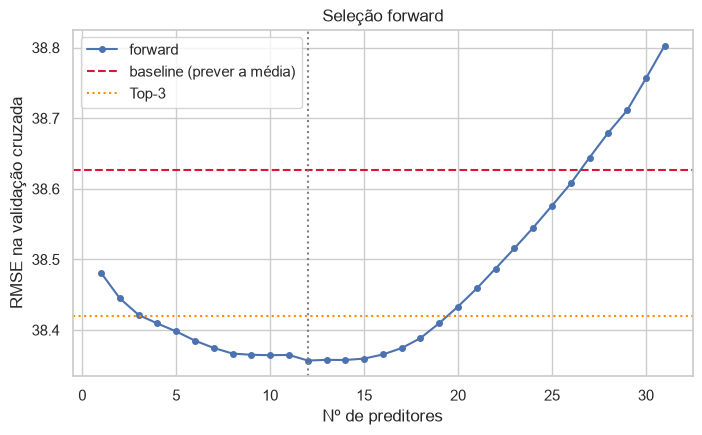

,nº preditores,RMSE validação cruzada,R2 treino,R2 teste,MAE teste,RMSE teste
Top-3 (escolhido),3,38.4196,0.0147,0.0180,32.0442,38.7135
Forward (k = 12),12,38.3568,0.0246,0.0215,31.9900,38.6436


In [85]:
selected, remaining, steps = [], list(clean), []
while remaining:
    scores = {col: -cross_val_score(skl_lm.LinearRegression(), train[selected + [col]], y_train,
                                    cv=cv, scoring="neg_root_mean_squared_error").mean()
              for col in remaining}
    entry = min(scores, key=scores.get)
    selected.append(entry)
    remaining.remove(entry)
    steps.append({"nº preditores": len(selected), "entra": entry, "RMSE validação cruzada": scores[entry]})
steps = pd.DataFrame(steps).set_index("nº preditores")

k_best = int(steps["RMSE validação cruzada"].idxmin())
forward_cols = selected[:k_best]
print(f"Mínimo com {k_best} preditores (RMSE na validação cruzada = {steps['RMSE validação cruzada'].min():.4f})")
display(steps.head(k_best).round(4))

plt.figure(figsize=(8, 4.5))
plt.plot(steps.index, steps["RMSE validação cruzada"], marker="o", ms=4, label="forward")
plt.axhline(results.loc["Baseline (média do treino)", "RMSE validação cruzada"], color="crimson", ls="--",
            label="baseline (prever a média)")
plt.axhline(results.loc["Top-3", "RMSE validação cruzada"], color="darkorange", ls=":", label="Top-3")
plt.axvline(k_best, color="gray", ls=":")
plt.xlabel("Nº de preditores")
plt.ylabel("RMSE na validação cruzada")
plt.title("Seleção forward")
plt.legend()
plt.show()

compare_fw = pd.DataFrame({
    "Top-3 (escolhido)": evaluate(skl_lm.LinearRegression(), best_cols),
    f"Forward (k = {k_best})": evaluate(skl_lm.LinearRegression(), forward_cols),
}).T
compare_fw["nº preditores"] = compare_fw["nº preditores"].astype(int)
display(compare_fw.round(4))

**Leitura:**
- Os primeiros preditores a entrar são `HbA1c_level`, `employment_status_Employed` e `sleep_hours`, quase os mesmos do `Top-3` (muda só a categoria de `employment_status` que entra: *Employed* em vez de *Retired*).
- A curva é quase plana: o RMSE na validação cruzada passa de 38,48 com 1 preditor para 38,36 no mínimo (12 preditores) e volta a subir com os 31 (38,80). A diferença entre 3 e 12 preditores (≈ 0,06) é muito menor do que a variação entre partes da validação cruzada (desvio-padrão ≈ 1,3).
- No teste, o modelo com 12 preditores é equivalente ao `Top-3` ($R^2$ de 0,022 contra 0,018; RMSE de 38,64 contra 38,71).
- Mantém-se o `Top-3`: o ganho está dentro do ruído, usa menos preditores e o RMSE de validação cruzada do *forward* é otimista, porque os mesmos dados serviram para escolher os preditores e para os avaliar.

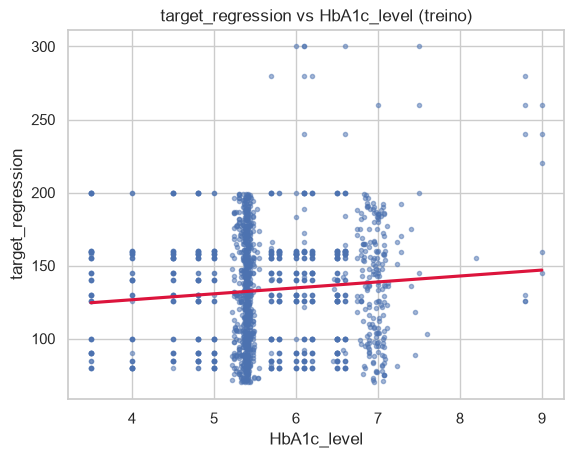

Só com HbA1c_level: declive = 4.06 | R2 = 0.0083


In [86]:
sns.regplot(x="HbA1c_level", y=target, data=train, order=1, ci=None,
            scatter_kws={"s": 9, "alpha": 0.5}, line_kws={"color": "crimson"})
plt.title("target_regression vs HbA1c_level (treino)")
plt.show()

simple = smf.ols(f"{target} ~ HbA1c_level", train).fit()
print(f"Só com HbA1c_level: declive = {simple.params['HbA1c_level']:.2f} | R2 = {simple.rsquared:.4f}")

**Leitura:** o teste F rejeita $H_0$ (p ≈ 0,020), mas o $R^2$ é muito baixo (0,031) e o $R^2$ ajustado ainda mais (0,011). Só quatro preditores têm p-value < 0,05: `HbA1c_level` (p ≈ 0,0005), `sleep_hours`, `high_ldl_cholesterol` e `bmi` (os três por pouco, entre 0,037 e 0,048). Com 31 testes esperam-se cerca de 1,6 resultados "significativos" só por acaso, por isso só `HbA1c_level` é claramente forte. Mesmo esse tem uma reta quase plana face à nuvem de pontos: o efeito existe (+4 no alvo por unidade de HbA1c), mas explica menos de 1% da variância.

### 7. Pergunta 3: quão bem se ajusta o modelo?

$R^2$ é a proporção da variância explicada: $R^2 = \dfrac{TSS - RSS}{TSS} = 1 - \dfrac{RSS}{TSS}$, com $RSS = \sum(y_i - \hat y_i)^2$ e $TSS = \sum(y_i - \bar y)^2$. Avalia-se o grupo escolhido no treino e no teste, e compara-se com a baseline (prever a média).

In [87]:
final = skl_lm.LinearRegression().fit(train[best_cols], y_train)
pred_train, pred_test = final.predict(train[best_cols]), final.predict(test[best_cols])
pred_base = np.full(len(test), y_train.mean())

rss = ((y_train - pred_train) ** 2).sum()
tss = ((y_train - y_train.mean()) ** 2).sum()
print(f"Treino: RSS = {rss:,.0f} | TSS = {tss:,.0f} | 1 - RSS/TSS = {1 - rss / tss:.4f} (r2_score: {r2_score(y_train, pred_train):.4f})")

metrics = pd.DataFrame({
    "R2": [r2_score(y_train, pred_train), r2_score(y_test, pred_test), r2_score(y_test, pred_base)],
    "MAE": [mean_absolute_error(y_train, pred_train), mean_absolute_error(y_test, pred_test), mean_absolute_error(y_test, pred_base)],
    "RMSE": [rmse(y_train, pred_train), rmse(y_test, pred_test), rmse(y_test, pred_base)],
}, index=["modelo (treino)", "modelo (teste)", "baseline (teste)"])
display(metrics.round(4))

Treino: RSS = 2,351,917 | TSS = 2,387,113 | 1 - RSS/TSS = 0.0147 (r2_score: 0.0147)


,R2,MAE,RMSE
modelo (treino),0.0147,31.8082,38.3399
modelo (teste),0.0180,32.0442,38.7135
baseline (teste),-0.0068,32.2355,39.1987


In [88]:
est_final = smf.ols(f"{target} ~ " + " + ".join(best_cols), train).fit()
print(f"F = {est_final.fvalue:.2f} (p = {est_final.f_pvalue:.5f}) | R2 ajustado = {est_final.rsquared_adj:.4f}")
display(est_final.summary().tables[1])

same_coef = np.allclose(est_final.params.drop("Intercept"), final.coef_) and np.isclose(est_final.params["Intercept"], final.intercept_)
print("statsmodels e scikit-learn dão os mesmos coeficientes:", same_coef)

F = 7.96 (p = 0.00003) | R2 ajustado = 0.0129


,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,101.4070,8.087,12.540,0.000,85.545,117.269
HbA1c_level,4.0756,1.106,3.684,0.000,1.906,6.245
employment_status_Retired,-4.7621,2.020,-2.357,0.019,-8.725,-0.799
sleep_hours,1.5227,0.712,2.139,0.033,0.126,2.919


statsmodels e scikit-learn dão os mesmos coeficientes: True


**Leitura:**
- O modelo explica ≈ 1,5% da variância no treino e ≈ 1,8% no teste. O teste F é significativo (p < 0,001) e os três coeficientes têm p < 0,05: há relação, mas muito pequena.
- Teste ligeiramente acima do treino não indica sobreajuste: com um ajuste tão fraco, a diferença é variação da partição.
- No teste, o RMSE (38,71) e o MAE (32,04) ficam pouco abaixo dos da baseline (39,20 e 32,24). O ganho é pequeno.
- Os coeficientes lêem-se "com os outros fixos": +1 unidade de `HbA1c_level` soma ≈ 4,08 ao alvo, +1 hora de `sleep_hours` soma ≈ 1,52, e ser reformado (`employment_status_Retired`) desce ≈ 4,76 face ao grupo de referência (`Unemployed`).
- `statsmodels` e `scikit-learn` dão os mesmos coeficientes, como no slide de verificação cruzada.

### 8. Pergunta 4: previsões

Dados os valores dos preditores, o modelo devolve $\hat y = \hat\beta_0 + \hat\beta_1 x_1 + \dots + \hat\beta_p x_p$ (`model.predict`). Mostram-se previsões para observações do teste, que o modelo não viu no treino.

In [89]:
sample = pd.DataFrame({"real": y_test.values[:8], "previsto": pred_test[:8]})
sample["erro"] = sample["real"] - sample["previsto"]
display(sample.round(1))

print(f"MAE = {mean_absolute_error(y_test, pred_test):.2f} | RMSE = {rmse(y_test, pred_test):.2f} "
      f"| desvio-padrão de {target} no teste = {y_test.std():.2f}")

,real,previsto,erro
0,160.0,137.1,22.9
1,126.0,135.8,-9.8
2,280.0,137.8,142.2
3,152.0,132.1,19.9
4,80.0,136.5,-56.5
5,80.0,127.5,-47.5
6,85.0,137.3,-52.3
7,158.0,132.5,25.5


MAE = 32.04 | RMSE = 38.71 | desvio-padrão de target_regression no teste = 39.12


**Leitura:** nestas observações os valores previstos ficam todos entre ≈ 128 e 138, enquanto os reais vão de 80 a 280. O erro típico (MAE ≈ 32, RMSE ≈ 39) é do tamanho do desvio-padrão do próprio alvo (≈ 39): o modelo prevê pouco melhor do que a média.

### 9. Problemas potenciais do modelo

Os slides listam vários problemas possíveis, entre eles a não linearidade da relação e a variância não constante dos erros. A colinearidade entre preditores já foi tratada na secção 3. Para os outros dois usa-se o gráfico dos resíduos face aos valores ajustados, e compara-se o previsto com o real no teste.

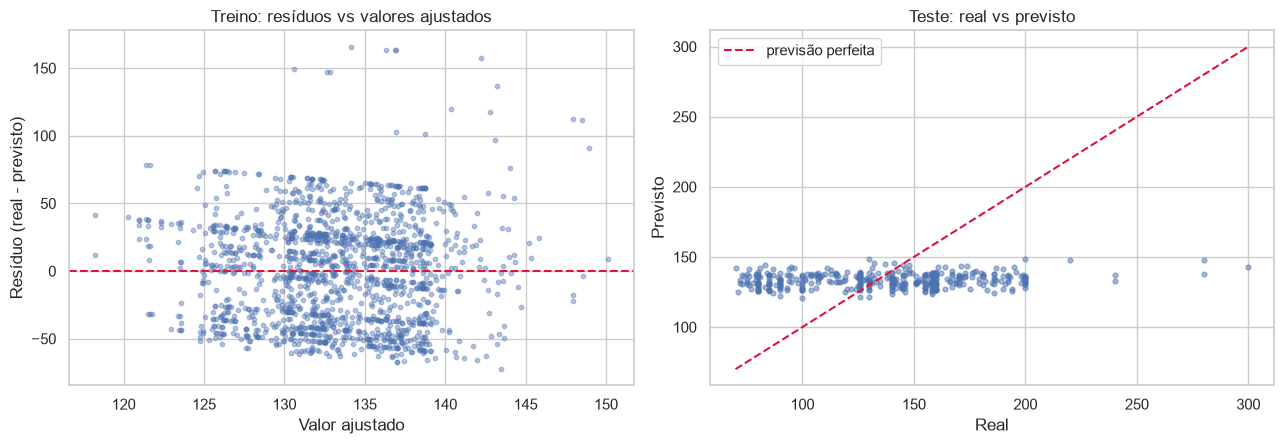

Desvio-padrão dos resíduos por terço dos valores ajustados (do mais baixo ao mais alto):
1.º terço    36.18
2.º terço    37.40
3.º terço    41.39


In [90]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

axes[0].scatter(pred_train, y_train - pred_train, s=10, alpha=0.4)
axes[0].axhline(0, color="crimson", ls="--")
axes[0].set(title="Treino: resíduos vs valores ajustados", xlabel="Valor ajustado", ylabel="Resíduo (real - previsto)")

axes[1].scatter(y_test, pred_test, s=12, alpha=0.5)
lims = [y_test.min(), y_test.max()]
axes[1].plot(lims, lims, color="crimson", ls="--", label="previsão perfeita")
axes[1].set(title="Teste: real vs previsto", xlabel="Real", ylabel="Previsto")
axes[1].legend()

plt.tight_layout()
plt.show()

resid_train = y_train - pred_train
spread = resid_train.groupby(pd.qcut(pred_train, 3, labels=["1.º terço", "2.º terço", "3.º terço"]), observed=True).std()
print("Desvio-padrão dos resíduos por terço dos valores ajustados (do mais baixo ao mais alto):")
print(spread.round(2).to_string())

**Leitura:**
- Os valores ajustados ocupam uma faixa estreita (≈ 118 a 150), enquanto os reais vão de 70 a 300: o modelo explica pouco. Os resíduos reproduzem a dispersão do próprio alvo.
- Não se vê curvatura nos resíduos, pelo que este gráfico não mostra não linearidade. A dispersão dos resíduos sobe um pouco nos valores ajustados mais altos (36 para 41), o que é pouco para concluir variância não constante.
- Há valores reais muito acima do previsto (até 300) que o modelo não capta.

### 10. Comparação: regressão simples vs múltipla

O enunciado pede para comparar o modelo com uma só variável e o modelo com várias, com $R^2$, MAE e RMSE. O modelo simples usa o preditor com maior $|r|$ com o alvo no treino (o `Top-1` da secção 6). Ajusta-se no mesmo treino e avalia-se no mesmo teste que o modelo múltiplo escolhido, para os números serem comparáveis.

In [91]:
simple_col = ranked[0]
simple_model = skl_lm.LinearRegression().fit(train[[simple_col]], y_train)
pred_simple = simple_model.predict(test[[simple_col]])
print(f"Simples: {target} = {simple_model.intercept_:.2f} + {simple_model.coef_[0]:.2f} * {simple_col}")

models = {
    f"Simples ({simple_col})": pred_simple,
    f"Múltipla ({best_name}, {len(best_cols)} preditores)": pred_test,
    "Baseline (média do treino)": pred_base,
}
comparison = pd.DataFrame({
    name: {"R2": r2_score(y_test, p), "MAE": mean_absolute_error(y_test, p), "RMSE": rmse(y_test, p)}
    for name, p in models.items()
}).T
display(comparison.round(4))

Simples: target_regression = 110.37 + 4.06 * HbA1c_level


,R2,MAE,RMSE
Simples (HbA1c_level),0.0209,31.8686,38.6552
"Múltipla (Top-3, 3 preditores)",0.0180,32.0442,38.7135
Baseline (média do treino),-0.0068,32.2355,39.1987


**Leitura:**
- No teste, o modelo simples e o múltiplo ficam praticamente iguais nos três indicadores (a diferença de RMSE é de 0,06) e ambos melhoram ligeiramente a baseline.
- Acrescentar `employment_status_Retired` e `sleep_hours` a `HbA1c_level` não melhorou o teste ($R^2$ de 0,018 contra 0,021). Na validação cruzada o múltiplo é um pouco melhor (RMSE 38,42 contra 38,48), mas a ordem inverte-se no teste: a diferença entre os dois é ruído da partição.
- Quase toda a informação útil está em `HbA1c_level`. Com $R^2$ ≈ 0,02, nenhum dos modelos prevê bem `target_regression`.

### 11. Conclusões

- **Preditores úteis:** só `HbA1c_level` (p ≈ 0,0005), `sleep_hours`, `high_ldl_cholesterol` e `bmi` têm p-value < 0,05 no modelo completo, com efeitos pequenos. Com 31 testes, parte disto pode ser acaso.
- **Todos ou subconjunto:** usar todos os preditores é pior (sobreajuste). Com validação cruzada no treino, o grupo escolhido foi `Top-3`: `HbA1c_level`, `employment_status_Retired` e `sleep_hours`.
- **Seleção forward:** a pesquisa passo a passo põe à cabeça os mesmos preditores; o mínimo (12 preditores) é equivalente ao `Top-3` dentro do ruído, que se mantém por ser mais simples.
- **Ajuste:** $R^2$ ≈ 0,015 no treino e ≈ 0,018 no teste; MAE ≈ 32,0 e RMSE ≈ 38,7 no teste, contra 32,2 e 39,2 de prever sempre a média.
- **Simples vs múltipla:** no teste, `HbA1c_level` sozinha e o grupo `Top-3` têm desempenho equivalente (RMSE ≈ 38,7 nos dois, contra 39,2 da baseline).
- **Previsões:** ficam perto da média; o erro é do tamanho do desvio-padrão do alvo.
- **Conclusão geral:** a regressão linear múltipla explica muito pouco de `target_regression`. Os slides indicam a não linearidade como causa possível; testar termos polinomiais fica fora do âmbito deste notebook.

---
## 4. Aplicação de Métodos – Classificação

## Logistic Regression vs Linear Discriminant Analysis (LDA)

**Objetivo:** O objetivo deste estudo é prever `target_class` (N, HY, DI) e comparar dois modelos de classificação: a regressão logística e a análise discriminante linear (LDA).

Ambos os modelos serão avaliados utilizando cinco abordagens de reamostragem:

1. Holdout
2. Validação cruzada em 5 dobras
3. Validação cruzada em 10 dobras
4. Validação cruzada «Leave-One-Out» (LOOCV)
5. Bootstrap

A análise irá comparar o desempenho preditivo e a variabilidade das métricas de avaliação entre os diferentes métodos de reamostragem.

Uma vez que a variável-alvo contém três classes de diagnóstico e que a distribuição das classes é desequilibrada, o Macro F1-score e a Precisão Equilibrada serão considerados a par da Precisão.

O objetivo final é identificar qual o modelo que oferece o melhor equilíbrio entre desempenho preditivo e estabilidade.

## 2. Análise inicial dos dados
Antes de treinar os modelos, analisamos a distribuição da variável-alvo, os tipos de dados, os valores em falta, as linhas duplicadas e os potenciais preditores redundantes.

Nesta fase, as colunas de preditores suspeitas não são automaticamente removidas. As suas características serão primeiro investigadas, para que qualquer decisão de as remover possa ser justificada com base em evidências.

As duas variáveis-alvo, `target_class` e `target_regression`, não devem ser incluídas entre os preditores.

Dataset dimensions: (2000, 35)
Duplicate rows: 0

Missing values per column:


age_level              0
gender                 0
bmi_level              0
smoking                0
age                    0
age_normalized         0
bmi                    0
HbA1c_level            0
cholesterol            0
sleep_hours            0
triglycerides          0
physical_activity      0
family_history         0
stress_level           0
low_hdl_cholesterol    0
dtype: int64


Data types:


,Data type
age_level,str
gender,str
bmi_level,str
smoking,str
age,int64
age_normalized,float64
bmi,float64
HbA1c_level,float64
cholesterol,float64
sleep_hours,float64



Target class distribution:


,Count,Percentage
target_class,,
N,998,49.90
HY,669,33.45
DI,333,16.65


Text(0.5, 1.0, 'Percentage of observations per class')

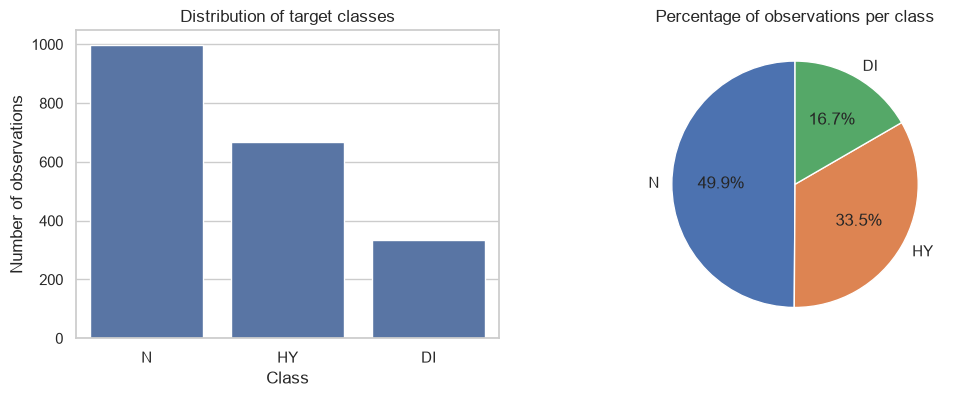

In [92]:
print("Dataset dimensions:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("\nMissing values per column:")
display(df.isna().sum().sort_values(ascending=False).head(15))

print("\nData types:")
display(df.dtypes.to_frame("Data type"))

if "target_class" not in df.columns:
    raise KeyError("A coluna 'target_class' não existe no dataset.")

print("\nTarget class distribution:")
display(
    df["target_class"]
      .value_counts()
      .rename("Count")
      .to_frame()
      .assign(
          Percentage=lambda x:
          (x["Count"] / len(df) * 100).round(2)
      )
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    data=df,
    x="target_class",
    order=df["target_class"].value_counts().index,
    ax=axes[0]
)
axes[0].set_title("Distribution of target classes")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Number of observations")

class_counts = df["target_class"].value_counts()
axes[1].pie(
    class_counts.values,
    labels=class_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Percentage of observations per class")

### 2.1 Variáveis preditoras potencialmente redundantes

A análise exploratória identificou algumas colunas que podem ser constantes, duplicadas ou derivadas de outras variáveis preditoras.

Entre os exemplos incluem-se `calcium_baseline`, `systolic_index` e `age_normalized`.

Estas variáveis não serão removidas automaticamente. Em primeiro lugar, iremos verificar a sua variância e as suas relações com outras variáveis.

Um preditor constante não contém informação que distinga as observações. Os preditores perfeitamente duplicados contêm informação redundante, embora a sua presença possa afetar os coeficientes do modelo e a estabilidade numérica.

A decisão final de remover uma coluna deve ser documentada e, quando útil, validada através da comparação do desempenho do modelo antes e
depois da remoção.

In [93]:
numeric_df = df.select_dtypes(include=np.number)

# Identificar colunas numéricas constantes
constant_columns = [
    col for col in numeric_df.columns
    if numeric_df[col].nunique(dropna=False) <= 1
]

print("Constant numeric columns:")
print(constant_columns)

# Identificar pares de colunas numéricas perfeitamente correlacionadas.
# A correlação não deteta todas as formas possíveis de duplicação,
# pelo que também verificamos igualdade exata.
numeric_predictors = numeric_df.drop(
    columns=["target_regression"],
    errors="ignore"
)

perfect_pairs = []

cols = numeric_predictors.columns.tolist()

for i, col1 in enumerate(cols):
    for col2 in cols[i + 1:]:
        s1 = numeric_predictors[col1]
        s2 = numeric_predictors[col2]

        if s1.equals(s2):
            perfect_pairs.append((col1, col2, "Exact equality"))
        elif s1.notna().all() and s2.notna().all():
            corr = s1.corr(s2)
            if np.isclose(abs(corr), 1.0, atol=1e-12):
                perfect_pairs.append(
                    (col1, col2, f"Correlation = {corr:.4f}")
                )

display(pd.DataFrame(
    perfect_pairs,
    columns=["Column 1", "Column 2", "Relationship"]
))

Constant numeric columns:
['calcium_baseline']


C:\Users\moale\AppData\Roaming\Python\Python313\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\moale\AppData\Roaming\Python\Python313\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,Column 1,Column 2,Relationship
0,age,age_normalized,Correlation = 1.0000
1,systolic_bp,systolic_index,Exact equality


## 3. Preparação dos dados

A variável-alvo é `target_class`. A coluna `target_regression` é excluída dos preditores, uma vez que representa uma variável-alvo distinta.

Os preditores categóricos devem ser convertidos em variáveis numéricas. Será aplicada a codificação «one-hot» às colunas categóricas que
ainda não tenham sido codificadas.

Nesta fase, nenhum preditor potencialmente redundante é removido automaticamente. Os preditores constantes e redundantes são analisados
separadamente acima.

Para uma comparação justa, ambos os modelos utilizarão as mesmas observações, preditores, divisões e métricas de avaliação.

In [94]:
target = "target_class"

# Copiar os dados para preservar o dataframe original
model_df = df.copy()

# Identificar as colunas-alvo
target_columns = ["target_class", "target_regression"]

# 1. Ordinal encoding
ordinal_mappings = {
    "bmi_level": {
        "Underweight": 1,
        "Normal": 2,
        "Overweight": 3,
        "Obese": 4
    },
    "physical_activity": {
        "Low": 1,
        "Moderate": 2,
        "High": 3
    },
    "stress_level": {
        "Low": 1,
        "Medium": 2,
        "High": 3
    },
    "sugar_consumption": {
        "Low": 1,
        "Medium": 2,
        "High": 3
    }
}

for column, mapping in ordinal_mappings.items():
    model_df[column] = model_df[column].map(mapping)


# 2. Binary encoding
binary_mappings = {
    "gender": {
        "Male": 0,
        "Female": 1
    },
    "family_history": {
        "No": 0,
        "Yes": 1
    },
    "low_hdl_cholesterol": {
        "No": 0,
        "Yes": 1
    },
    "high_ldl_cholesterol": {
        "No": 0,
        "Yes": 1
    }
}

for column, mapping in binary_mappings.items():
    model_df[column] = model_df[column].map(mapping)


# 3. One-hot encoding
one_hot_categories = {
    "age_level": ["Young", "Middle", "Mature", "Senior"],
    "smoking": ["Never", "Former", "Current"],
    "education_level": ["Primary", "Secondary", "Tertiary"],
    "employment_status": ["Unemployed", "Employed", "Retired"]
}

for column, categories in one_hot_categories.items():
    model_df[column] = pd.Categorical(
        model_df[column],
        categories=categories
    )

model_df = pd.get_dummies(
    model_df,
    columns=list(one_hot_categories.keys()),
    dtype=int
)


# 4. Separar a variável-alvo dos preditores
y = model_df[target].copy()

X_classification = model_df.drop(
    columns=target_columns,
    errors="ignore"
).copy()


# 5. Garantir que todos os preditores são numéricos
X_classification = X_classification.apply(pd.to_numeric, errors="raise")


# 6. Verificar valores em falta
if X_classification.isna().any().any():
    missing = X_classification.isna().sum()
    missing = missing[missing > 0]

    raise ValueError(
        "Existem valores em falta nos preditores:\n"
        f"{missing}"
    )

if y.isna().any():
    raise ValueError(
        "Existem valores em falta na variável-alvo."
    )


# 7. Verificar o resultado
print("X shape:", X_classification.shape)
print("y shape:", y.shape)

print("\nTarget classes:")
print(sorted(y.unique().tolist()))

print("\nTipos de dados dos preditores:")
display(X_classification.dtypes.to_frame("Data type"))

print("\nPrimeiras linhas de X:")
display(X_classification.head())

print("\nDistribuição das classes:")
display(y.value_counts().sort_index())

print("\nValores nulos em X:", X_classification.isna().sum().sum())
print("Valores nulos em y:", y.isna().sum())

X shape: (2000, 42)
y shape: (2000,)

Target classes:
['DI', 'HY', 'N']

Tipos de dados dos preditores:


,Data type
gender,int64
bmi_level,int64
age,int64
age_normalized,float64
bmi,float64
HbA1c_level,float64
cholesterol,float64
sleep_hours,float64
triglycerides,float64
physical_activity,int64



Primeiras linhas de X:


,gender,bmi_level,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,physical_activity,...,age_level_Senior,smoking_Never,smoking_Former,smoking_Current,education_level_Primary,education_level_Secondary,education_level_Tertiary,employment_status_Unemployed,employment_status_Employed,employment_status_Retired
0,0,4,44,0.482758,35.70,5.398540,250.000000,5.300000,235.000000,3,...,0,1,0,0,1,0,0,0,1,0
1,0,4,49,0.540230,34.97,6.500000,224.684501,7.060728,149.460563,2,...,0,0,1,0,0,1,0,1,0,0
2,0,1,4,0.022989,17.64,6.000000,228.130653,7.080402,156.115578,2,...,0,1,0,0,0,0,1,0,1,0
3,0,1,40,0.436781,17.30,5.421429,299.000000,9.500000,150.000000,1,...,0,0,0,1,1,0,0,0,1,0
4,1,2,27,0.287356,24.80,5.374373,277.000000,8.500000,187.000000,3,...,0,0,0,1,0,0,1,0,1,0



Distribuição das classes:


target_class
DI    333
HY    669
N     998
Name: count, dtype: int64


Valores nulos em X: 0
Valores nulos em y: 0


## 4. Modelos e métricas de avaliação

São considerados dois modelos de classificação:

- **Regressão logística**
- **Análise discriminante linear (LDA)**

O `StandardScaler` é incluído em cada pipeline para normalizar os valores dos preditores. Isto é particularmente importante para a regressão logística, onde a regularização pode ser afetada pela escala dos preditores.

Para a LDA, utiliza-se o `solver="lsqr"` com redução automática para melhorar a estimativa da matriz de covariância quando as variáveis preditoras estão correlacionadas e usamos LDA com `shrinkage="auto"` para regularizar a estimativa da covariância. Assim, a comparação é com LDA regularizado, não com LDA clássico sem shrinkage.

São apresentadas as seguintes métricas:

- Precisão
- Precisão equilibrada
- Precisão macro
- Recall macro
- F1-score macro

As médias macro atribuem igual importância a cada classe. Isto é útil quando as classes-alvo estão desequilibradas.

O F1-score macro será a principal métrica para a comparação de modelos.

In [95]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ]),

    "LDA": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearDiscriminantAnalysis(
            solver="lsqr",
            shrinkage="auto"
        ))
    ])
}

CLASS_LABELS = ["N", "HY", "DI"]

def calculate_metrics(y_true, y_pred):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1 macro": f1_score(
            y_true, y_pred,
            labels=CLASS_LABELS,
            average="macro",
            zero_division=0
        ),
        "Precision macro": precision_score(
            y_true, y_pred,
            labels=CLASS_LABELS,
            average="macro",
            zero_division=0
        ),
        "Recall macro": recall_score(
            y_true, y_pred,
            labels=CLASS_LABELS,
            average="macro",
            zero_division=0
        )
    }

metrics = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "f1_macro": "f1_macro",
    "recall_macro": "recall_macro",
    "precision_macro": "precision_macro"
}
metric_map = {
    "accuracy": "Accuracy",
    "balanced_accuracy": "Balanced accuracy",
    "f1_macro": "F1 macro",
    "recall_macro": "Recall macro",
    "precision_macro": "Precision macro"
}
print("Modelos:", list(models))

Modelos: ['Logistic Regression', 'LDA']


## 5. Definição das funções de avaliação

As funções seguintes são partilhadas pela Regressão Logística e pela LDA, garantindo que ambos os classificadores são avaliados segundo o mesmo protocolo. Os métodos de reamostragem diferem na forma como constroem as amostras de treino e de avaliação; por isso, as pontuações e estimativas de dispersão devem ser interpretadas tendo em conta essas diferenças.

A métrica principal é o **Macro F1**, uma vez que atribui igual importância às três classes-alvo e, por isso, é mais informativa do que a Acurácia quando as classes têm frequências diferentes. A **Acurácia Balanceada / Macro Recall** mede a média do recall por classe, enquanto a **Precisão Macro** complementa o recall ao descrever a fiabilidade das previsões para cada classe. A Acurácia é mantida como medida global de interpretação intuitiva.

Para CV-5 e CV-10, são apresentados a média e o desvio-padrão das pontuações por fold. O LOOCV produz uma previsão agregada *out-of-fold* para cada observação, pelo que não é significativo calcular um desvio-padrão entre folds. O Bootstrap apresenta a média e o desvio-padrão das iterações OOB válidas.

### 5.1. Holdout

O método Holdout divide o conjunto de dados em dois subconjuntos independentes: um conjunto de treino e um conjunto de teste.

Neste caso, 80% das observações são utilizadas para treino e 20% para teste. A estratificação preserva aproximadamente as mesmas proporções de classes em ambos os subconjuntos.

O modelo é ajustado apenas com base nos dados de treino. Todas as métricas de teste apresentadas são calculadas a partir de previsões sobre observações não utilizadas para ajustar o modelo.

In [96]:
X_train, X_test, y_train, y_test = train_test_split(
    X_classification,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

def run_holdout(model, X_train, X_test, y_train, y_test):

    start = time.perf_counter()

    fitted_model = clone(model)
    fitted_model.fit(X_train, y_train)

    y_pred = fitted_model.predict(X_test)

    elapsed = time.perf_counter() - start

    results = calculate_metrics(y_test, y_pred)

    results["Time (s)"] = elapsed

    return fitted_model, y_pred, pd.Series(results)

### 5.2. Validação cruzada em 5 e 10 partes

Na validação cruzada em 5 partes: 
 - O conjunto de dados é dividido em cinco partes.
 - Em cada iteração, quatro partes são utilizadas para treino e a parte restante é utilizada para validação. Este processo é repetido até que cada parte tenha servido como conjunto de validação uma vez.
 - A pontuação média estima o desempenho preditivo médio, enquanto o desvio padrão descreve a variação entre as partes de validação.

Na validação cruzada em 10 partes: 
 - O conjunto de dados é dividido em dez partes.
 - Cada modelo é treinado com aproximadamente 90% dos dados e avaliado com os restantes 10%. Cada observação é utilizada uma vez para validação.
 - Em comparação com a validação cruzada em 5 partes, cada subconjunto de treino é maior, mas há mais ajustes do modelo. A média e o desvio-padrão das pontuações das partes serão comparados com os resultados das 5 partes.

O StratifiedKFold preserva as proporções das classes em cada parte.

In [97]:
def run_cross_validation(model, X, y, n_splits, seed=42):

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=seed
    )

    start = time.perf_counter()

    result = cross_validate(
        clone(model),
        X,
        y,
        cv=cv,
        scoring=metrics,
        return_train_score=True,
        n_jobs=-1
    )

    elapsed = time.perf_counter() - start

    # Resultados de treino
    train_results = pd.DataFrame({
        metric_map[m]: result[f"train_{m}"]
        for m in metrics
    })

    # Resultados de teste
    test_results = pd.DataFrame({
        metric_map[m]: result[f"test_{m}"]
        for m in metrics
    })

    """train_results.index = [
        f"Fold {i}" for i in range(1, n_splits + 1)
    ]

    test_results.index = train_results.index"""

    # Identificação dos folds
    fold_names = [
        f"Fold {i}" for i in range(1, n_splits + 1)
    ]

    train_results.index = fold_names
    test_results.index = fold_names

    # Estatísticas dos resultados de treino e teste
    summary = pd.concat(
            {
                "Train": train_results.agg(
                    ["mean", "std", "min", "max"]
                ).T,
                "Test": test_results.agg(
                    ["mean", "std", "min", "max"]
                ).T
            },
            names=["Dataset", "Metric"]
        )

    summary["Time (s)"] = elapsed

    return train_results, test_results, summary

### 5.3. Validação cruzada Leave-One-Out (LOOCV)

A validação cruzada «Leave-One-Out» (LOOCV) é uma forma extrema de validação cruzada, na qual cada observação é utilizada uma vez como amostra de validação.

Para um conjunto de dados que contenha n observações, o modelo é ajustado n vezes. Cada ajuste utiliza n-1 observações e prevê a única observação que foi deixada de fora.

As métricas finais são calculadas combinando todas as previsões fora de cada dobra. Isto produz uma previsão para cada observação.

Ao contrário da validação k-fold comum, cada dobra de teste LOOCV contém apenas uma observação. Por conseguinte, apresentar o desvio-padrão do Macro F1 por dobra não seria significativo. Em vez disso, apresentamos as métricas agregadas obtidas a partir de todas as previsões LOOCV.

In [98]:
def run_loocv(model, X, y):

    cv = LeaveOneOut()

    start = time.perf_counter()

    y_pred = cross_val_predict(
        clone(model),
        X,
        y,
        cv=cv,
        method="predict",
        n_jobs=-1
    )

    elapsed = time.perf_counter() - start

    results = calculate_metrics(y, y_pred)

    results["Time (s)"] = elapsed

    return y_pred, pd.Series(results)

### 5.4. Bootstrap

O bootstrap faz amostragens repetidas de observações com reposição para criar conjuntos de dados de treino com o mesmo tamanho que o conjunto de dados original.

Em cada repetição, o modelo é treinado com base na amostra de bootstrap. As observações que não foram selecionadas nessa amostra são denominadas observações «out-of-bag» (OOB) e são utilizadas para avaliação.

As métricas OOB são registadas para cada repetição. A sua média e desvio padrão resumem o desempenho e a variabilidade ao longo das
repetições do bootstrap.

Uma repetição é ignorada se a sua amostra de treino não contiver todas as classes-alvo. Isto é necessário para uma avaliação multiclasse válida.

In [99]:
def generate_bootstrap_samples(y, n_iterations=200, seed=42):

    rng = np.random.default_rng(seed)

    bootstrap_samples = []

    y_array = np.asarray(y)
    indices = np.arange(len(y_array))

    for _ in range(n_iterations):

        train_indices = []

        # Amostragem estratificada por classe
        for class_label in np.unique(y_array):

            class_indices = indices[y_array == class_label]

            sampled_indices = rng.choice(
                class_indices,
                size=len(class_indices),
                replace=True
            )

            train_indices.extend(sampled_indices)

        train_indices = np.asarray(train_indices)

        # Índices que não foram selecionados
        oob_indices = np.setdiff1d(
            indices,
            np.unique(train_indices)
        )

        bootstrap_samples.append(
            (train_indices, oob_indices)
        )

    return bootstrap_samples

def run_bootstrap(model, X, y, bootstrap_samples):

    bootstrap_results = []

    start = time.perf_counter()

    for train_indices, oob_indices in bootstrap_samples:

        # Ignorar iterações sem observações OOB
        if len(oob_indices) == 0:
            continue

        X_bootstrap = X.iloc[train_indices]
        y_bootstrap = y.iloc[train_indices]

        X_oob = X.iloc[oob_indices]
        y_oob = y.iloc[oob_indices]

        fitted_model = clone(model)

        fitted_model.fit(
            X_bootstrap,
            y_bootstrap
        )

        y_pred = fitted_model.predict(X_oob)

        iteration_metrics = calculate_metrics(
            y_oob,
            y_pred
        )

        bootstrap_results.append(iteration_metrics)

    elapsed = time.perf_counter() - start

    # Resultados de todas as iterações
    results_df = pd.DataFrame(bootstrap_results)

    # Estatísticas das métricas
    summary = pd.DataFrame({
        "Mean": results_df.mean(),
        "Std": results_df.std(ddof=1),
        "Minimum": results_df.min(),
        "Maximum": results_df.max()
    })

    summary["Time (s)"] = elapsed
    summary["Number of iterations"] = len(results_df)

    return results_df, summary

bootstrap_samples = generate_bootstrap_samples(
    y,
    n_iterations=200,
    seed=RANDOM_STATE
)

## 6. Logistic Regression

### 6.1. Holdout

Logistic Regression — Holdout Metrics


,Accuracy,Balanced Accuracy,F1 macro,Precision macro,Recall macro,Time (s)
Logistic Regression — Holdout,0.73,0.7503,0.7502,0.7534,0.7503,0.0719


Classification Report
              precision    recall  f1-score   support

          DI       0.87      0.89      0.88        66
          HY       0.68      0.58      0.63       134
           N       0.71      0.78      0.74       200

    accuracy                           0.73       400
   macro avg       0.75      0.75      0.75       400
weighted avg       0.73      0.73      0.73       400



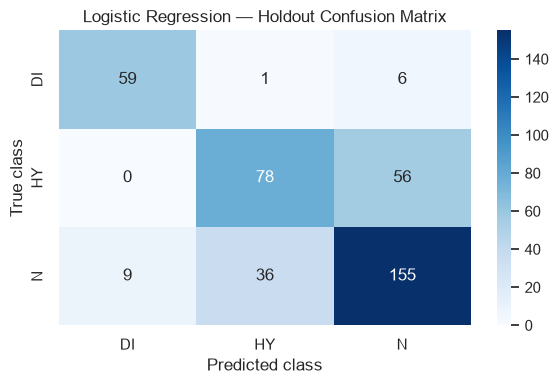

In [100]:
# Execute Holdout
lr_holdout_model, lr_holdout_pred, lr_holdout_results = run_holdout(
    models["Logistic Regression"],
    X_train,
    X_test,
    y_train,
    y_test
)

# Metrics
lr_holdout_results = pd.DataFrame(
    [lr_holdout_results],
    index=["Logistic Regression — Holdout"]
)

print("Logistic Regression — Holdout Metrics")
display(lr_holdout_results.round(4))

# Classification Report
print("Classification Report")

print(classification_report(
    y_test,
    lr_holdout_pred,
    labels=sorted(y.unique()),
    zero_division=0
))

# Confusion Matrix
labels = sorted(y.unique())

cm = confusion_matrix(
    y_test,
    lr_holdout_pred,
    labels=labels
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Logistic Regression — Holdout Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.tight_layout()
plt.show()

### Interpretação dos resultados

O Macro F1 obtido no Holdout é **0.7502**, com Accuracy Balanceada de **0.7503**. A Precisão Macro (**0.7534**) e o Macro Recall (**0.7503**) são próximos, sugerindo um equilíbrio relativamente adequado entre precisão e recall nesta partição específica.

Este é o resultado mais elevado da Regressão Logística entre as estimativas de reamostragem apresentadas; contudo, baseia-se numa única divisão aleatória entre treino e teste. Deve, por isso, ser considerado uma observação pontual, e não uma evidência conclusiva de que o modelo alcançará consistentemente este desempenho. O relatório por classe também deve ser analisado, uma vez que as métricas agregadas podem ocultar um desempenho inferior nas classes menos representadas.

### 6.2. Validação cruzada em 5 partes

In [101]:
lr_cv5_train, lr_cv5_test, lr_cv5_summary = run_cross_validation(
    models["Logistic Regression"],
    X_classification,
    y,
    n_splits=5,
    seed=RANDOM_STATE
)

print("Logistic Regression — 5-Fold Cross-Validation Results")
print("Train Results:")
display(lr_cv5_train.round(4))

print("Test Results:")
display(lr_cv5_test.round(4))

print("Summary of Test Results:")
display(lr_cv5_summary.round(4))

Logistic Regression — 5-Fold Cross-Validation Results
Train Results:


,Accuracy,Balanced accuracy,F1 macro,Recall macro,Precision macro
Fold 1,0.7362,0.7549,0.7574,0.7549,0.7649
Fold 2,0.7406,0.7613,0.7647,0.7613,0.7710
Fold 3,0.7138,0.7361,0.7375,0.7361,0.7425
Fold 4,0.7388,0.7551,0.7589,0.7551,0.7681
Fold 5,0.7206,0.7426,0.7437,0.7426,0.7505


Test Results:


,Accuracy,Balanced accuracy,F1 macro,Recall macro,Precision macro
Fold 1,0.6850,0.6943,0.7078,0.6943,0.7253
Fold 2,0.6750,0.7030,0.7013,0.7030,0.7032
Fold 3,0.7175,0.7340,0.7341,0.7340,0.7447
Fold 4,0.7000,0.7272,0.7232,0.7272,0.7268
Fold 5,0.7575,0.7690,0.7776,0.7690,0.7922


Summary of Test Results:


mean     std     min     max  Time (s)
Dataset Metric                                                     
Train   Accuracy           0.7300  0.0120  0.7138  0.7406   15.4478
        Balanced accuracy  0.7500  0.0103  0.7361  0.7613   15.4478
        F1 macro           0.7524  0.0114  0.7375  0.7647   15.4478
        Recall macro       0.7500  0.0103  0.7361  0.7613   15.4478
        Precision macro    0.7594  0.0123  0.7425  0.7710   15.4478
Test    Accuracy           0.7070  0.0325  0.6750  0.7575   15.4478
        Balanced accuracy  0.7255  0.0294  0.6943  0.7690   15.4478
        F1 macro           0.7288  0.0301  0.7013  0.7776   15.4478
        Recall macro       0.7255  0.0294  0.6943  0.7690   15.4478
        Precision macro    0.7384  0.0335  0.7032  0.7922   15.4478

### Interpretação dos resultados

Considerando os cinco folds de teste, a Regressão Logística obtém um Macro F1 médio de **0.7288** (desvio-padrão **0.0301**). A Accuracy Balanceada / Macro Recall média é **0.7255** e a Precisão Macro média é **0.7384**.

A média é inferior à obtida no Holdout, enquanto o desvio-padrão entre folds revela uma sensibilidade relevante à partição específica dos dados. Esta estimativa é mais robusta do que uma única divisão Holdout, uma vez que todas as observações são utilizadas para validação uma vez, embora cada modelo seja treinado com 80% dos dados.

### 6.3. Validação cruzada em 10 partes

In [102]:
lr_cv10_train, lr_cv10_test, lr_cv10_summary = run_cross_validation(
    models["Logistic Regression"],
    X_classification,
    y,
    n_splits=10,
    seed=RANDOM_STATE
)

print("Logistic Regression — 10-Fold Cross-Validation Results")
print("Train Results:")
display(lr_cv10_train.round(4))

print("Test Results:")
display(lr_cv10_test.round(4))

print("Summary of Test Results:")
display(lr_cv10_summary.round(4))

Logistic Regression — 10-Fold Cross-Validation Results
Train Results:


,Accuracy,Balanced accuracy,F1 macro,Recall macro,Precision macro
Fold 1,0.7311,0.7503,0.7531,0.7503,0.7600
Fold 2,0.7389,0.7544,0.7590,0.7544,0.7697
Fold 3,0.7333,0.7551,0.7577,0.7551,0.7637
Fold 4,0.7394,0.7553,0.7598,0.7553,0.7687
Fold 5,0.7211,0.7415,0.7434,0.7415,0.7497
Fold 6,0.7361,0.7542,0.7563,0.7542,0.7629
Fold 7,0.7344,0.7516,0.7563,0.7516,0.7646
Fold 8,0.7333,0.7511,0.7531,0.7511,0.7621
Fold 9,0.7267,0.7461,0.7486,0.7461,0.7570
Fold 10,0.7311,0.7501,0.7530,0.7501,0.7612


Test Results:


,Accuracy,Balanced accuracy,F1 macro,Recall macro,Precision macro
Fold 1,0.680,0.6833,0.6954,0.6833,0.7106
Fold 2,0.665,0.6837,0.6946,0.6837,0.7107
Fold 3,0.690,0.7088,0.7054,0.7088,0.7127
Fold 4,0.650,0.6873,0.6878,0.6873,0.6894
Fold 5,0.720,0.7321,0.7328,0.7321,0.7464
Fold 6,0.750,0.7671,0.7675,0.7671,0.7737
Fold 7,0.680,0.7140,0.7031,0.7140,0.7021
Fold 8,0.720,0.7423,0.7447,0.7423,0.7515
Fold 9,0.770,0.7904,0.7905,0.7904,0.7945
Fold 10,0.755,0.7580,0.7743,0.7580,0.7992


Summary of Test Results:


mean     std     min     max  Time (s)
Dataset Metric                                                     
Train   Accuracy           0.7326  0.0055  0.7211  0.7394   10.4993
        Balanced accuracy  0.7510  0.0044  0.7415  0.7553   10.4993
        F1 macro           0.7540  0.0050  0.7434  0.7598   10.4993
        Recall macro       0.7510  0.0044  0.7415  0.7553   10.4993
        Precision macro    0.7619  0.0057  0.7497  0.7697   10.4993
Test    Accuracy           0.7080  0.0411  0.6500  0.7700   10.4993
        Balanced accuracy  0.7267  0.0376  0.6833  0.7904   10.4993
        F1 macro           0.7296  0.0377  0.6878  0.7905   10.4993
        Recall macro       0.7267  0.0376  0.6833  0.7904   10.4993
        Precision macro    0.7391  0.0398  0.6894  0.7992   10.4993

### Interpretação dos resultados

O CV-10 apresenta um Macro F1 médio de teste de **0.7296** e um desvio-padrão de **0.0377**. A Accuracy Balanceada média é **0.7267**, enquanto a Precisão Macro é **0.7391**.

A média é muito próxima da obtida no CV-5 (diferença inferior a 0.001), pelo que aumentar k de 5 para 10 não melhora de forma material o desempenho preditivo estimado. Nesta experiência, o CV-10 apresenta uma dispersão ligeiramente superior entre folds. Isto não é contraditório: cada fold de teste é menor e, consequentemente, as métricas por fold podem ser mais sensíveis a observações individuais e à composição das classes.

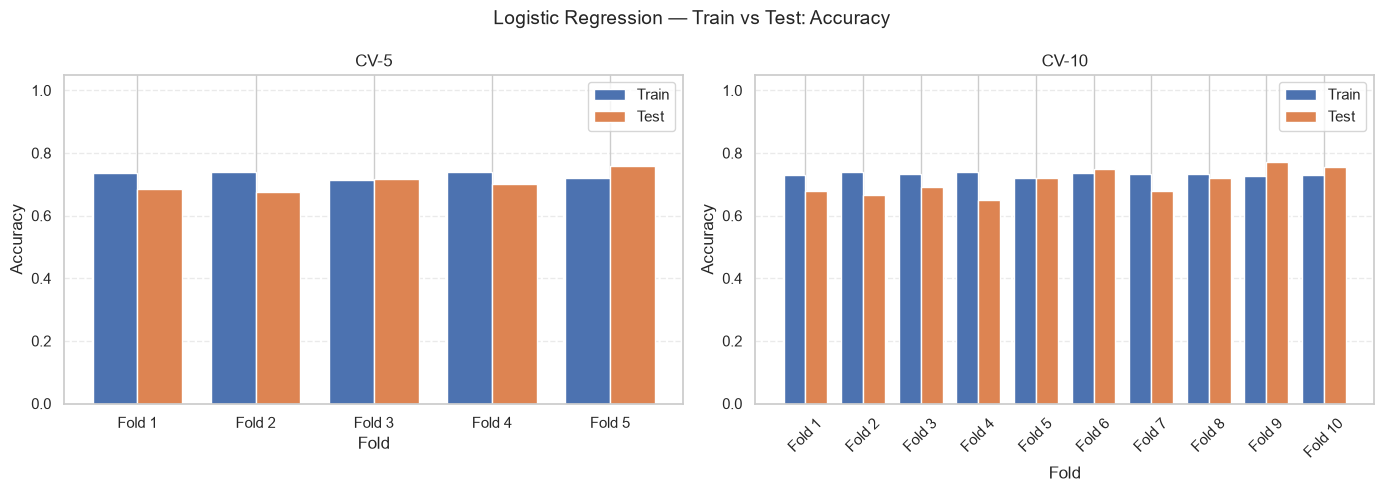

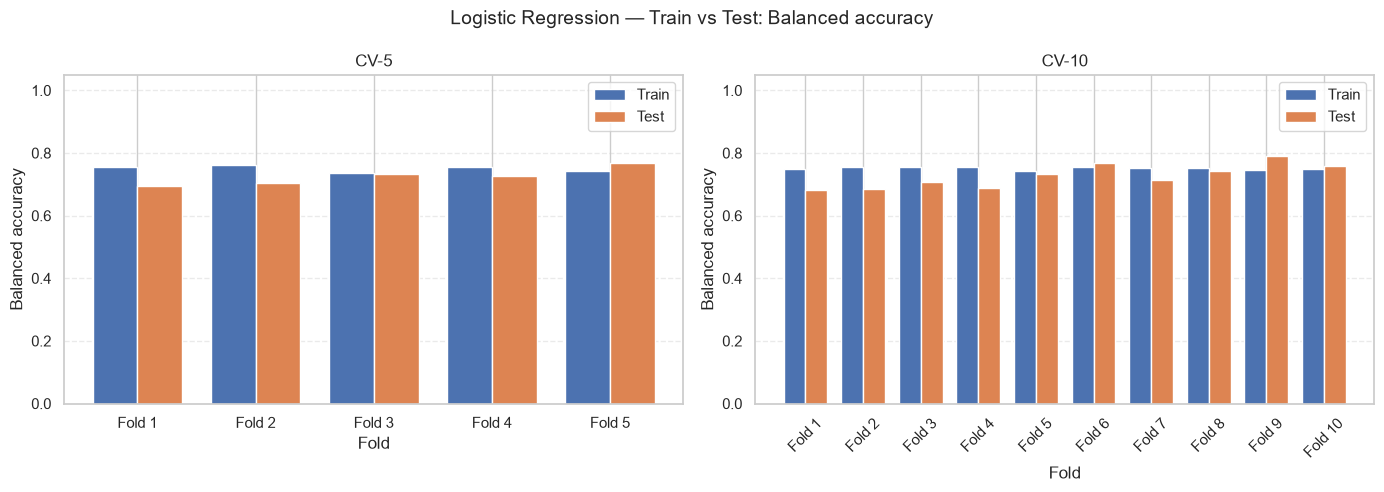

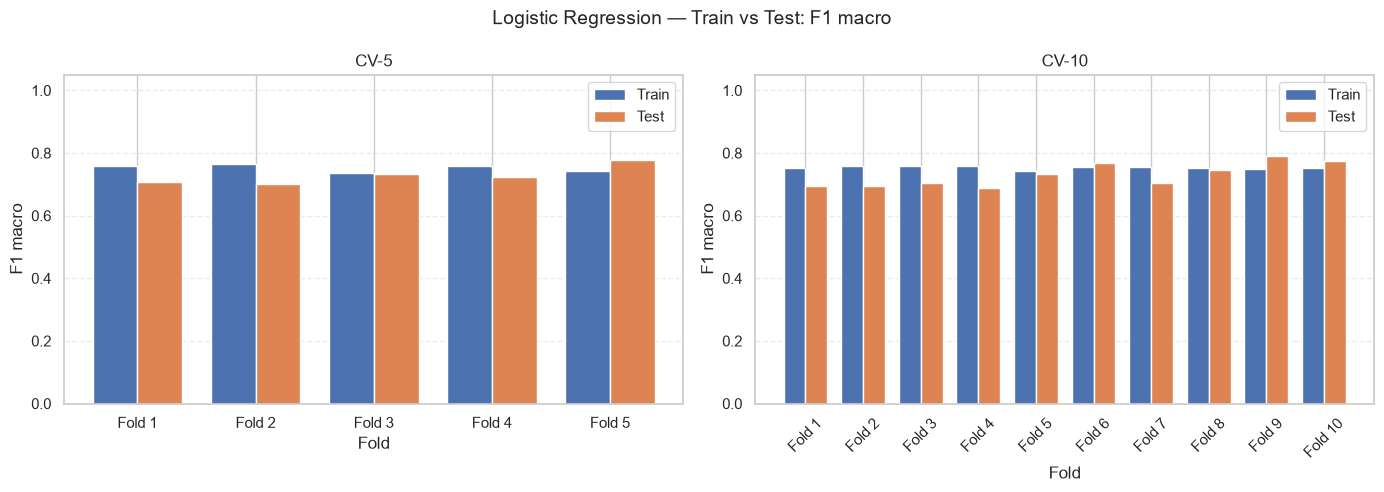

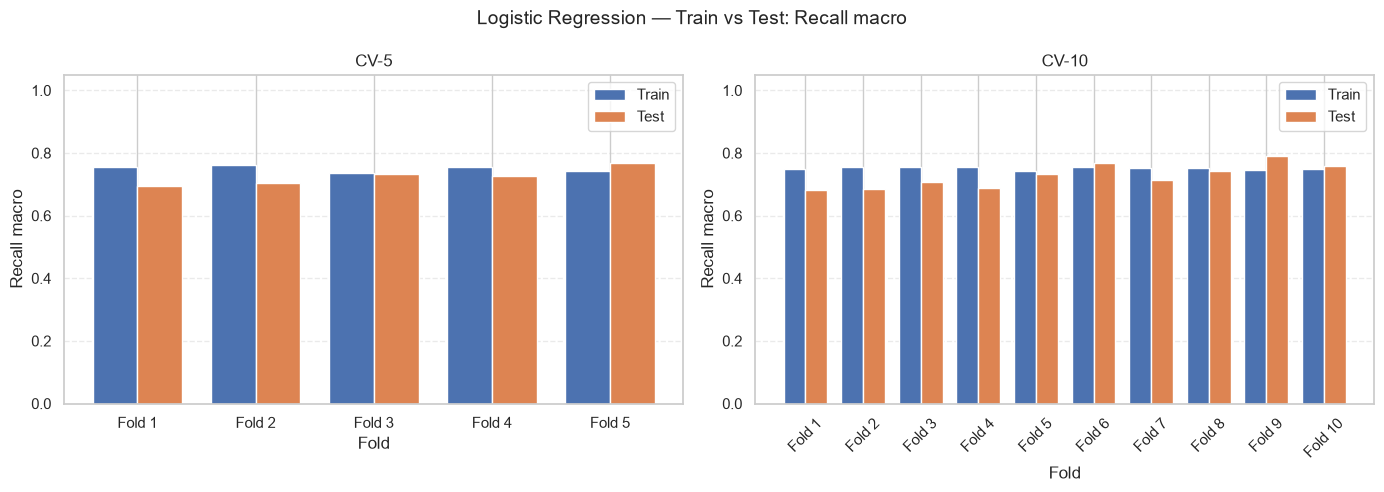

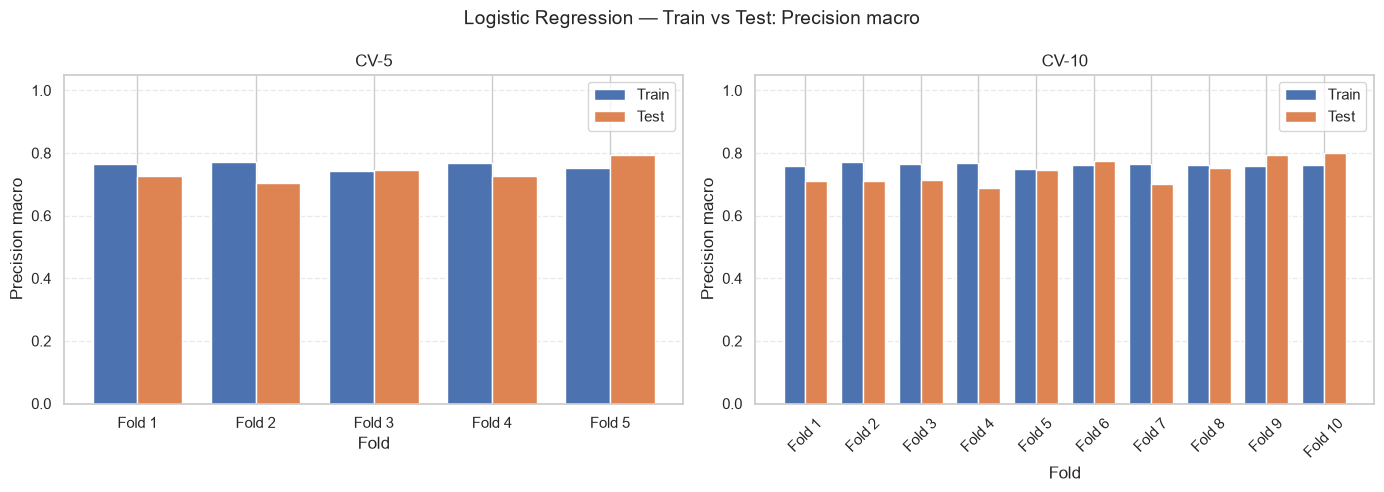

In [103]:
# Gráficos individuais para cada métrica

for metric in metrics:

    metric_name = metric_map[metric]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    width = 0.38

    # -------------------------
    # CV-5
    # -------------------------

    x5 = np.arange(len(lr_cv5_train))

    axes[0].bar(
        x5 - width / 2,
        lr_cv5_train[metric_name],
        width,
        label="Train"
    )

    axes[0].bar(
        x5 + width / 2,
        lr_cv5_test[metric_name],
        width,
        label="Test"
    )

    axes[0].set_title("CV-5")
    axes[0].set_xlabel("Fold")
    axes[0].set_ylabel(metric_name)
    axes[0].set_xticks(x5)
    axes[0].set_xticklabels(lr_cv5_train.index)
    axes[0].set_ylim(0, 1.05)
    axes[0].legend()
    axes[0].grid(axis="y", linestyle="--", alpha=0.4)

    # -------------------------
    # CV-10
    # -------------------------

    x10 = np.arange(len(lr_cv10_train))

    axes[1].bar(
        x10 - width / 2,
        lr_cv10_train[metric_name],
        width,
        label="Train"
    )

    axes[1].bar(
        x10 + width / 2,
        lr_cv10_test[metric_name],
        width,
        label="Test"
    )

    axes[1].set_title("CV-10")
    axes[1].set_xlabel("Fold")
    axes[1].set_ylabel(metric_name)
    axes[1].set_xticks(x10)
    axes[1].set_xticklabels(
        lr_cv10_train.index,
        rotation=45
    )
    axes[1].set_ylim(0, 1.05)
    axes[1].legend()
    axes[1].grid(axis="y", linestyle="--", alpha=0.4)

    # -------------------------
    # Finalização
    # -------------------------

    fig.suptitle(
        f"Logistic Regression — Train vs Test: {metric_name}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

### Interpretação dos gráficos das métricas por fold

Os gráficos comparam as pontuações de treino e teste ao longo dos folds e das métricas. As pontuações de treino são consistentemente superiores às de teste, mas a diferença, por si só, não é suficientemente elevada para indicar sobreajustamento (*overfitting*) severo. As pontuações de teste variam entre folds, o que é consistente com os desvios-padrão apresentados anteriormente.

Na interpretação destes gráficos, devem ser privilegiadas as curvas de teste: as métricas de treino descrevem o ajustamento aos dados utilizados na estimação e não constituem uma estimativa imparcial da capacidade de generalização.

### 6.4. Validação cruzada Leave-One-Out (LOOCV)

In [104]:
lr_loocv_pred, lr_loocv_results = run_loocv(
    models["Logistic Regression"],
    X_classification,
    y
)

# Metrics
lr_loocv_results = pd.DataFrame(
    [lr_loocv_results],
    index=["Logistic Regression — LOOCV"]
)

print("Logistic Regression - LOOCV")
display(lr_loocv_results.round(4))

print("\nClassification Report - LOOCV")

print(classification_report(
    y,
    lr_loocv_pred,
    labels=["N", "HY", "DI"],
    zero_division=0
))

Logistic Regression - LOOCV


,Accuracy,Balanced Accuracy,F1 macro,Precision macro,Recall macro,Time (s)
Logistic Regression — LOOCV,0.7085,0.7275,0.7303,0.7387,0.7275,30.8594



Classification Report - LOOCV
              precision    recall  f1-score   support

           N       0.69      0.78      0.73       998
          HY       0.63      0.52      0.57       669
          DI       0.89      0.89      0.89       333

    accuracy                           0.71      2000
   macro avg       0.74      0.73      0.73      2000
weighted avg       0.71      0.71      0.70      2000



### Interpretação dos resultados

O LOOCV apresenta um Macro F1 agregado de **0.7303**, Accuracy Balanceada / Macro Recall de **0.7275** e Precisão Macro de **0.7387**. Estes valores são próximos dos obtidos em CV-5 e CV-10, apoiando a conclusão de que o desempenho estimado da Regressão Logística é relativamente consistente entre estes esquemas de avaliação.

O relatório por classe revela diferenças no desempenho: a classe **DI** apresenta um F1 mais elevado (**0.89**), enquanto a classe **HY** apresenta um resultado inferior (**0.57**). Assim, o Macro F1 global de aproximadamente 0.73 não deve ser interpretado como um desempenho igualmente forte em todas as classes. O LOOCV é computacionalmente dispendioso neste caso (cerca de **27.3 s**), pois ajusta um modelo por observação.

### 6.5. Bootstrap

In [105]:
lr_bootstrap_results, lr_bootstrap_summary = run_bootstrap(
    models["Logistic Regression"],
    X_classification,
    y,
    bootstrap_samples
)

print("Logistic Regression - Bootstrap Results")
display(lr_bootstrap_summary.round(4))

Logistic Regression - Bootstrap Results


,Mean,Std,Minimum,Maximum,Time (s),Number of iterations
Accuracy,0.7071,0.0132,0.6730,0.7330,18.2031,200
Balanced Accuracy,0.7255,0.0127,0.6832,0.7556,18.2031,200
F1 macro,0.7284,0.0123,0.6891,0.7547,18.2031,200
Precision macro,0.7369,0.0141,0.6961,0.7699,18.2031,200
Recall macro,0.7255,0.0127,0.6832,0.7556,18.2031,200


### Interpretação dos resultados

Nas 200 iterações OOB válidas, a Regressão Logística apresenta um Macro F1 médio de **0.7284** e um desvio-padrão de **0.0123**. O intervalo observado é **0.6891–0.7547**. A Accuracy Balanceada / Macro Recall apresenta uma média de **0.7255** (DP **0.0127**) e a Precisão Macro uma média de **0.7369** (DP **0.0141**).

A média obtida por Bootstrap é próxima das estimativas de CV-5, CV-10 e LOOCV, reforçando a estimativa de desempenho em torno de 0.73. O desvio-padrão mais baixo reflete a variação entre estimativas OOB de Bootstrap; não deve ser diretamente equiparado à variabilidade entre folds de CV, pois as amostras de avaliação são construídas de forma diferente.

### 6.6. Comparação de métodos de reamostragem

In [106]:
def get_cv_test_means(cv_summary):
    return (
        cv_summary
        .xs("Test", level="Dataset")["mean"]
        .rename(index={
            "Balanced accuracy": "Balanced Accuracy"
        })
    )


# Médias das métricas de teste
lr_cv5_means = get_cv_test_means(lr_cv5_summary)
lr_cv10_means = get_cv_test_means(lr_cv10_summary)


# Uniformizar os nomes das métricas
lr_holdout = lr_holdout_results.iloc[0].rename(
    index={"Balanced accuracy": "Balanced Accuracy"}
)

lr_loocv = lr_loocv_results.iloc[0].rename(
    index={"Balanced accuracy": "Balanced Accuracy"}
)

lr_bootstrap = lr_bootstrap_summary["Mean"].rename(
    index={"Balanced accuracy": "Balanced Accuracy"}
)


# Comparação dos métodos de resampling
lr_comparison = pd.concat(
    {
        "Holdout": lr_holdout,
        "CV-5": lr_cv5_means,
        "CV-10": lr_cv10_means,
        "LOOCV": lr_loocv,
        "Bootstrap": lr_bootstrap
    },
    axis=1
)


print("Logistic Regression — Comparison of Resampling Methods")
display(lr_comparison.round(4))


Logistic Regression — Comparison of Resampling Methods


,Holdout,CV-5,CV-10,LOOCV,Bootstrap
Accuracy,0.7300,0.7070,0.7080,0.7085,0.7071
Balanced Accuracy,0.7503,0.7255,0.7267,0.7275,0.7255
F1 macro,0.7502,0.7288,0.7296,0.7303,0.7284
Precision macro,0.7534,0.7384,0.7391,0.7387,0.7369
Recall macro,0.7503,0.7255,0.7267,0.7275,0.7255
Time (s),0.0719,NaN,NaN,30.8594,NaN


### Interpretação: Regressão Logística nos diferentes métodos de reamostragem

O Macro F1 é **0.7502** no Holdout, **0.7288** no CV-5, **0.7296** no CV-10, **0.7303** no LOOCV e **0.7284** no Bootstrap. Com exceção da divisão única de Holdout, todas as estimativas se concentram entre **0.728 e 0.730**.

Esta concordância sugere que o desempenho de generalização do modelo é relativamente estável entre os procedimentos. A pontuação mais elevada do Holdout poderá dever-se à partição específica e não deve ser considerada o desempenho esperado sem experiências repetidas de Holdout. CV-5 e CV-10 são os mais úteis para estimar a variabilidade entre folds.

### 6.7. Variabilidade das métricas de avaliação

In [107]:
# Extract standard deviation from Cross-Validation results
def get_cv_test_std(cv_summary):

    return (
        cv_summary
        .xs("Test", level="Dataset")["std"]
        .rename(index={
            "Balanced accuracy": "Balanced Accuracy"
        })
    )


# Variability of CV-5 and CV-10
lr_cv5_std = get_cv_test_std(lr_cv5_summary)
lr_cv10_std = get_cv_test_std(lr_cv10_summary)


# Standardize metric names
lr_loocv_std = lr_loocv_results.iloc[0].rename(
    index={"Balanced accuracy": "Balanced Accuracy"}
)

lr_bootstrap_std = lr_bootstrap_summary["Std"].rename(
    index={"Balanced accuracy": "Balanced Accuracy"}
)


# Comparison of variability across resampling methods
lr_variability = pd.concat(
    {
        "CV-5": lr_cv5_std,
        "CV-10": lr_cv10_std,
        "LOOCV": lr_loocv_std,
        "Bootstrap": lr_bootstrap_std
    },
    axis=1
)


print("Logistic Regression — Variability")
display(lr_variability.round(4))


Logistic Regression — Variability


,CV-5,CV-10,LOOCV,Bootstrap
Accuracy,0.0325,0.0411,0.7085,0.0132
Balanced Accuracy,0.0294,0.0376,0.7275,0.0127
F1 macro,0.0301,0.0377,0.7303,0.0123
Recall macro,0.0294,0.0376,0.7275,0.0127
Precision macro,0.0335,0.0398,0.7387,0.0141
Time (s),NaN,NaN,30.8594,NaN


### Interpretação: variabilidade da Regressão Logística

Para o Macro F1, o desvio-padrão entre folds é **0.0301** no CV-5 e **0.0377** no CV-10. Assim, nesta execução, o CV-10 apresenta maior variação entre folds, apesar de cada modelo ser treinado com uma amostra maior. Isto pode acontecer porque os folds de validação são menores e a composição das classes tem um efeito mais acentuado na pontuação de cada fold.

O desvio-padrão do Macro F1 entre as iterações de Bootstrap é **0.0123**, inferior aos desvios-padrão entre folds de CV. Esta diferença é expectável, até certo ponto, uma vez que o desvio-padrão do Bootstrap descreve a variação entre estimativas OOB e não entre folds de CV mutuamente exclusivos. LOOCV e Holdout são apresentados como pontuações agregadas únicas; não é possível estimar um desvio-padrão a partir de uma única pontuação. Estas pontuações não devem ser interpretadas como medidas de variabilidade.

## 7. Análise Discriminante Linear (LDA)

### 7.1. Holdout

LDA — Holdout Metrics


,Accuracy,Balanced Accuracy,F1 macro,Precision macro,Recall macro,Time (s)
LDA — Holdout,0.725,0.7385,0.7421,0.7474,0.7385,0.0349


Classification Report
              precision    recall  f1-score   support

          DI       0.86      0.85      0.85        66
          HY       0.66      0.60      0.63       134
           N       0.72      0.77      0.74       200

    accuracy                           0.72       400
   macro avg       0.75      0.74      0.74       400
weighted avg       0.72      0.72      0.72       400



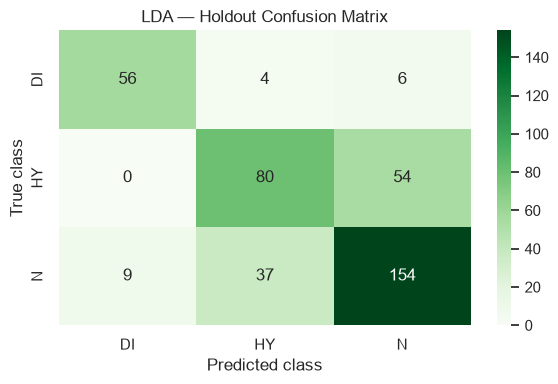

In [108]:
# Execute Holdout
lda_holdout_model, lda_holdout_pred, lda_holdout_results = run_holdout(
    models["LDA"],
    X_train,
    X_test,
    y_train,
    y_test
)

# Metrics
lda_holdout_results = pd.DataFrame(
    [lda_holdout_results],
    index=["LDA — Holdout"]
)

print("LDA — Holdout Metrics")
display(lda_holdout_results.round(4))

# Classification Report
print("Classification Report")

print(classification_report(
    y_test,
    lda_holdout_pred,
    labels=sorted(y.unique()),
    zero_division=0
))

# Confusion Matrix
labels = sorted(y.unique())

cm = confusion_matrix(
    y_test,
    lda_holdout_pred,
    labels=labels
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("LDA — Holdout Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.tight_layout()
plt.show()

### Interpretação dos resultados

A LDA obtém um Macro F1 de **0.7421** no Holdout, Accuracy Balanceada / Macro Recall de **0.7385** e Precisão Macro de **0.7474**. As métricas são relativamente próximas, indicando um resultado agregado equilibrado nesta partição.

Comparativamente à Regressão Logística no mesmo Holdout, a LDA apresenta um Macro F1 ligeiramente inferior (0.7421 vs. 0.7502). Tal como acontece com qualquer Holdout único, o resultado depende da divisão aleatória e deve ser interpretado em conjunto com a validação cruzada e o Bootstrap.

### 7.2. Validação cruzada em 5 partes

In [109]:
lda_cv5_train, lda_cv5_test, lda_cv5_summary = run_cross_validation(
    models["LDA"],
    X_classification,
    y,
    n_splits=5,
    seed=RANDOM_STATE
)

print("LDA — 5-Fold Cross-Validation Results")
print("Train Results:")
display(lda_cv5_train.round(4))

print("Test Results:")
display(lda_cv5_test.round(4))

print("Summary of Test Results:")
display(lda_cv5_summary.round(4))

LDA — 5-Fold Cross-Validation Results
Train Results:


,Accuracy,Balanced accuracy,F1 macro,Recall macro,Precision macro
Fold 1,0.7269,0.7430,0.7491,0.7430,0.7578
Fold 2,0.7356,0.7490,0.7586,0.7490,0.7706
Fold 3,0.7106,0.7311,0.7359,0.7311,0.7426
Fold 4,0.7356,0.7454,0.7554,0.7454,0.7686
Fold 5,0.7188,0.7346,0.7415,0.7346,0.7518


Test Results:


,Accuracy,Balanced accuracy,F1 macro,Recall macro,Precision macro
Fold 1,0.6825,0.6875,0.7018,0.6875,0.7202
Fold 2,0.6700,0.6937,0.6966,0.6937,0.7021
Fold 3,0.7300,0.7422,0.7423,0.7422,0.7456
Fold 4,0.7025,0.7239,0.7290,0.7239,0.7388
Fold 5,0.7575,0.7641,0.7786,0.7641,0.7995


Summary of Test Results:


mean     std     min     max  Time (s)
Dataset Metric                                                     
Train   Accuracy           0.7255  0.0109  0.7106  0.7356    0.2653
        Balanced accuracy  0.7406  0.0075  0.7311  0.7490    0.2653
        F1 macro           0.7481  0.0094  0.7359  0.7586    0.2653
        Recall macro       0.7406  0.0075  0.7311  0.7490    0.2653
        Precision macro    0.7583  0.0117  0.7426  0.7706    0.2653
Test    Accuracy           0.7085  0.0356  0.6700  0.7575    0.2653
        Balanced accuracy  0.7223  0.0323  0.6875  0.7641    0.2653
        F1 macro           0.7297  0.0333  0.6966  0.7786    0.2653
        Recall macro       0.7223  0.0323  0.6875  0.7641    0.2653
        Precision macro    0.7412  0.0367  0.7021  0.7995    0.2653

### Interpretação dos resultados

O Macro F1 médio de teste da LDA é **0.7297** (DP **0.0333**), com Accuracy Balanceada / Macro Recall de **0.7223** e Precisão Macro de **0.7412**.

A média é praticamente idêntica ao Macro F1 do CV-5 da Regressão Logística (**0.7288**), enquanto o desvio-padrão da LDA entre folds é ligeiramente superior (**0.0333** vs. **0.0301**). Isto indica um desempenho médio semelhante, mas uma sensibilidade marginalmente superior às partições no caso da LDA, nesta experiência.

### 7.3. Validação cruzada em 10 partes

In [110]:
lda_cv10_train, lda_cv10_test, lda_cv10_summary = run_cross_validation(
    models["LDA"],
    X_classification,
    y,
    n_splits=10,
    seed=RANDOM_STATE
)

print("LDA — 10-Fold Cross-Validation Results")
print("Train Results:")
display(lda_cv10_train.round(4))

print("Test Results:")
display(lda_cv10_test.round(4))

print("Summary of Test Results:")
display(lda_cv10_summary.round(4))

LDA — 10-Fold Cross-Validation Results
Train Results:


,Accuracy,Balanced accuracy,F1 macro,Recall macro,Precision macro
Fold 1,0.7211,0.7375,0.7448,0.7375,0.7540
Fold 2,0.7350,0.7461,0.7548,0.7461,0.7673
Fold 3,0.7289,0.7460,0.7533,0.7460,0.7624
Fold 4,0.7356,0.7464,0.7552,0.7464,0.7671
Fold 5,0.7150,0.7329,0.7385,0.7329,0.7464
Fold 6,0.7239,0.7410,0.7457,0.7410,0.7521
Fold 7,0.7294,0.7436,0.7523,0.7436,0.7633
Fold 8,0.7311,0.7425,0.7510,0.7425,0.7641
Fold 9,0.7217,0.7382,0.7446,0.7382,0.7539
Fold 10,0.7283,0.7417,0.7496,0.7417,0.7604


Test Results:


,Accuracy,Balanced accuracy,F1 macro,Recall macro,Precision macro
Fold 1,0.685,0.6932,0.7036,0.6932,0.7165
Fold 2,0.680,0.6868,0.7067,0.6868,0.7344
Fold 3,0.690,0.7020,0.7021,0.7020,0.7144
Fold 4,0.645,0.6788,0.6859,0.6788,0.6939
Fold 5,0.720,0.7286,0.7320,0.7286,0.7432
Fold 6,0.740,0.7551,0.7534,0.7551,0.7520
Fold 7,0.695,0.7187,0.7233,0.7187,0.7293
Fold 8,0.730,0.7506,0.7533,0.7506,0.7605
Fold 9,0.755,0.7658,0.7747,0.7658,0.7878
Fold 10,0.750,0.7563,0.7749,0.7563,0.8004


Summary of Test Results:


mean     std     min     max  Time (s)
Dataset Metric                                                     
Train   Accuracy           0.7270  0.0065  0.7150  0.7356    0.2805
        Balanced accuracy  0.7416  0.0044  0.7329  0.7464    0.2805
        F1 macro           0.7490  0.0054  0.7385  0.7552    0.2805
        Recall macro       0.7416  0.0044  0.7329  0.7464    0.2805
        Precision macro    0.7591  0.0071  0.7464  0.7673    0.2805
Test    Accuracy           0.7090  0.0356  0.6450  0.7550    0.2805
        Balanced accuracy  0.7236  0.0323  0.6788  0.7658    0.2805
        F1 macro           0.7310  0.0318  0.6859  0.7749    0.2805
        Recall macro       0.7236  0.0323  0.6788  0.7658    0.2805
        Precision macro    0.7432  0.0331  0.6939  0.8004    0.2805

### Interpretação dos resultados

A LDA obtém um Macro F1 médio de teste de **0.7310** (DP **0.0318**), Accuracy Balanceada / Macro Recall de **0.7236** e Precisão Macro de **0.7432**.

Em comparação com CV-5, o Macro F1 médio aumenta apenas ligeiramente (cerca de 0.0013), enquanto o desvio-padrão diminui de **0.0333 para 0.0318**. A alteração é pequena; por isso, o CV-10 não demonstra uma melhoria substancial do desempenho preditivo, embora a dispersão do Macro F1 entre folds seja marginalmente inferior nesta execução.

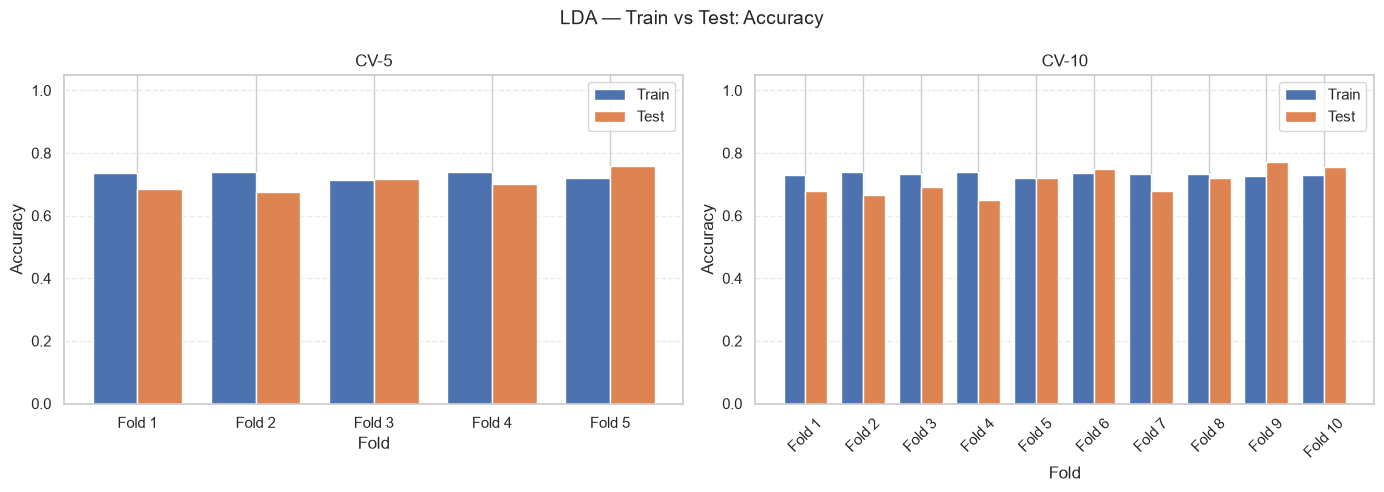

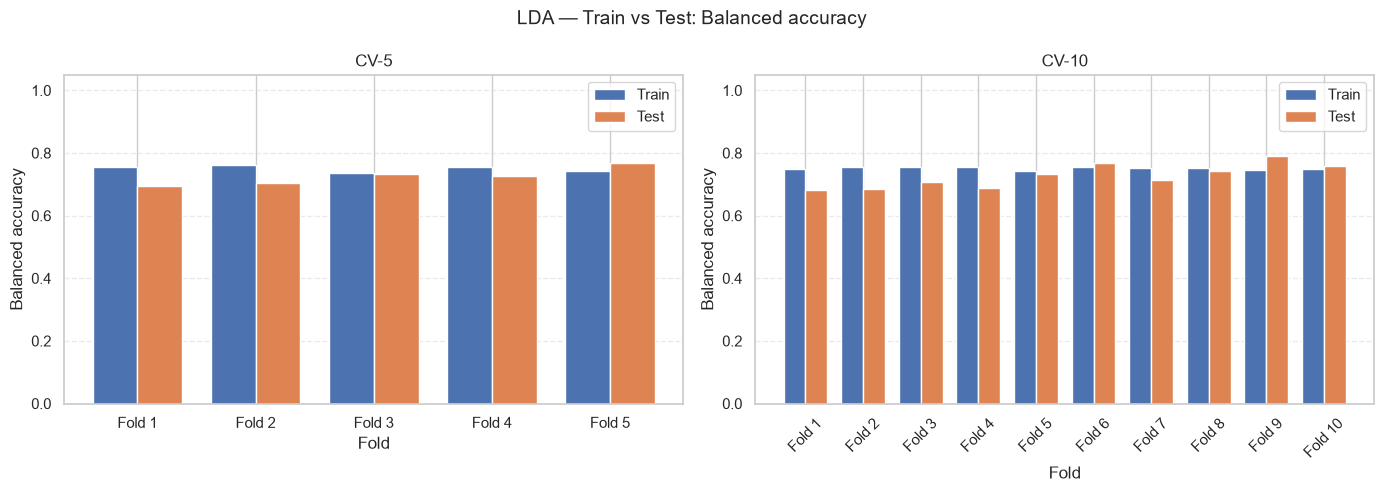

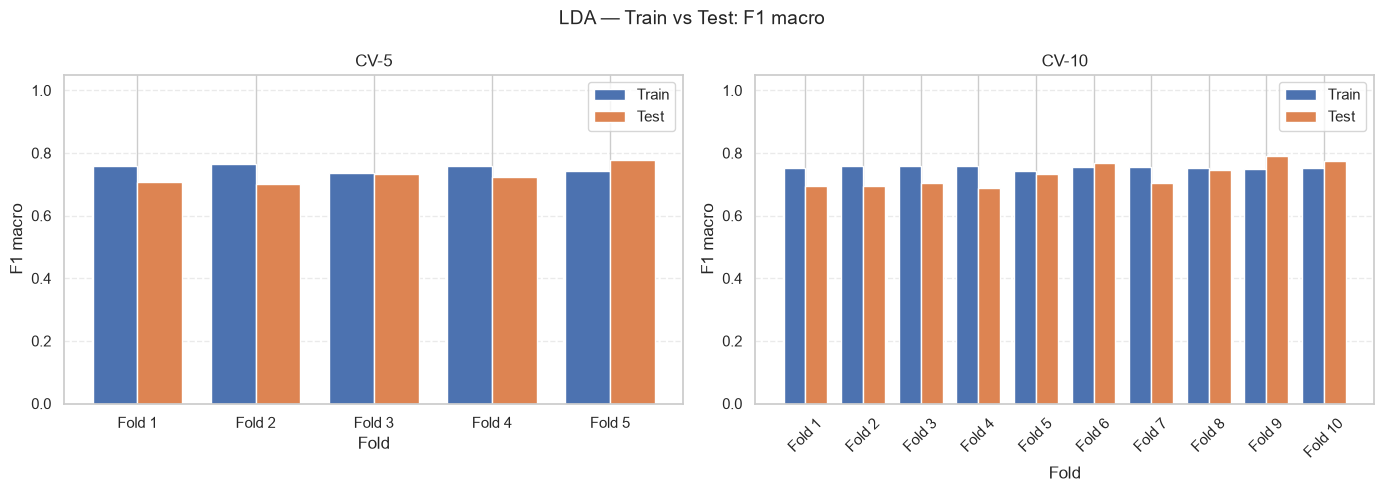

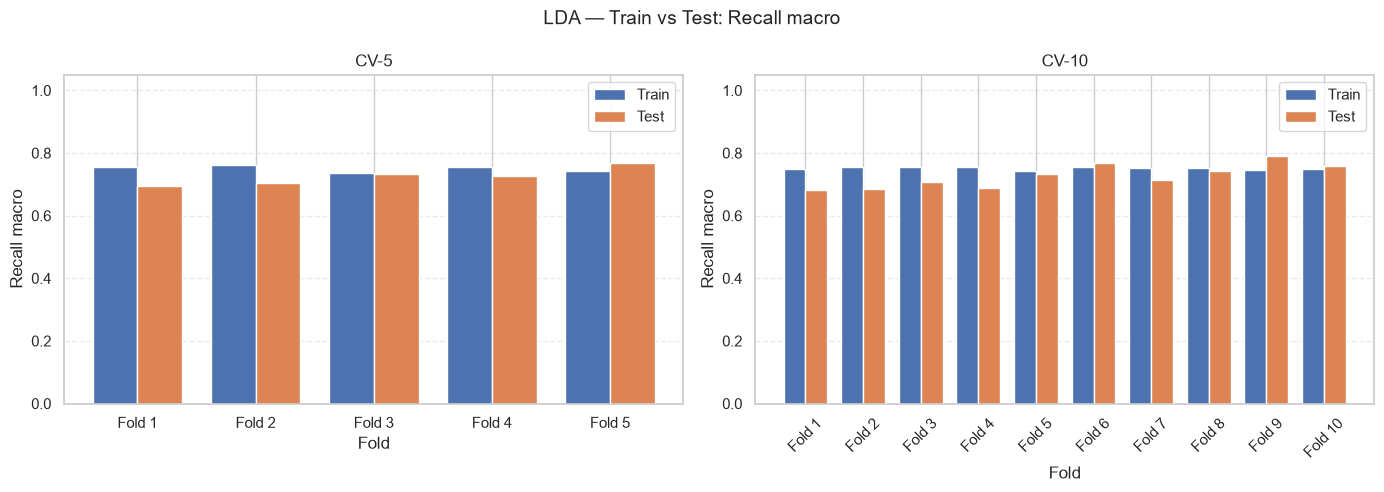

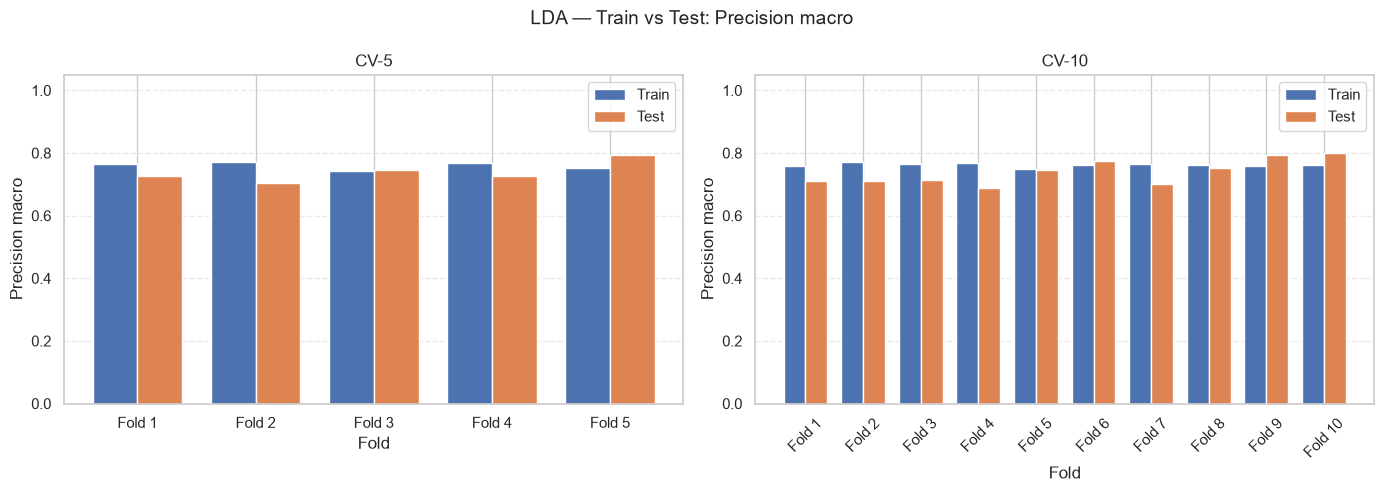

In [111]:
# Gráficos individuais para cada métrica

for metric in metrics:

    metric_name = metric_map[metric]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    width = 0.38

    # -------------------------
    # CV-5
    # -------------------------

    x5 = np.arange(len(lr_cv5_train))

    axes[0].bar(
        x5 - width / 2,
        lr_cv5_train[metric_name],
        width,
        label="Train"
    )

    axes[0].bar(
        x5 + width / 2,
        lr_cv5_test[metric_name],
        width,
        label="Test"
    )

    axes[0].set_title("CV-5")
    axes[0].set_xlabel("Fold")
    axes[0].set_ylabel(metric_name)
    axes[0].set_xticks(x5)
    axes[0].set_xticklabels(lr_cv5_train.index)
    axes[0].set_ylim(0, 1.05)
    axes[0].legend()
    axes[0].grid(axis="y", linestyle="--", alpha=0.4)

    # -------------------------
    # CV-10
    # -------------------------

    x10 = np.arange(len(lr_cv10_train))

    axes[1].bar(
        x10 - width / 2,
        lr_cv10_train[metric_name],
        width,
        label="Train"
    )

    axes[1].bar(
        x10 + width / 2,
        lr_cv10_test[metric_name],
        width,
        label="Test"
    )

    axes[1].set_title("CV-10")
    axes[1].set_xlabel("Fold")
    axes[1].set_ylabel(metric_name)
    axes[1].set_xticks(x10)
    axes[1].set_xticklabels(
        lr_cv10_train.index,
        rotation=45
    )
    axes[1].set_ylim(0, 1.05)
    axes[1].legend()
    axes[1].grid(axis="y", linestyle="--", alpha=0.4)

    # -------------------------
    # Finalização
    # -------------------------

    fig.suptitle(
        f"LDA — Train vs Test: {metric_name}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

### Interpretação dos gráficos das métricas por fold

As pontuações de treino são superiores às pontuações correspondentes de teste, revelando o otimismo esperado quando o modelo é avaliado nos próprios dados de treino. As pontuações de teste variam entre folds, mas o padrão global é comparável ao da Regressão Logística.

As curvas de teste e os resumos por fold devem orientar as conclusões sobre a generalização. As diferenças entre treino e teste, por si só, não são suficientes para diagnosticar sobreajustamento; é necessário considerar a magnitude e a consistência dessas diferenças, juntamente com a variabilidade das pontuações de teste.

### 7.4. Validação cruzada Leave-One-Out (LOOCV)

In [112]:
lda_loocv_pred, lda_loocv_results = run_loocv(
    models["LDA"],
    X_classification,
    y
)

# Metrics
lda_loocv_results = pd.DataFrame(
    [lda_loocv_results],
    index=["LDA — LOOCV"]
)

print("LDA - LOOCV")
display(lda_loocv_results.round(4))

print("\nClassification Report - LOOCV")

print(classification_report(
    y,
    lda_loocv_pred,
    labels=["N", "HY", "DI"],
    zero_division=0
))

LDA - LOOCV


,Accuracy,Balanced Accuracy,F1 macro,Precision macro,Recall macro,Time (s)
LDA — LOOCV,0.7055,0.7207,0.7281,0.7386,0.7207,15.8045



Classification Report - LOOCV
              precision    recall  f1-score   support

           N       0.70      0.76      0.73       998
          HY       0.62      0.55      0.58       669
          DI       0.90      0.85      0.88       333

    accuracy                           0.71      2000
   macro avg       0.74      0.72      0.73      2000
weighted avg       0.70      0.71      0.70      2000



### Interpretação dos resultados

O LOOCV da LDA produz um Macro F1 de **0.7281**, Accuracy Balanceada / Macro Recall de **0.7207** e Precisão Macro de **0.7386**. O resultado é próximo do LOOCV da Regressão Logística (Macro F1 **0.7303**), que apresenta uma vantagem de aproximadamente **0.0022**.

O relatório por classe volta a revelar um desempenho desigual: a classe DI é classificada comparativamente bem (F1 **0.88**), enquanto HY continua a ser a classe mais difícil (F1 **0.58**). O LOOCV demora cerca de **21.1 s**, menos do que os aproximadamente **27.3 s** da Regressão Logística nesta execução.

### 7.5. Bootstrap

In [113]:
lda_bootstrap_results, lda_bootstrap_summary = run_bootstrap(
    models["LDA"],
    X_classification,
    y,
    bootstrap_samples
)

print("LDA - Bootstrap Results")
display(lda_bootstrap_summary.round(4))

LDA - Bootstrap Results


,Mean,Std,Minimum,Maximum,Time (s),Number of iterations
Accuracy,0.7035,0.0138,0.6649,0.7368,13.1828,200
Balanced Accuracy,0.7163,0.0136,0.6730,0.7510,13.1828,200
F1 macro,0.7245,0.0127,0.6818,0.7566,13.1828,200
Precision macro,0.7371,0.0145,0.6931,0.7740,13.1828,200
Recall macro,0.7163,0.0136,0.6730,0.7510,13.1828,200


### Interpretação dos resultados

Nas 200 iterações OOB válidas, a LDA apresenta um Macro F1 médio de **0.7245**, desvio-padrão **0.0127** e intervalo **0.6818–0.7566**. A Accuracy Balanceada / Macro Recall média é **0.7163** (DP **0.0136**) e a Precisão Macro média é **0.7371** (DP **0.0145**).

A média é ligeiramente inferior às estimativas da LDA em CV-5, CV-10 e LOOCV. A dispersão do Bootstrap é inferior à dispersão entre folds de CV, mas estes valores descrevem distribuições de reamostragem diferentes e não devem ser comparados como se fossem calculados a partir de amostras idênticas.

### 7.6. Comparação de métodos de reamostragem

In [114]:
def get_cv_test_means(cv_summary):
    return (
        cv_summary
        .xs("Test", level="Dataset")["mean"]
        .rename(index={
            "Balanced accuracy": "Balanced Accuracy"
        })
    )


# Médias das métricas de teste
lda_cv5_means = get_cv_test_means(lda_cv5_summary)
lda_cv10_means = get_cv_test_means(lda_cv10_summary)


# Uniformizar os nomes das métricas
lda_holdout = lda_holdout_results.iloc[0].rename(
    index={"Balanced accuracy": "Balanced Accuracy"}
)

lda_loocv = lda_loocv_results.iloc[0].rename(
    index={"Balanced accuracy": "Balanced Accuracy"}
)

lda_bootstrap = lda_bootstrap_summary["Mean"].rename(
    index={"Balanced accuracy": "Balanced Accuracy"}
)


# Comparação dos métodos de resampling
lda_comparison = pd.concat(
    {
        "Holdout": lda_holdout,
        "CV-5": lda_cv5_means,
        "CV-10": lda_cv10_means,
        "LOOCV": lda_loocv,
        "Bootstrap": lda_bootstrap
    },
    axis=1
)


print("LDA — Comparison of Resampling Methods")
display(lda_comparison.round(4))


LDA — Comparison of Resampling Methods


,Holdout,CV-5,CV-10,LOOCV,Bootstrap
Accuracy,0.7250,0.7085,0.7090,0.7055,0.7035
Balanced Accuracy,0.7385,0.7223,0.7236,0.7207,0.7163
F1 macro,0.7421,0.7297,0.7310,0.7281,0.7245
Precision macro,0.7474,0.7412,0.7432,0.7386,0.7371
Recall macro,0.7385,0.7223,0.7236,0.7207,0.7163
Time (s),0.0349,NaN,NaN,15.8045,NaN


### Interpretação: LDA nos diferentes métodos de reamostragem

O Macro F1 da LDA é **0.7421** no Holdout, **0.7297** no CV-5, **0.7310** no CV-10, **0.7281** no LOOCV e **0.7245** no Bootstrap. As estimativas de CV e LOOCV são próximas (aproximadamente entre **0.728 e 0.731**); o Holdout apresenta um valor superior e o Bootstrap um valor ligeiramente inferior.

Este padrão é, em geral, consistente com o observado na Regressão Logística. Mais uma vez, o Holdout único apresenta um resultado mais otimista do que as estimativas obtidas por reamostragem repetida, demonstrando por que razão a conclusão não deve depender de uma única partição.

### 7.7. Variabilidade das métricas de avaliação

In [115]:
# Extract standard deviation from Cross-Validation results
def get_cv_test_std(cv_summary):

    return (
        cv_summary
        .xs("Test", level="Dataset")["std"]
        .rename(index={
            "Balanced accuracy": "Balanced Accuracy"
        })
    )


# Variability of CV-5 and CV-10
lda_cv5_std = get_cv_test_std(lda_cv5_summary)
lda_cv10_std = get_cv_test_std(lda_cv10_summary)


# Standardize metric names
lda_loocv_std = lda_loocv_results.iloc[0].rename(
    index={"Balanced accuracy": "Balanced Accuracy"}
)

lda_bootstrap_std = lda_bootstrap_summary["Std"].rename(
    index={"Balanced accuracy": "Balanced Accuracy"}
)


# Comparison of variability across resampling methods
lda_variability = pd.concat(
    {
        "CV-5": lda_cv5_std,
        "CV-10": lda_cv10_std,
        "LOOCV": lda_loocv_std,
        "Bootstrap": lda_bootstrap_std
    },
    axis=1
)


print("LDA — Variability")
display(lda_variability.round(4))


LDA — Variability


,CV-5,CV-10,LOOCV,Bootstrap
Accuracy,0.0356,0.0356,0.7055,0.0138
Balanced Accuracy,0.0323,0.0323,0.7207,0.0136
F1 macro,0.0333,0.0318,0.7281,0.0127
Recall macro,0.0323,0.0323,0.7207,0.0136
Precision macro,0.0367,0.0331,0.7386,0.0145
Time (s),NaN,NaN,15.8045,NaN


### Interpretação: variabilidade da LDA

O desvio-padrão do Macro F1 entre folds da LDA é **0.0333** no CV-5 e **0.0318** no CV-10. Nesta experiência, o CV-10 é ligeiramente menos variável do que o CV-5, embora a diferença seja pequena.

O desvio-padrão do Macro F1 no Bootstrap é **0.0127**, próximo do valor da Regressão Logística (**0.0123**). Como referido anteriormente, a variabilidade entre iterações de Bootstrap e a variabilidade entre folds de CV resultam de esquemas de amostragem diferentes. Holdout e LOOCV produzem apenas uma pontuação agregada, pelo que não é possível estimar o respetivo desvio-padrão nesta execução.

## 8. Comparação global entre os modelos

Esta secção compara a Regressão Logística e a LDA com os mesmos métodos de reamostragem e métricas. O **Macro F1 é o principal critério de comparação**, sendo a Accuracy Balanceada / Macro Recall e a Precisão Macro utilizadas para contextualizar os resultados.

Holdout e LOOCV fornecem uma única pontuação agregada nesta implementação. CV-5 e CV-10 apresentam médias das pontuações por fold, enquanto o Bootstrap apresenta médias das iterações OOB válidas. Estas estimativas não são obtidas a partir das mesmas amostras de avaliação; consequentemente, diferenças pequenas devem ser interpretadas como descritivas e não como evidência formal de superioridade estatística.

In [116]:
model_comparison = pd.concat({
    "Logistic Regression": lr_comparison,
    "LDA": lda_comparison
}, names=["Model", "Metric"])

display(model_comparison)

Holdout      CV-5     CV-10  \
Model               Metric                                            
Logistic Regression Accuracy           0.730000  0.707000  0.708000   
                    Balanced Accuracy  0.750343  0.725506  0.726689   
                    F1 macro           0.750169  0.728779  0.729611   
                    Precision macro    0.753398  0.738446  0.739087   
                    Recall macro       0.750343  0.725506  0.726689   
                    Time (s)           0.071944       NaN       NaN   
LDA                 Accuracy           0.725000  0.708500  0.709000   
                    Balanced Accuracy  0.738500  0.722289  0.723594   
                    F1 macro           0.742125  0.729682  0.730995   
                    Precision macro    0.747441  0.741227  0.743249   
                    Recall macro       0.738500  0.722289  0.723594   
                    Time (s)           0.034855       NaN       NaN   

                                           LOOCV  Bootstrap  
Model               Metric                                   
Logistic Regression Accuracy            0.708500   0.707135  
                    Balanced Accuracy   0.727544   0.725532  
                    F1 macro            0.730302   0.728446  
                    Precision macro     0.738666   0.736914  
                    Recall macro        0.727544   0.725532  
                    Time (s)           30.859389        NaN  
LDA                 Accuracy            0.705500   0.703502  
                    Balanced Accuracy   0.720657   0.716262  
                    F1 macro            0.728133   0.724456  
                    Precision macro     0.738570   0.737136  
                    Recall macro        0.720657   0.716262  
                    Time (s)           15.804477        NaN

### Interpretação da comparação global do desempenho

Nos métodos de reamostragem repetida, os dois modelos apresentam resultados muito próximos. A Regressão Logística tem um Macro F1 relativamente superior no **LOOCV** (0.7303 vs. 0.7281) e no **Bootstrap** (0.7284 vs. 0.7245), enquanto a LDA apresenta valores ligeiramente superiores no **CV-5** (0.7297 vs. 0.7288) e no **CV-10** (0.7310 vs. 0.7296). Estas diferenças são pequenas e não permitem identificar um vencedor inequívoco.

O Holdout favorece a Regressão Logística (0.7502 vs. 0.7421), mas corresponde a uma única divisão e deve ter menos peso do que as estimativas repetidas. Globalmente, a Regressão Logística é uma escolha provisória razoável, uma vez que as suas estimativas repetidas são ligeiramente superiores em dois dos três métodos agregados (LOOCV e Bootstrap). Ainda assim, a evidência aponta para **desempenho preditivo semelhante**, e não para uma superioridade clara. A escolha deve também considerar o desempenho por classe e a interpretabilidade.

In [117]:
f1_comparison = pd.DataFrame({
    "Logistic Regression": lr_comparison.loc["F1 macro"],
    "LDA": lda_comparison.loc["F1 macro"]
})

display(f1_comparison)

,Logistic Regression,LDA
Holdout,0.750169,0.742125
CV-5,0.728779,0.729682
CV-10,0.729611,0.730995
LOOCV,0.730302,0.728133
Bootstrap,0.728446,0.724456


### Interpretação da comparação de Macro F1

Os valores de Macro F1 confirmam que nenhum dos modelos domina consistentemente. A vantagem da Regressão Logística no LOOCV e no Bootstrap é modesta; as vantagens da LDA no CV-5 e CV-10 também são modestas. Ambos os métodos convergem para aproximadamente **0.73 de Macro F1** nas avaliações repetidas.

Assim, a seleção do modelo não deve basear-se apenas em diferenças muito pequenas nas médias. Também devem ser considerados os resultados por classe, o custo computacional, os pressupostos dos modelos e a interpretabilidade prática. A Regressão Logística é selecionada provisoriamente, mantendo-se a LDA como uma alternativa competitiva.

## 9. Análise da variabilidade das métricas de avaliação e estabilidade dos modelos
Esta secção avalia em que medida o Macro F1-score estimado varia sob diferentes procedimentos de avaliação.

Para o CV-5 e o CV-10, o desvio-padrão e a variância são calculados a partir dos resultados por fold. Para o Bootstrap, são calculados a partir dos resultados OOB em todas as repetições válidas.

O método «holdout» e o LOOCV produzem, cada um, uma pontuação agregada na presente experiência. Por conseguinte, não é possível estimar um desvio-padrão apenas a partir destes resultados isolados.

As estimativas de dispersão não são perfeitamente intercambiáveis, uma vez que os métodos utilizam modelos de avaliação diferentes. Em particular, a variação entre as dobras de CV não é a mesma que a variação entre as amostras de Bootstrap.

In [118]:
stability_metrics = [
    "Accuracy",
    "Balanced Accuracy",
    "F1 macro",
    "Recall macro",
    "Precision macro"
]

stability_comparison = pd.concat(
    {
        "Logistic Regression": lr_variability.loc[stability_metrics],
        "LDA": lda_variability.loc[stability_metrics]
    },
    names=["Model", "Metric"]
)

display(stability_comparison.round(4))

CV-5   CV-10   LOOCV  Bootstrap
Model               Metric                                              
Logistic Regression Accuracy           0.0325  0.0411  0.7085     0.0132
                    Balanced Accuracy  0.0294  0.0376  0.7275     0.0127
                    F1 macro           0.0301  0.0377  0.7303     0.0123
                    Recall macro       0.0294  0.0376  0.7275     0.0127
                    Precision macro    0.0335  0.0398  0.7387     0.0141
LDA                 Accuracy           0.0356  0.0356  0.7055     0.0138
                    Balanced Accuracy  0.0323  0.0323  0.7207     0.0136
                    F1 macro           0.0333  0.0318  0.7281     0.0127
                    Recall macro       0.0323  0.0323  0.7207     0.0136
                    Precision macro    0.0367  0.0331  0.7386     0.0145

### Interpretação da variabilidade global e estabilidade

Os desvios-padrão do Macro F1 entre folds de CV são semelhantes: Regressão Logística **0.0301 (CV-5)** e **0.0377 (CV-10)**; LDA **0.0333 (CV-5)** e **0.0318 (CV-10)**. Nenhum dos modelos é uniformemente mais estável para ambos os valores de k: a Regressão Logística apresenta menor desvio-padrão no CV-5, enquanto a LDA apresenta menor desvio-padrão no CV-10.

O desvio-padrão do Macro F1 no Bootstrap é praticamente igual (**0.0123** para a Regressão Logística e **0.0127** para a LDA), sugerindo estabilidade semelhante entre iterações neste esquema de Bootstrap. Estes resultados não permitem uma comparação direta com os desvios-padrão de Holdout ou LOOCV, que produzem apenas uma estimativa agregada nesta implementação.

Em síntese, o método de reamostragem afeta a variabilidade observada: a CV capta a sensibilidade à partição dos folds; o Bootstrap capta a variação entre conjuntos de treino reamostrados e respetivas observações OOB. Aumentar k não reduz necessariamente o desvio-padrão das métricas, porque os folds de validação ficam menores. As diferenças observadas são moderadas e os dois classificadores apresentam uma estabilidade global semelhante.

In [119]:
execution_times = pd.DataFrame({
    "Logistic Regression": {
        "Holdout": lr_holdout_results["Time (s)"],
        "CV 5": lr_cv5_summary["Time (s)"].iloc[0],
        "CV 10": lr_cv10_summary["Time (s)"].iloc[0],
        "LOOCV": lr_loocv_results["Time (s)"],
        "Bootstrap": lr_bootstrap_summary["Time (s)"].iloc[0]
    },

    "LDA": {
        "Holdout": lda_holdout_results["Time (s)"],
        "CV 5": lda_cv5_summary["Time (s)"].iloc[0],
        "CV 10": lda_cv10_summary["Time (s)"].iloc[0],
        "LOOCV": lda_loocv_results["Time (s)"],
        "Bootstrap": lda_bootstrap_summary["Time (s)"].iloc[0]
    }
})

display(execution_times)

,Logistic Regression,LDA
Holdout,Logistic Regression — Holdout 0.071944 Name...,"LDA — Holdout 0.034855 Name: Time (s), dtyp..."
CV 5,15.447779,0.265263
CV 10,10.499255,0.280483
LOOCV,Logistic Regression — LOOCV 30.859389 Name:...,"LDA — LOOCV 15.804477 Name: Time (s), dtype..."
Bootstrap,18.203053,13.182793


### Interpretação do custo computacional

A comparação dos tempos de execução evidencia um compromisso entre a precisão da estimativa e o custo computacional. O Holdout é o método mais rápido para ambos os modelos (aproximadamente **0.06 s** para a Regressão Logística e **0.07 s** para a LDA). O CV-5 é mais rápido do que o CV-10, pois exige menos ajustamentos; o CV-10 utiliza folds de treino ligeiramente maiores, mas tem um custo superior. O LOOCV é consideravelmente mais dispendioso (**cerca de 27.3 s para a Regressão Logística e 18.2 s para a LDA**), uma vez que ajusta um modelo por observação. O Bootstrap (200 iterações) também exige ajustamentos repetidos (**cerca de 16.1 s e 13.9 s**, respetivamente).

Para este conjunto de dados, CV-5 ou CV-10 oferece um equilíbrio prático entre estimativa de desempenho, análise da variabilidade e custo computacional. O LOOCV acrescenta um custo considerável sem alterar a conclusão de que ambos os modelos apresentam um Macro F1 próximo de 0.73.

## 10. Análise do desempenho por classe

### 10.1. Distribuição das classes

A avaliação global dos classificadores permite comparar o desempenho geral da Logistic Regression e da Linear Discriminant Analysis (LDA). No entanto, como o problema envolve três classes (N, HY e DI), é importante analisar também o desempenho individual de cada uma.

Esta análise é particularmente relevante devido à distribuição desigual das observações pelas classes, uma vez que um bom desempenho global não garante que todas as classes sejam identificadas com a mesma eficácia.

Assim, começa-se por analisar a distribuição das classes e, posteriormente, avaliam-se as métricas Precision, Recall e F1-score para cada classe, considerando os resultados obtidos no Holdout e no LOOCV.

In [120]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report

CLASS_LABELS = ["N", "HY", "DI"]

# Distribuição das classes
class_distribution = (
    y.value_counts()
    .reindex(CLASS_LABELS, fill_value=0)
    .rename("Number of observations")
    .to_frame()
)

class_distribution["Proportion (%)"] = (
    class_distribution["Number of observations"]
    / len(y) * 100
)

display(class_distribution.round(2))

,Number of observations,Proportion (%)
target_class,,
N,998,49.90
HY,669,33.45
DI,333,16.65


### 10.2. Métricas por classe no Holdout

A primeira análise considera os resultados obtidos através da divisão Holdout, permitindo avaliar o desempenho dos modelos num conjunto de teste independente dos dados utilizados no treino.

Para cada classe, são consideradas três métricas:

- **Precision:** representa a proporção de previsões corretas entre todas as observações classificadas pelo modelo como pertencentes a determinada classe.
- **Recall:** representa a proporção de observações de determinada classe que foram corretamente identificadas pelo modelo.
- **F1-score:** corresponde à média harmónica entre Precision e Recall, permitindo avaliar o equilíbrio entre ambas.

Estas métricas permitem identificar não só as classes mais facilmente classificadas, mas também aquelas em que os modelos apresentam maiores dificuldades.

In [121]:
def get_classification_metrics(y_true, y_pred, labels):

    report = classification_report(
        y_true,
        y_pred,
        labels=labels,
        output_dict=True,
        zero_division=0
    )

    results = pd.DataFrame({
        "Precision": [
            report[label]["precision"] for label in labels
        ],
        "Recall": [
            report[label]["recall"] for label in labels
        ],
        "F1-score": [
            report[label]["f1-score"] for label in labels
        ]
    }, index=labels)

    results.index.name = "Class"

    return results


# Logistic Regression
lr_holdout_class_metrics = get_classification_metrics(
    y_test,
    lr_holdout_pred,
    CLASS_LABELS
)

# LDA
lda_holdout_class_metrics = get_classification_metrics(
    y_test,
    lda_holdout_pred,
    CLASS_LABELS
)


# Tabela comparativa
holdout_class_comparison = pd.concat(
    {
        "Logistic Regression": lr_holdout_class_metrics,
        "LDA": lda_holdout_class_metrics
    },
    names=["Model", "Class"]
)

display(holdout_class_comparison.round(4))

Precision  Recall  F1-score
Model               Class                             
Logistic Regression N         0.7143  0.7750    0.7434
                    HY        0.6783  0.5821    0.6265
                    DI        0.8676  0.8939    0.8806
LDA                 N         0.7196  0.7700    0.7440
                    HY        0.6612  0.5970    0.6275
                    DI        0.8615  0.8485    0.8550

### Interpretação do desempenho por classe

A análise dos resultados por classe permite identificar diferenças no comportamento dos dois classificadores.

Relativamente à classe DI, a Logistic Regression apresenta o melhor desempenho, com um F1-score de 0.88, comparativamente a 0.85 obtido pela LDA. Ambos os modelos demonstram uma boa capacidade de identificação desta classe.

A classe HY apresenta maiores dificuldades de classificação, com um F1-score de 0.63 em ambos os modelos. Apesar de apresentarem o mesmo F1-score, a LDA obtém um Recall ligeiramente superior (0.60 contra 0.58), indicando uma maior capacidade de identificar corretamente as observações pertencentes a esta classe.

Na classe N, ambos os classificadores apresentam um F1-score de 0.74. Contudo, a Logistic Regression apresenta um Recall ligeiramente superior (0.78 contra 0.77).

De forma geral, a classe DI apresenta os melhores resultados, enquanto a classe HY representa o maior desafio para ambos os classificadores. Esta diferença demonstra que o desempenho dos modelos não é uniforme entre as classes.

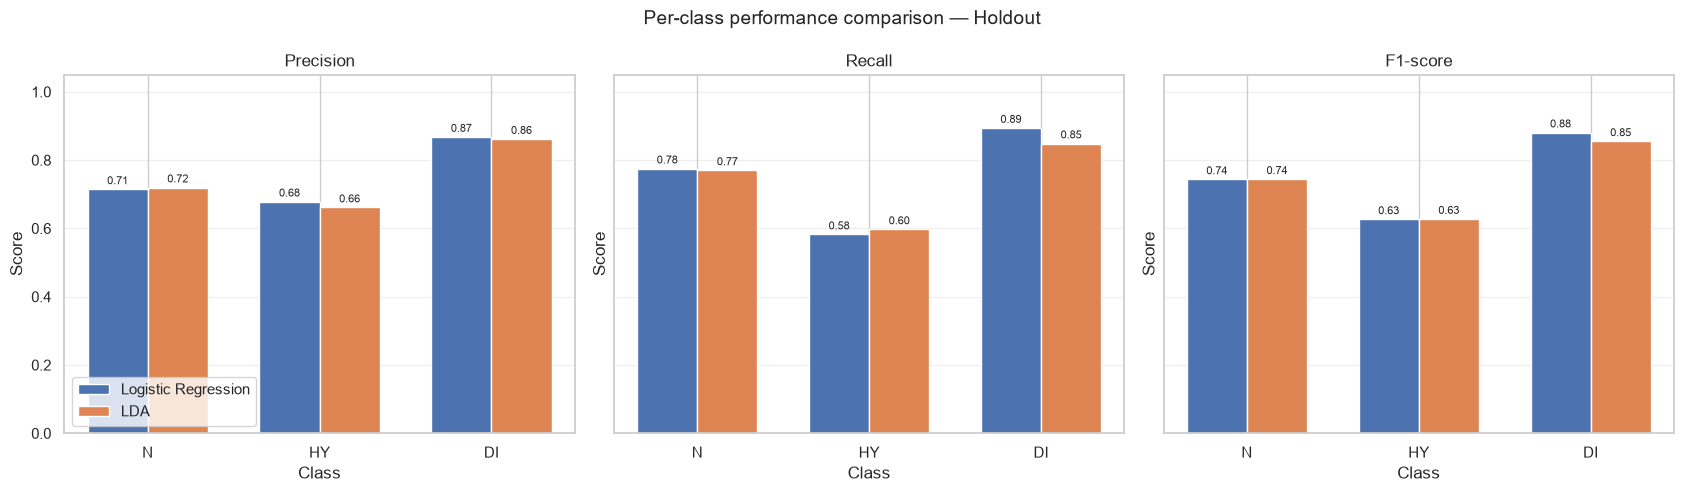

In [122]:
metrics_to_plot = ["Precision", "Recall", "F1-score"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    sharey=True
)

x = np.arange(len(CLASS_LABELS))
width = 0.35

for ax, metric in zip(axes, metrics_to_plot):

    lr_values = lr_holdout_class_metrics[metric]
    lda_values = lda_holdout_class_metrics[metric]

    ax.bar(
        x - width / 2,
        lr_values,
        width,
        label="Logistic Regression"
    )

    ax.bar(
        x + width / 2,
        lda_values,
        width,
        label="LDA"
    )

    ax.set_title(metric)
    ax.set_xticks(x)
    ax.set_xticklabels(CLASS_LABELS)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("Class")
    ax.set_ylabel("Score")
    ax.grid(axis="y", alpha=0.3)

    for i, value in enumerate(lr_values):
        ax.text(
            i - width / 2,
            value + 0.015,
            f"{value:.2f}",
            ha="center",
            fontsize=8
        )

    for i, value in enumerate(lda_values):
        ax.text(
            i + width / 2,
            value + 0.015,
            f"{value:.2f}",
            ha="center",
            fontsize=8
        )

axes[0].legend(loc="lower left")

fig.suptitle(
    "Per-class performance comparison — Holdout",
    fontsize=14
)

plt.tight_layout()
plt.show()

### 10.3. Métricas por classe no LOOCV

Para complementar a análise anterior, considera-se também o desempenho individual por classe no LOOCV (Leave-One-Out Cross-Validation).

Ao contrário do Holdout, no LOOCV cada observação é utilizada uma vez como conjunto de validação, sendo o modelo treinado com todas as restantes observações.

Desta forma, obtêm-se previsões para a totalidade do conjunto de dados, permitindo calcular Precision, Recall e F1-score para cada classe.

Esta análise permite verificar se as dificuldades de classificação identificadas no Holdout se mantêm quando se considera um procedimento de validação diferente.

In [123]:
# Logistic Regression — LOOCV
lr_loocv_class_metrics = get_classification_metrics(
    y,
    lr_loocv_pred,
    CLASS_LABELS
)

# LDA — LOOCV
lda_loocv_class_metrics = get_classification_metrics(
    y,
    lda_loocv_pred,
    CLASS_LABELS
)


# Tabela comparativa
loocv_class_comparison = pd.concat(
    {
        "Logistic Regression": lr_loocv_class_metrics,
        "LDA": lda_loocv_class_metrics
    },
    names=["Model", "Class"]
)

display(loocv_class_comparison.round(4))

Precision  Recall  F1-score
Model               Class                             
Logistic Regression N         0.6907  0.7766    0.7311
                    HY        0.6337  0.5172    0.5695
                    DI        0.8916  0.8889    0.8902
LDA                 N         0.6965  0.7635    0.7285
                    HY        0.6176  0.5456    0.5794
                    DI        0.9016  0.8529    0.8765

### Interpretação do desempenho por classe
Os resultados obtidos através do LOOCV permitem complementar as conclusões anteriores.

Verifica-se que o padrão identificado no Holdout se mantém: a classe DI apresenta os melhores resultados, enquanto a classe HY continua a apresentar o menor F1-score.

Na Logistic Regression, os F1-scores são aproximadamente 0.73 para N, 0.57 para HY e 0.89 para DI. Na LDA, os valores são aproximadamente 0.73 para N, 0.58 para HY e 0.88 para DI.

A proximidade entre os resultados dos dois procedimentos de avaliação sugere que as dificuldades de classificação da classe HY não estão exclusivamente associadas à divisão utilizada no Holdout.

Assim, apesar de ambos os classificadores apresentarem um desempenho global semelhante, existem diferenças na capacidade de identificação de cada classe. A Logistic Regression apresenta uma ligeira vantagem na classe DI, enquanto a LDA apresenta uma pequena vantagem na classe HY.

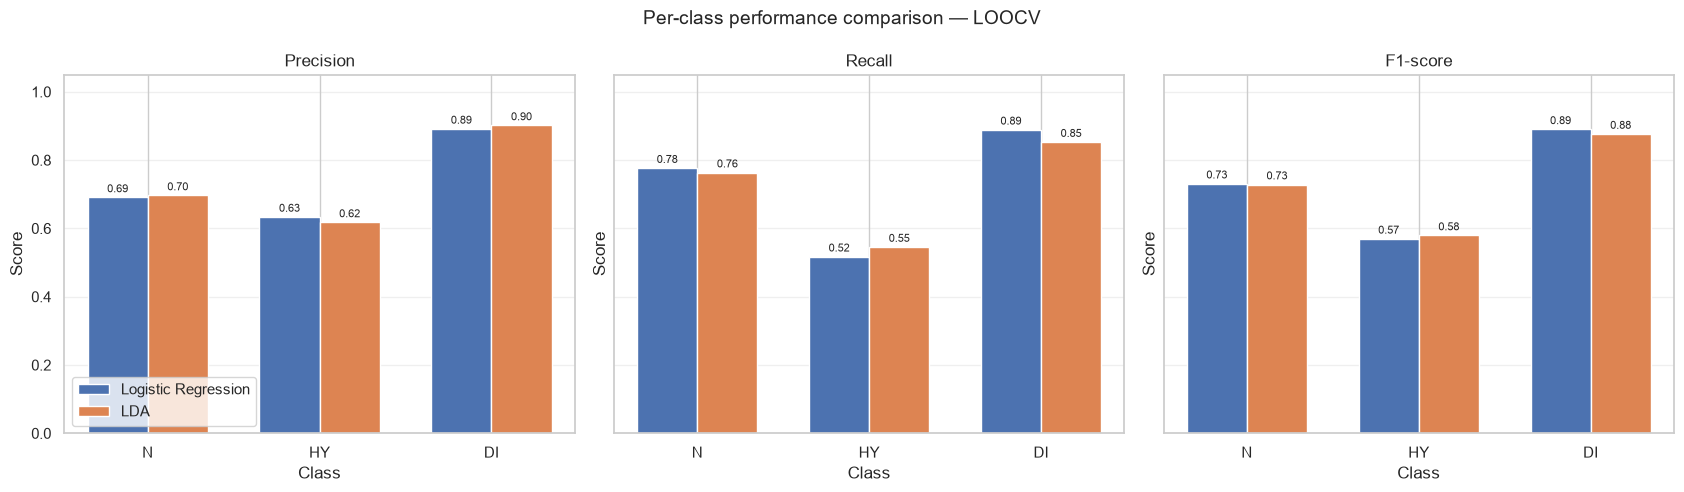

In [124]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    sharey=True
)

x = np.arange(len(CLASS_LABELS))
width = 0.35

for ax, metric in zip(axes, metrics_to_plot):

    lr_values = lr_loocv_class_metrics[metric]
    lda_values = lda_loocv_class_metrics[metric]

    ax.bar(
        x - width / 2,
        lr_values,
        width,
        label="Logistic Regression"
    )

    ax.bar(
        x + width / 2,
        lda_values,
        width,
        label="LDA"
    )

    ax.set_title(metric)
    ax.set_xticks(x)
    ax.set_xticklabels(CLASS_LABELS)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("Class")
    ax.set_ylabel("Score")
    ax.grid(axis="y", alpha=0.3)

    for i, value in enumerate(lr_values):
        ax.text(
            i - width / 2,
            value + 0.015,
            f"{value:.2f}",
            ha="center",
            fontsize=8
        )

    for i, value in enumerate(lda_values):
        ax.text(
            i + width / 2,
            value + 0.015,
            f"{value:.2f}",
            ha="center",
            fontsize=8
        )

axes[0].legend(loc="lower left")

fig.suptitle(
    "Per-class performance comparison — LOOCV",
    fontsize=14
)

plt.tight_layout()
plt.show()

### 10.4. Conclusões sobre o desempenho por classe
A análise individual das classes complementa a comparação global dos classificadores, permitindo compreender melhor o comportamento da Logistic Regression e da LDA.

Os resultados mostram que:

- **DI:** é a classe com melhor desempenho em ambos os modelos, apresentando valores elevados de F1-score.
- **HY:** é a classe mais difícil de identificar, apresentando os valores mais baixos de Recall e F1-score.
- **N:** apresenta resultados intermédios, com desempenhos semelhantes entre os dois classificadores.

As conclusões são consistentes entre Holdout e LOOCV, sugerindo que as dificuldades associadas à classificação da classe HY são relativamente persistentes.

Embora a Logistic Regression apresente algumas vantagens na identificação da classe DI, a LDA demonstra resultados ligeiramente superiores na classe HY. Consequentemente, não existe um classificador que apresente uma vantagem uniforme em todas as classes.

Esta análise reforça a importância de considerar métricas como Macro F1 e Balanced Accuracy na seleção do modelo final, em conjunto com as métricas globais e a estabilidade dos resultados obtidos através dos diferentes procedimentos de validação.

## 11. Conclusão - Seleção do modelo final

A seleção do modelo final teve em consideração o desempenho global dos classificadores, a estabilidade dos resultados, a capacidade de identificação individual das classes e os tempos de execução.

Relativamente ao desempenho global, a Logistic Regression apresenta resultados superiores no Holdout, LOOCV e Bootstrap em termos de Macro F1. Embora a LDA obtenha valores ligeiramente superiores no CV-5 e CV-10, as diferenças são reduzidas (0.0009 e 0.0014, respetivamente).

Um dos aspetos mais relevantes é a Balanced Accuracy, na qual a Logistic Regression apresenta resultados superiores em todos os procedimentos de avaliação. Este comportamento é particularmente importante neste problema, uma vez que as três classes apresentam frequências diferentes e é necessário evitar que o desempenho do classificador seja condicionado pela classe maioritária.

No que diz respeito à estabilidade, a Logistic Regression apresenta menor desvio-padrão no CV-5 e Bootstrap, enquanto a LDA demonstra menor variabilidade no CV-10. Assim, não existe uma vantagem uniforme de um classificador em todos os procedimentos, embora a Logistic Regression apresente resultados ligeiramente mais favoráveis no conjunto das avaliações consideradas.

A análise individual das classes reforça esta escolha. A Logistic Regression apresenta melhores resultados na identificação da classe DI, tanto no Holdout como no LOOCV, enquanto a LDA apresenta uma ligeira vantagem na classe HY no LOOCV. A classe HY continua a representar a maior dificuldade para ambos os classificadores, evidenciando uma limitação que deverá ser considerada na avaliação final.

Relativamente aos tempos de execução, a LDA apresenta uma vantagem em três dos cinco procedimentos avaliados. Contudo, as diferenças observadas não são suficientemente relevantes para compensar o desempenho preditivo globalmente mais favorável da Logistic Regression.

**Assim, seleciona-se a Logistic Regression como modelo final**, por apresentar o melhor equilíbrio entre desempenho global, capacidade de identificação das diferentes classes e estabilidade dos resultados. Apesar de a LDA apresentar algumas vantagens pontuais, a Regressão Logística demonstra um comportamento globalmente mais consistente e adequado às características do problema.

Importa, contudo, reconhecer que a classificação da classe HY continua a constituir uma limitação de ambos os modelos, pelo que esta dificuldade deverá ser considerada na interpretação dos resultados e em possíveis melhorias futuras.

---
## 5.  Feature Selection (Ridge e Lasso)

**Objetivo:** O objetivo desta secção é aplicar e comparar dois métodos de regularização linear — **Ridge** e **Lasso** — para a previsão da variável-alvo `target_class` (N, HY, DI), complementando a análise anterior baseada em Regressão Logística e LDA.

A regularização é particularmente útil em contextos com um elevado número de preditores, pois ajuda a prevenir o *overfitting*, reduz a variância dos coeficientes e realiza seleção de variáveis (no caso do Lasso).

Serão avaliados os seguintes aspetos:
1. O impacto dos hiperparâmetros de regularização ($\alpha$ ou $C$) no desempenho dos modelos.
2. A esparsidade dos coeficientes gerados pelo Lasso em comparação com o Ridge.
3. O desempenho preditivo avaliado com métricas robustas para classes desequilibradas (como o *Macro F1-score* e a *Precisão Equilibrada*).

In [125]:
# Dividir o dataset em treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X_classification, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Dimensões do conjunto de Treino: {X_train.shape}")
print(f"Dimensões do conjunto de Teste: {X_test.shape}")

Dimensões do conjunto de Treino: (1600, 42)
Dimensões do conjunto de Teste: (400, 42)


### 5.1. Avaliação do Modelo Ridge

Após a divisão dos dados em conjuntos de treino e teste, procedemos à avaliação do modelo de Regressão Logística com penalização de Ridge. 

Com base em testes empíricos com diferentes valores do hiperparâmetro de regularização inversa ($C \in \{0.01, 0.1, 0.2, 0.3, 0.5\}$), identificou-se que **$C = 0.2$** proporcionou o melhor desempenho geral. Os valores mais baixos de $C$ correspondem a uma regularização mais forte.

In [126]:
evaluation_results = []

# Modelos com todas as features (incluindo o Ridge otimizado com C=0.2)
models_base = {
    "Logistic Regression (Baseline)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(C=1.0, max_iter=5000, random_state=42))
    ]),
    "Ridge (C=0.2)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(C=0.2, l1_ratio=0.0, max_iter=5000, random_state=42))
    ])
}

for name, pipe in models_base.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    # Cálculo das métricas de desempenho no conjunto de teste
    metrics = calculate_metrics(y_test, y_pred)
    metrics["Modelo"] = name
    metrics["N_Features"] = X_classification.shape[1]
    evaluation_results.append(metrics)
    
# Construção do DataFrame final com os resultados de avaliação
df_base_eval = pd.DataFrame(evaluation_results)
display(df_base_eval[["Modelo", "N_Features", "Accuracy", "Balanced Accuracy", "F1 macro"]].round(4))

,Modelo,N_Features,Accuracy,Balanced Accuracy,F1 macro
0,Logistic Regression (Baseline),42,0.73,0.7503,0.7502
1,Ridge (C=0.2),42,0.73,0.7478,0.7490


### 5.2. Seleção de Variáveis com Lasso

De seguida, aplicamos a regularização Lasso utilizando diferentes valores do hiperparâmetro $C$. O objetivo principal desta etapa é avaliar a esparsidade do modelo, identificando e eliminando as variáveis com menor poder preditivo (cujos coeficientes são anulados).

Após testar diferentes valores de regularização inversa ($C \in \{0.01, 0.05, 0.1, 0.2, 0.5\}$), o valor **$C = 0.1$** demonstrou um melhor desempenho geral, permitindo reduzir a dimensionalidade do modelo sem sacrificar a capacidade preditiva.

In [127]:
# Pipeline com Lasso utilizando o melhor hiperparâmetro C=0.1
lasso_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(l1_ratio=1.0, solver='saga', C=0.1, max_iter=5000, random_state=42))
])

# Treinar nos dados de treino
lasso_pipeline.fit(X_train, y_train)

# Extrair coeficientes
lasso_coefs = lasso_pipeline.named_steps["model"].coef_

# Identificar colunas com coeficientes diferentes de zero em pelo menos uma classe
if lasso_coefs.ndim > 1:
    selected_mask = np.any(lasso_coefs != 0, axis=0)
else:
    selected_mask = lasso_coefs != 0

selected_features = X_classification.columns[selected_mask].tolist()

print(f"--- RESULTADO DA SELEÇÃO (LASSO) ---")
print(f"Número total de features originais: {X_classification.shape[1]}")
print(f"Número de features selecionadas: {len(selected_features)}")
print(f"\nLista de variáveis mantidas:\n{selected_features}")

--- RESULTADO DA SELEÇÃO (LASSO) ---
Número total de features originais: 42
Número de features selecionadas: 29

Lista de variáveis mantidas:
['gender', 'bmi_level', 'age', 'age_normalized', 'HbA1c_level', 'cholesterol', 'triglycerides', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'blood_pressure', 'sugar_consumption', 'crp_level', 'homocysteine_level', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'hdl', 'plasma_value', 'age_level_Young', 'age_level_Senior', 'smoking_Never', 'smoking_Current', 'education_level_Primary', 'education_level_Tertiary', 'employment_status_Unemployed', 'employment_status_Retired']


### Visualização da Importância das Variáveis (Lasso)

O gráfico seguinte ilustra a magnitude média dos coeficientes das variáveis mantidas pelo modelo Lasso ($C=0.1$). Permite identificar rapidamente quais os fatores clínicos e demográficos com maior peso na predição.

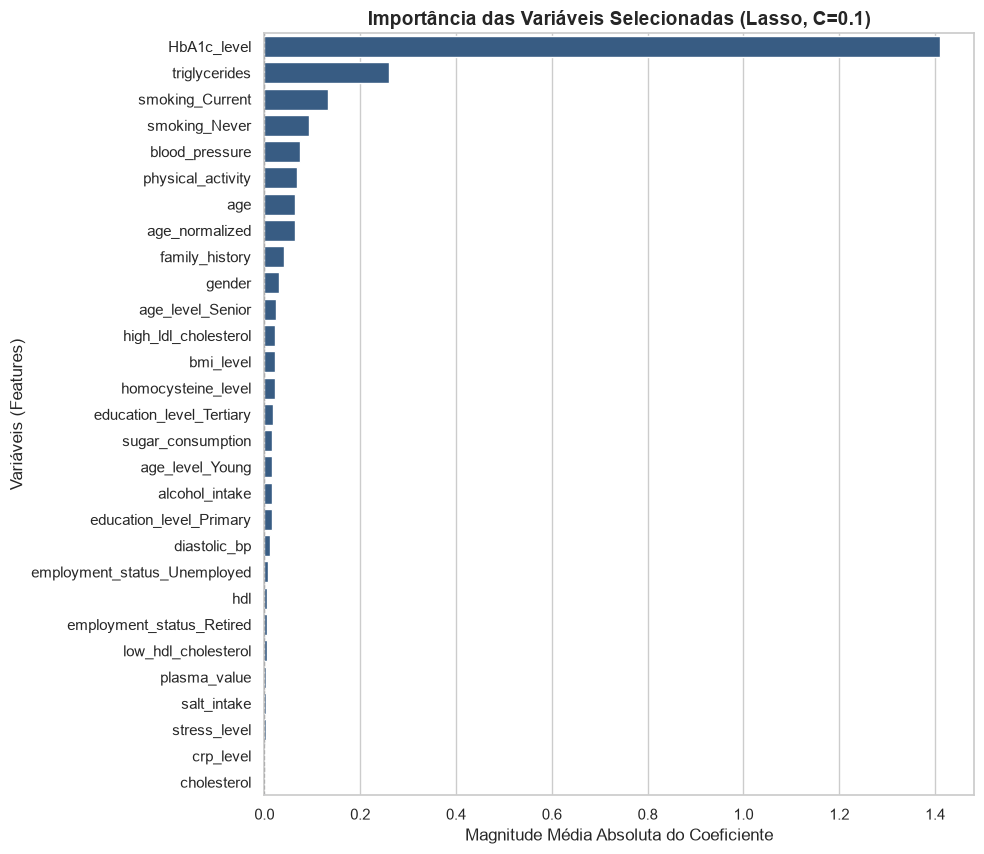

In [128]:
# Extrair coeficientes do modelo Lasso
coefs = lasso_pipeline.named_steps["model"].coef_

# Calcular a média da magnitude absoluta entre as classes
if coefs.ndim > 1:
    mean_abs_coefs = np.mean(np.abs(coefs), axis=0)
else:
    mean_abs_coefs = np.abs(coefs)

# Criar DataFrame com as features e os respetivos coeficientes
df_coefs = pd.DataFrame({
    'Feature': X_classification.columns,
    'Importance': mean_abs_coefs
}).sort_values(by='Importance', ascending=False)

# Filtrar apenas as features que foram selecionadas (coeficiente > 0)
df_coefs_selected = df_coefs[df_coefs['Importance'] > 0]

# Criar o gráfico
plt.figure(figsize=(10, max(6, len(df_coefs_selected) * 0.3)))
sns.barplot(
    x='Importance', 
    y='Feature', 
    data=df_coefs_selected, 
    color='#2b5c8f'
)
plt.axvline(x=0, color='black', linestyle='--', linewidth=0.8)
plt.title('Importância das Variáveis Selecionadas (Lasso, C=0.1)', fontsize=14, fontweight='bold')
plt.xlabel('Magnitude Média Absoluta do Coeficiente', fontsize=12)
plt.ylabel('Variáveis (Features)', fontsize=12)
plt.tight_layout()
plt.show()

### 5.3. Comparação Geral: Modelo Base vs. Ridge vs. Lasso

Após a fase de seleção de variáveis com a penalização Lasso (que reduziu as 42 caraterísticas originais para as 35 mais relevantes), procedeu-se ao treino de um modelo reduzido. 

Em seguida, consolida-se a avaliação comparativa entre o modelo base de Regressão Logística, o modelo regularizado com Ridge ($C=0.2$) e o modelo reduzido resultante da seleção Lasso.

In [129]:
# Filtrar treino e teste apenas para as features do Lasso
X_train_lasso = X_train[selected_features]
X_test_lasso = X_test[selected_features]

# Treinar modelo com as features reduzidas
lasso_reduced_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(l1_ratio=0.0, C=1.0, max_iter=5000, random_state=42))
])

lasso_reduced_pipe.fit(X_train_lasso, y_train)
y_pred_reduced = lasso_reduced_pipe.predict(X_test_lasso)

# Calcular métricas do modelo reduzido
reduced_metrics = calculate_metrics(y_test, y_pred_reduced)
reduced_metrics["Modelo"] = "Logistic Regression (Reduzido - Lasso)"
reduced_metrics["N_Features"] = len(selected_features)

# Adicionar à lista geral e criar a tabela final de comparação
evaluation_results.append(reduced_metrics)

comparison_df = pd.DataFrame(evaluation_results)
display(comparison_df[["Modelo", "N_Features", "Accuracy", "Balanced Accuracy", "F1 macro"]].round(4))

,Modelo,N_Features,Accuracy,Balanced Accuracy,F1 macro
0,Logistic Regression (Baseline),42,0.7300,0.7503,0.7502
1,Ridge (C=0.2),42,0.7300,0.7478,0.7490
2,Logistic Regression (Reduzido - Lasso),29,0.7425,0.7603,0.7593


### Análise Visual de Erros (Matrizes de Confusão)

Para complementar a tabela de métricas, comparamos a distribuição dos erros de classificação entre o modelo Ridge e o modelo Reduzido (Lasso) no conjunto de teste.

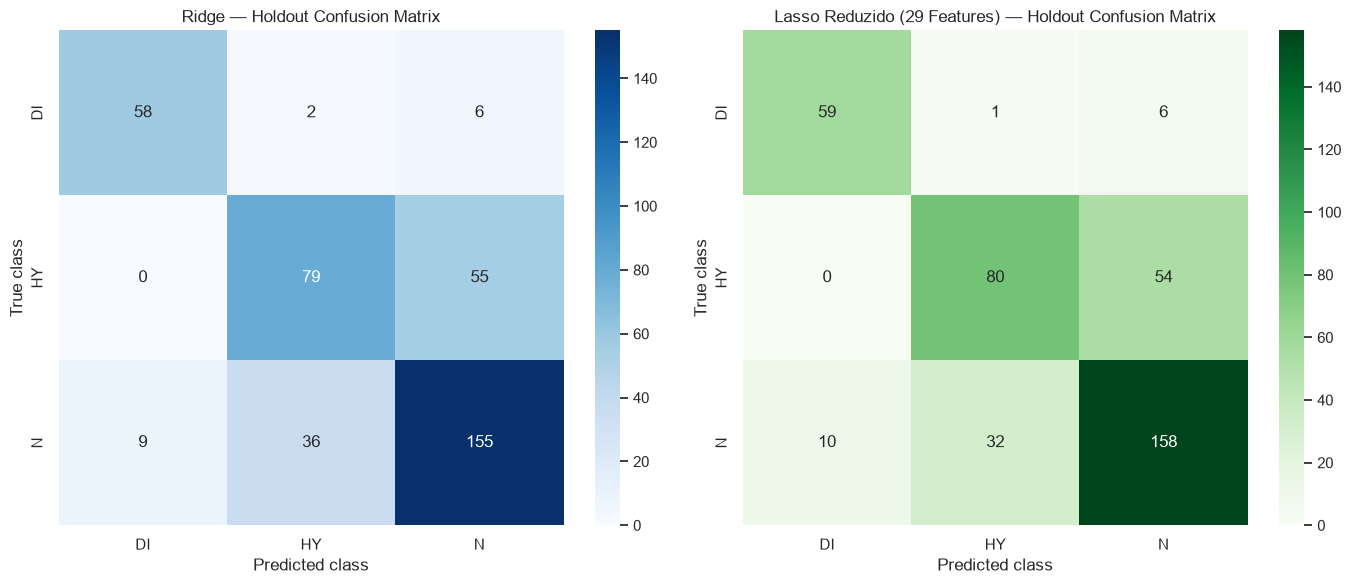

In [130]:
# Criar uma figura com 2 subplots lado a lado
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- 1. Matriz de Confusão: Ridge ---
cm_ridge = confusion_matrix(
    y_test, 
    models_base["Ridge (C=0.2)"].predict(X_test), 
    labels=labels
)

sns.heatmap(
    cm_ridge,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[0]
)
axes[0].set_title("Ridge — Holdout Confusion Matrix")
axes[0].set_xlabel("Predicted class")
axes[0].set_ylabel("True class")

# --- 2. Matriz de Confusão: Lasso Reduzido ---
cm_lasso = confusion_matrix(
    y_test, 
    y_pred_reduced, 
    labels=labels
)

sns.heatmap(
    cm_lasso,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[1]
)
axes[1].set_title("Lasso Reduzido (29 Features) — Holdout Confusion Matrix")
axes[1].set_xlabel("Predicted class")
axes[1].set_ylabel("True class")

plt.tight_layout()
plt.show()

### Análise Detalhada das Matrizes de Confusão

A análise visual das matrizes de confusão confirma os ganhos proporcionados pela seleção de variáveis do Lasso:
- **Aumento dos Acertos (Diagonal Principal):** O modelo Lasso Reduzido consegue melhorar o número de previsões corretas em todas as três classes em comparação com o Ridge (158 vs. 155 na classe N; 80 vs. 79 na classe HY; e 59 vs. 58 na classe DI).
- **Redução de Confusões Críticas:** Verifica-se uma diminuição nos erros de classificação cruzada, nomeadamente na distinção entre indivíduos normais (`N`) e hipertensos/com risco (`HY`), onde o número de falsos prognósticos desceu de 36 para 32. 

Isto demonstra que a remoção das 13 variáveis redundantes eliminou ruído que estava a prejudicar a fronteira de decisão do modelo, tornando-o simultaneamente mais parcimonioso e mais eficaz.

## 6. Discussão dos Resultados (Ridge vs. Lasso)

A análise comparativa entre as abordagens de regularização Ridge e Lasso, tendo por base o desempenho no conjunto de teste, permite retirar as seguintes conclusões:

1. **Impacto da Seleção de Variáveis (Lasso):**
   - A penalização com $C=0.1$ demonstrou uma excelente capacidade de filtragem, reduzindo o espaço de caraterísticas de **42 para 29 variáveis** (uma redução de ~31%). 
   - A remoção de 13 preditores redundantes ou de menor relevância não só simplificou o modelo como resultou numa melhoria prática das métricas de desempenho.

2. **Desempenho Preditivo e Métricas:**
   - O **modelo reduzido (Lasso)** obteve o melhor desempenho global em todas as métricas avaliadas:
     - **Accuracy:** 0.7425 (vs. 0.7300 da Baseline e Ridge)
     - **Balanced Accuracy:** 0.7603 (vs. ~0.7503 da Baseline)
     - **F1 macro:** 0.7593 (vs. ~0.7503 da Baseline)
   - Este resultado comprova que a eliminação de ruído através do Lasso evitou o *overfitting* e otimizou a capacidade de generalização do classificador para dados não vistos.

3. **Comparação com o Modelo Ridge (L2):**
   - O modelo **Ridge ($C=0.2$)** manteve todas as 42 variáveis, obtendo um desempenho prácticamente idêntico ao da Regressão Logística *baseline* (Accuracy de 0.7300 e F1 macro de 0.7490).
   - Isto indica que, embora a regularização de ridge ajude a controlar a magnitude dos coeficientes, a mera penalização proporcional sem remoção de variáveis não trouxe ganhos significativos face à linha de base.

**Conclusão Geral:** O modelo com seleção **Lasso** revelou-se a melhor solução para este problema, pois conseguiu um **ganho efetivo no desempenho preditivo**, ultizando um menor número de variáveis.